# PiMoTIF — simulation and validation code

This notebook implements the **trajectory simulation part** of the PiMoTIF plan:
1. measure simulation parameters from the NB fixed/live data;
2. generate five motion classes with experimental recording effects;
3. validate simulated immobile tracks against fixed-cell tracks;
4. estimate how often the existing sRg cutoff misclassifies simulated moving tracks;
5. check sensitivity to the random seed.

It does **not** train the feature-based, deep-learning, or hybrid classifiers. Those belong in the next stage after the simulation passes validation.

The notebook uses real NB data for parameter pools and blinking patterns. `ROOT` defaults to the lab share; set the environment variable `PIMOTIF_ROOT` to run it anywhere else.

**Where the tracks come from.** Detection is ThunderSTORM (wavelet B-spline filter, scale 2, local maximum at 1.2×std, integrated Gaussian, sigma 1.6, fit radius 3); linking is the lab's FLIKA SPT Batch Analysis plugin, with a 3-pixel (325 nm) jump limit and gaps bridged up to 19 dark frames. This notebook starts from those finished tracks, so detection and linking are upstream of everything here and their errors arrive already baked in — which is why the mis-linking and unresolved-cluster models exist at all.

### Version 2 (24 Oct 2026) — what changed from the 14 Oct notebook

Brought back in line with the plan (`JC_2026_09_29_SimulationPlan`) and George's review (21 Oct). Outputs go to `ML_Analysis/simulations_v2`, so the first version's files are not overwritten.

| | change | why |
|---|---|---|
| bug | corral: each frame is split into sub-steps | a step larger than R was reflected through the centre and clamped onto the wall — up to 90% of positions on the wall at slow frame rates |
| bug | restricted: fGn anchored at the track's own frame time | anchored at 5 ms, a restricted molecule took 0.12× a normal one's step at 100 ms, which a classifier can learn as step size alone |
| bug | unresolved clusters formed before drift | the partner had no drift, so the centroid carried half of it |
| bug | artefact labels record what was done, per record | a short track was labelled mis-linked when nothing happened; every fragment inherited every flag |
| shortcut | every class in a live set borrows LIVE blinking and live σ | immobile tracks borrowed fixed-cell patterns (median 807 vs 458 detections), so length alone pointed to "immobile" |
| plan | mis-linking read off the notebook-04 density curve (0–18%), and the record continues on a neighbour's own motion (a chimera) | the 14% was inferred, not measured (review); the plan defines a mis-link as chimeric |
| plan | unresolved clusters: two emitters, the centroid alternating between them with a dwell time; separations from my stretched fixed tracks, with a 1.5–4× wide minority | the plan's model; the old one sat at a fixed 50/50 average, which adds nothing to an immobile track |
| plan | the plan's seven unmeasurable parameters fitted together to the fixed-cell sRg distribution, with the "wiggle" split into slow drift and a bounded tether wobble (nine in all) | the plan's section 3; before, two were scanned and one (14%) set by hand, and slow drift alone cannot lift the body of the distribution, which my data shows is lifted |
| plan | corral escape (0.003–0.10 per wall hit, 3 in 10 closed); 1 mobile track in 5 from the slow boundary | in the plan, not in the code |
| plan | ranges: duty 0.4–1.0, density 0.02–0.80, length 10–5,000, exposure threshold 0.5; sizes 5,000 immobile + 1,000 per mobile class | as written in the plan |
| measured | σ drifts within a track as measured in my fixed cells; the share of badly fitted detections is held to what my fixed-cell step tails allow | 16.5% of fixed tracks change σ by more than 25% between first and last third |
| gate | 200-detection filter on every comparison with real data; QQ and IQR; six seeds at the gate's own size; as many tracks per field as my real data | like-for-like comparisons; the seed spread was measured at 600 tracks for a 3,000-track gate |
| plan | check 3: the live reference against real NB-Live, side by side, mixed at the composition the live sRg distribution implies; MSD per class; mis-link sensitivity | in the plan, not in the code |
| saved | the true path is saved with every track, and a held-out obstacle set | notebook 02 can compare a feature with what was really there |

In [1]:
# %matplotlib inline
import gc
import os
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.spatial import ConvexHull
from scipy import stats
from scipy.signal import lfilter
from tqdm.auto import tqdm

# the lab share by default; set PIMOTIF_ROOT to run this anywhere else
ROOT  = Path(os.environ.get("PIMOTIF_ROOT",
                            r"Z:/Lab/Jagriti/DATA_EXTRACTED/ALL_FOVS"))
OUT   = ROOT / "ML" / "ML_Analysis" / "simulations_v2"   # v1 files stay as they were
FIG_DIR, TAB_DIR = OUT / "figures", OUT / "tables"
CACHE = Path.home() / ".pimotif_cache"      # the parquets live on the lab share;
                                            # reading them over the network is
                                            # the slowest thing here, so copy once
for d in (OUT, FIG_DIR, TAB_DIR, CACHE):
    d.mkdir(parents=True, exist_ok=True)

# --- NB only -----------------------------------------------------------------
DONOR_FIX  = ["NB-Fix", "NB-Fix_Iono"]   # nothing moves: the immobile donors
DONOR_LIVE = ["NB-Live"]                 # donors for EVERY class in a live set

# --- my microscope, as I actually imaged -------------------------------------
PX_UM, DT_S, N_FRAMES = 0.1082, 0.005, 6000     # 108.2 nm, 5 ms, 30 s
MOVIE_S       = N_FRAMES * DT_S   # 30 s. A movie is a DURATION; the number of
                                  # frames in it follows from the frame time
MIN_TRACK_LEN = 200               # my upstream filter, applied to the real data
MIN_SIM_DET   = 10                # a simulated track may be this short, so the
                                  # library covers short noisy trajectories too

# Blinking itself is MEASURED, not modelled: every simulated track inherits a
# real track's frame pattern. This is something else - it decides whether a
# PARTIAL frame yields a detection when I simulate slower imaging than my own.
EXPOSURE_RANGE = (0.5, 0.5)  # the plan: on for half the frame. ASSUMED - what
                             # really decides it is photon count
                             # against the finder's threshold, and I took
                             # intensity out. At 5 ms it never fires.

# --- deliberate coverage, so the model survives other experiments ------------
DT_RANGE  = (0.005, 0.100)
DT_BANDS  = [(0.005, 0.010), (0.010, 0.040), (0.040, 0.100)]   # s
LEN_BANDS = [(10, 50), (50, 200), (200, 5000)]                 # detections (plan)

SIGMA_RANGE   = (0.015, 0.080)   # um   localisation error
DUTY_RANGE    = (0.4, 1.0)       #      blinking (plan)
DRIFT_SCALE   = (0.5, 3.0)       # x my measured drift
D_SCALE       = (0.3, 3.0)       # x my measured mobile D
CORRAL_SCALE  = (0.5, 3.0)       # x my measured corral radii
DENSITY_RANGE = (0.02, 0.80)     # puncta/um2, drawn log-uniform (plan)
CLUSTER_SCALE = (0.5, 2.0)       # library: x the fitted cluster rate
GAP_MAX       = 19               # frames my linker will bridge. Beyond it
                                 # the record breaks and the molecule starts a
                                 # new track - a property of the software, so
                                 # like R_LINK it gets no range
R_LINK        = 3 * PX_UM        # 325 nm: my tracker's jump limit. A property
                                 # of the software, so it gets no range

# --- the five motion types ---------------------------------------------------
ALPHA_RANGE   = (0.3, 0.9)       # restricted: subdiffusive exponent
LATTICE_NM    = (20.0, 60.0)     # restricted: obstacle spacing. ASSUMED -
                                 # single-particle tracking cannot see this
OBSTACLE_CONC = (0.20, 0.45)     # restricted: fraction of sites blocked
DIRECTEDNESS  = (1.0, 6.0)       # directed: v^2 T / 4D
D_IMMOBILE    = (1e-9, 1.2e-3)   # um2/s, two residual-mobility populations.
                                 # The plan's boundary, kept. Over 3 s it
                                 # spreads ~120 nm rms (about 3 sigma), so the
                                 # reason for it is "below what a 3 s track can
                                 # separate from immobile at my precision".
SLOW_SHARE    = 0.20             # 1 mobile track in 5 from the slow boundary
ESCAPE_P      = (0.003, 0.10)    # corral escape per wall hit (plan)
IMPERMEABLE   = 0.30             # 3 corrals in 10 never let go (plan)

ASPECT_CUT    = 3.0              # longer than this and I call a track stretched
OUTLIER_SCALE = 3.0             # a badly fitted detection is thrown ~3 sigma
                                # (plan); HOW MANY is fitted in section 5
WANDER_FRAC   = 0.5              # how much of the drift wanders vs ramps
PSF_R         = 0.25             # um: closer than this and two spots are one

# sizes from the plan. The library is stratified over 9 band cells.
N_LIB_IMM, N_LIB_MOB = 5000, 1000          # immobile, and per mobile class
N_REF_MOB, N_REF_IMM_LIVE, N_REF_FIX = 1000, 1000, 5000
N_FIT, N_HELDOUT = 3000, 500
SEED = 0
# PIMOTIF_FAST=1 shrinks everything ~10x, for checking the code end to end
FAST = os.environ.get("PIMOTIF_FAST", "0") == "1"
if FAST:
    N_LIB_IMM, N_LIB_MOB = 450, 90
    N_REF_MOB, N_REF_IMM_LIVE, N_REF_FIX, N_FIT, N_HELDOUT = 120, 120, 500, 300, 60
CLASSES = ["normal", "restricted", "corralled", "directed", "immobile"]
COL = {"normal": "#1d4ed8", "restricted": "#0f766e", "corralled": "#7c3aed",
       "directed": "#b45309", "immobile": "#c81e1e"}
C_FIX, C_LIVE, C_SIM = "#64748b", "#1d4ed8", "#b45309"
SQ = np.sqrt(np.pi / 2)

mpl.rcParams.update({
    "font.size": 15,
    "axes.titlesize": 17, "axes.titleweight": "bold",
    "axes.labelsize": 15, "axes.labelweight": "bold",
    "xtick.labelsize": 13, "ytick.labelsize": 13,
    "legend.fontsize": 12, "axes.linewidth": 1.5,
    "figure.titlesize": 21, "figure.titleweight": "bold",
    "savefig.dpi": 130, "figure.facecolor": "white",
    "lines.linewidth": 2.4,
})

def bold_ticks(*axes):
    """matplotlib has no rcParam for tick-label weight, so set it by hand"""
    for ax in axes:
        for t in list(ax.get_xticklabels()) + list(ax.get_yticklabels()):
            t.set_fontweight("bold")

rng_global = np.random.default_rng(SEED)
print("backend:", mpl.get_backend())
print(f"movie {MOVIE_S:.0f} s | {N_FRAMES} frames at {1000*DT_S:.0f} ms | "
      f"pixel {1000*PX_UM:.1f} nm")
print(f"classes: {CLASSES}")

backend: module://matplotlib_inline.backend_inline
movie 30 s | 6000 frames at 5 ms | pixel 108.2 nm
classes: ['normal', 'restricted', 'corralled', 'directed', 'immobile']


## 1. What I measure from my own NB data

| what | where it comes from |
|---|---|
| localisation error | fixed cells — nothing moves, so every step is pure error |
| blinking and track length | the frame pattern of every real track |
| stage drift | how far long-lived tracks shift across a movie |
| diffusion coefficient | the MSD of the mobile live tracks |
| corral radius | live tracks whose MSD rises and then flattens |
| density | detections per frame over the area the molecules cover |

Each simulated track borrows a real track's **frame pattern** — which frames
the molecule was visible in, nothing else. No positions, no intensity. So the
gaps and the lengths are my dye's real behaviour rather than a model of it.

Three things I cannot measure, and say so: the detection threshold, the
obstacle spacing, and whether localisation error holds at slower frame rates.

In [2]:
def load(conditions, what=""):
    """Load tracks while making field and track IDs unique across source files.

    The raw track_gid/fov_uid values may be reused in different conditions or
    fields. Prefixing them here prevents unrelated tracks from being merged
    by later groupby operations.
    """
    out = []
    for c in tqdm(conditions, desc=f"loading {what}", leave=False):
        local = CACHE / f"{c}_tracks.parquet"
        if not local.exists():
            src = ROOT / "combined" / f"{c}_tracks.parquet"
            tqdm.write(f"   copying {c} ({src.stat().st_size/1e6:.0f} MB) once")
            shutil.copy2(src, local)

        d = pd.read_parquet(local, columns=[
            "fov_uid", "track_gid", "frame", "x_um", "y_um", "intensity"])

        # Raw ids repeat between conditions, so a track is identified by the
        # condition, the field and its own id together. Kept as a category: the
        # readable key costs a few bytes per row rather than a Python string,
        # and these tables run to millions of rows.
        d["track_uid"] = (str(c) + "::" + d.fov_uid.astype(str) + "::"
                          + d.track_gid.astype(str)).astype("category")
        d["fov_uid"] = (str(c) + "::" + d.fov_uid.astype(str)).astype("category")
        out.append(d)

    if not out:
        raise ValueError(f"No conditions supplied while loading {what!r}")

    d = pd.concat(out, ignore_index=True)
    # track_gid becomes a NUMBER again. Two tracks share one only if they
    # shared a condition, a field and a raw id, so the identity is exactly the
    # one the unique key gives - but the boundary-finding code throughout this
    # notebook locates tracks with np.diff on a sorted array, which needs
    # arithmetic.
    d["track_gid"] = pd.factorize(d.track_uid, sort=True)[0].astype(np.int64)
    d["frame"] = d.frame.astype(np.int32)
    return d.sort_values(["track_gid", "frame"]).reset_index(drop=True)


real_fix  = load(DONOR_FIX,  "fixed")
real_live = load(DONOR_LIVE, "live")

for name, d in [("fixed", real_fix), ("live", real_live)]:
    n = d.groupby("track_gid").size()
    print(f"{name:5s}  {d.track_gid.nunique():,} tracks | "
          f"{d.fov_uid.nunique()} fields | {len(d):,} detections | "
          f"length median {n.median():.0f}, range {n.min()}-{n.max()}")

loading fixed:   0%|          | 0/2 [00:00<?, ?it/s]

loading live:   0%|          | 0/1 [00:00<?, ?it/s]

fixed  3,025 tracks | 53 fields | 4,355,453 detections | length median 807, range 200-6000
live   2,392 tracks | 27 fields | 1,974,052 detections | length median 458, range 200-5983


In [3]:
fig, axes = plt.subplots(1, 4, figsize=(25, 5.6))

ax = axes[0]
bins = np.logspace(np.log10(200), np.log10(6000), 40)
for d, c, lab in [(real_fix, C_FIX, "fixed"), (real_live, C_LIVE, "live")]:
    n = d.groupby("track_gid").size()
    ax.hist(n, bins=bins, density=True, histtype="step", lw=3, color=c,
            label=f"{lab} (median {n.median():.0f})")
ax.set_xscale("log")
ax.set_xlabel("detections per track"); ax.set_ylabel("density")
ax.set_title("track length")
ax.legend(frameon=False)

ax = axes[1]
for d, c, lab in [(real_fix, C_FIX, "fixed"), (real_live, C_LIVE, "live")]:
    ax.hist(d.groupby("fov_uid").track_gid.nunique(), bins=25,
            histtype="step", lw=3, color=c,
            label=f"{lab} ({d.fov_uid.nunique()} fields)")
ax.set_xlabel("tracks per field"); ax.set_ylabel("fields")
ax.set_title("molecules per field")
ax.legend(frameon=False)

ax = axes[2]
g = real_live.groupby("track_gid").frame.agg(["min", "max"])
ax.scatter(g["min"], g["max"] - g["min"] + 1, s=5, alpha=.2, color=C_LIVE,
           edgecolors="none")
ax.set_xlabel("frame the track starts"); ax.set_ylabel("frames it spans")
ax.set_title("when molecules appear,\nand how long they last", fontsize=15)

ax = axes[3]
for d, c, lab in [(real_fix, C_FIX, "fixed"), (real_live, C_LIVE, "live")]:
    pf = (d.groupby(["fov_uid", "frame"]).size().groupby("frame").mean()
          .sort_index())
    sm = pf.rolling(100, center=True, min_periods=20).mean()
    ax.plot(sm.index * DT_S, sm.to_numpy(), lw=3, color=c, label=lab)
ax.set_xlabel("time into the movie (s)"); ax.set_ylabel("detections per frame")
ax.set_title("bleaching over 30 s")
ax.legend(frameon=False)

bold_ticks(*axes)
fig.suptitle("My real NB data, before anything is simulated", y=1.04)
fig.tight_layout()
fig.savefig(FIG_DIR / "M0_real_data_overview.png", bbox_inches="tight")

### Localisation error

A molecule glued to the coverslip still appears to take a step every frame,
and that step is entirely error. In 2D the mean squared step is 4σ², so
σ = √(⟨step²⟩/4). Only gap-free steps count — a step across a blink spans more
time and would let slow stage drift leak in.

localisation error: median 40.0 nm
   5-95th  23.0-60.1 nm
   full    11.3-95.2 nm (n=3,025)
   library 15-80 nm
   outside the library range: 0.56%

is sigma stable within a track? 2,538 fixed tracks of 300+ detections
   last third / first third: median 1.026, 10-90th 0.840-1.297
   tracks changing by more than 25%: 16.5%
   A median near 1.00 means one sigma per track is a fair model and
   within-track variation does not need simulating. Away from 1.00,
   a rolling window would read that drift as a change of motion.

step tails in my fixed cells (Gaussian: 0.27 / 0.0063 / 0.0001 %): beyond 3 % 0.866, beyond 4 % 0.147, beyond 5 % 0.030
   of the measured spread in log-ratio, 12% is estimator noise;
   the simulation draws sigma(end)/sigma(start) from the rest: 10-90th 0.850-1.278


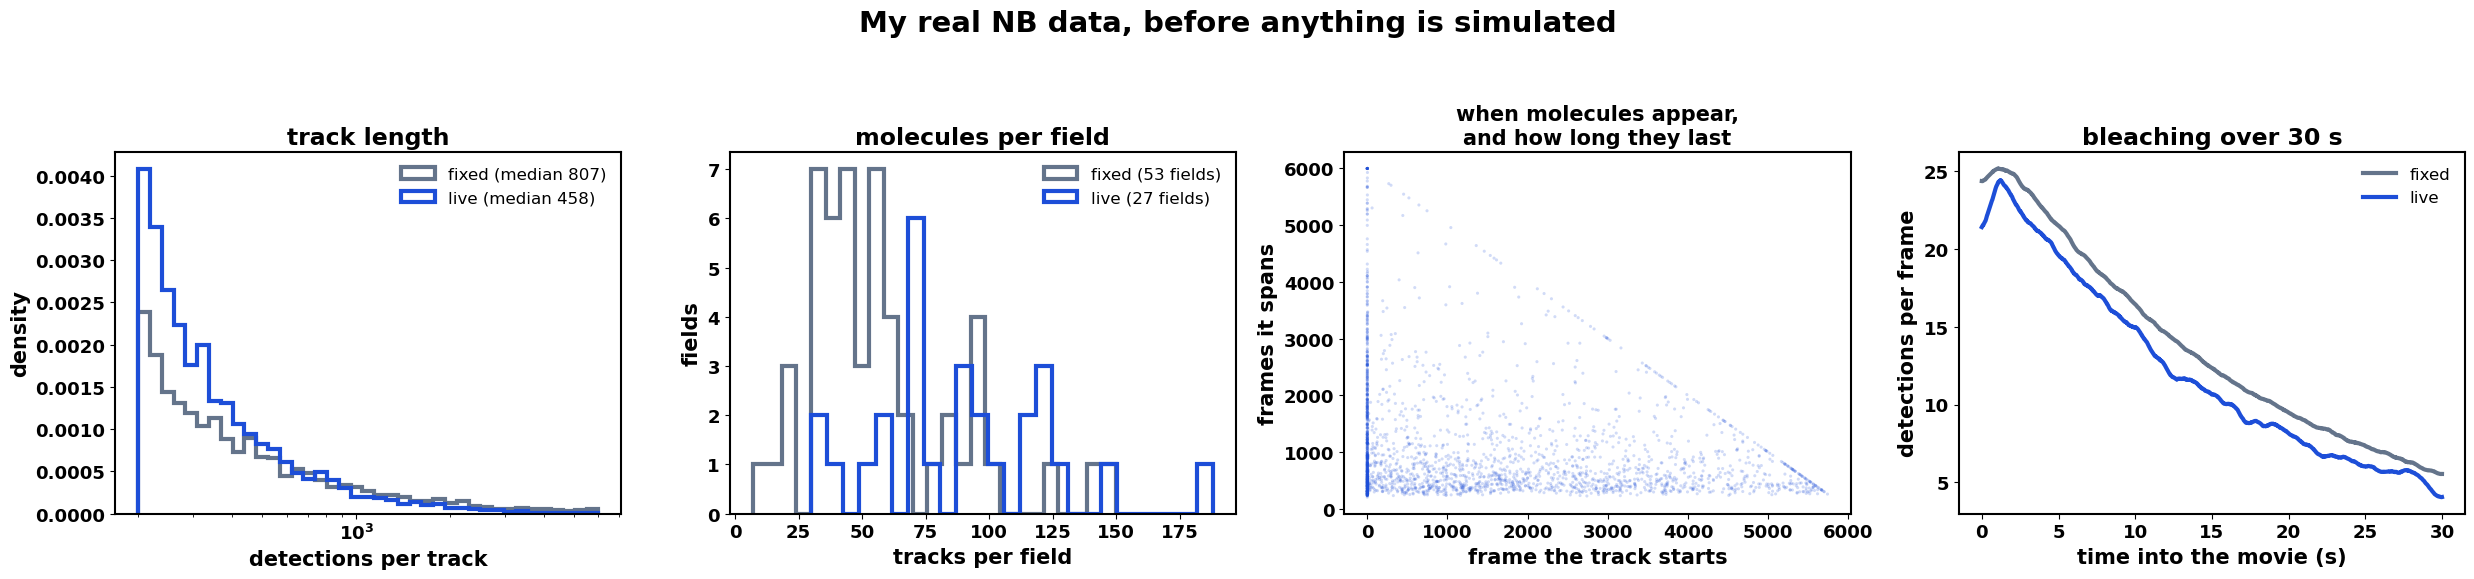

In [4]:
def sigma_per_track(d, min_steps=10):
    """Localisation error per track, from gap-free steps in fixed cells."""
    tid, fr = d.track_gid.to_numpy(), d.frame.to_numpy()
    P = d[["x_um", "y_um"]].to_numpy(np.float64)
    d2 = ((P[1:] - P[:-1]) ** 2).sum(1)
    ok = (tid[1:] == tid[:-1]) & (np.diff(fr) == 1)
    S = (pd.DataFrame({"track_gid": tid[1:][ok], "d2": d2[ok]})
         .groupby("track_gid").d2.agg(mean_d2="mean", n_steps="size"))
    S = S[S.n_steps >= min_steps]
    S["sigma_um"] = np.sqrt(S.mean_d2 / 4)
    meta = d.groupby("track_gid").agg(fov_uid=("fov_uid", "first"),
                                      n_det=("frame", "size"),
                                      intensity=("intensity", "mean"))
    return S.join(meta).reset_index()

SIG_TAB = sigma_per_track(real_fix)
SIGMA   = SIG_TAB.sigma_um.to_numpy()

print(f"localisation error: median {1000*np.median(SIGMA):.1f} nm")
print(f"   5-95th  {1000*np.quantile(SIGMA,.05):.1f}-"
      f"{1000*np.quantile(SIGMA,.95):.1f} nm")
print(f"   full    {1000*SIGMA.min():.1f}-{1000*SIGMA.max():.1f} nm "
      f"(n={len(SIGMA):,})")
print(f"   library {1000*SIGMA_RANGE[0]:.0f}-{1000*SIGMA_RANGE[1]:.0f} nm")
print(f"   outside the library range: "
      f"{100*((SIGMA<SIGMA_RANGE[0])|(SIGMA>SIGMA_RANGE[1])).mean():.2f}%")

# --- is sigma stable WITHIN a track? ----------------------------------------
# The simulation gives each molecule one sigma for its whole life. A molecule
# that dims, bleaches or drifts out of focus would not keep one, and in a
# rolling window a change of sigma looks like a change of motion. My fixed
# cells can answer it: nothing moves there, so sigma measured over the first
# third of a track and over the last third are two measurements of the same
# quantity, and any systematic difference is real.
def sigma_halves(d, min_det=300):
    tid, fr = d.track_gid.to_numpy(), d.frame.to_numpy()
    P = d[["x_um", "y_um"]].to_numpy(np.float64)
    cuts = np.flatnonzero(np.diff(tid)) + 1
    st = np.concatenate([[0], cuts]); en = np.concatenate([cuts, [len(tid)]])
    rows = []
    for s_, e_ in zip(st, en):
        if e_ - s_ < min_det:
            continue
        n = e_ - s_
        out, m = [], []
        for a_, b_ in ((s_, s_ + n // 3), (e_ - n // 3, e_)):
            dd = np.diff(P[a_:b_], axis=0)[np.diff(fr[a_:b_]) == 1]
            out.append(np.sqrt((dd ** 2).sum(1).mean() / 4)
                       if dd.shape[0] >= 10 else np.nan)
            m.append(dd.shape[0])
        if np.isfinite(out).all():
            rows.append({"track_gid": tid[s_], "sigma_first": out[0],
                         "sigma_last": out[1], "n_det": n,
                         "steps_first": m[0], "steps_last": m[1]})
    return pd.DataFrame(rows)

SIG_HALVES = sigma_halves(real_fix)
if len(SIG_HALVES):
    rat = (SIG_HALVES.sigma_last / SIG_HALVES.sigma_first).to_numpy()
    SIG_HALVES.to_csv(TAB_DIR / "sigma_within_track.csv", index=False)
    print()
    print(f"is sigma stable within a track? {len(SIG_HALVES):,} fixed tracks "
          f"of 300+ detections")
    print(f"   last third / first third: median {np.median(rat):.3f}, "
          f"10-90th {np.quantile(rat,.1):.3f}-{np.quantile(rat,.9):.3f}")
    print(f"   tracks changing by more than 25%: "
          f"{100*np.mean(np.abs(rat-1) > .25):.1f}%")
    print("   A median near 1.00 means one sigma per track is a fair model and")
    print("   within-track variation does not need simulating. Away from 1.00,")
    print("   a rolling window would read that drift as a change of motion.")

# --- how heavy-tailed is the error? -------------------------------------------
# Each x step divided by its own track's robust sigma (MAD). A Gaussian error
# puts 0.27% beyond 3 and 0.006% beyond 4; badly fitted detections add a
# tail. This limits how many bad fits the simulation may have - the gate
# compares the same numbers on the simulated fixed cells.
def step_tails(tid, fr, X):
    ok = (tid[1:] == tid[:-1]) & (np.diff(fr) == 1)
    dx = np.diff(X[:, 0])[ok]; k_ = tid[1:][ok]
    srt = np.argsort(k_, kind="stable"); dx, k_ = dx[srt], k_[srt]
    cuts_ = np.flatnonzero(np.diff(k_)) + 1
    z = []
    for seg in np.split(dx, cuts_):
        if seg.size < 20:
            continue
        mad = 1.4826 * np.median(np.abs(seg - np.median(seg)))
        if mad > 0:
            z.append(seg / mad)
    z = np.concatenate(z)
    return {"beyond 3 %": 100 * float(np.mean(np.abs(z) > 3)),
            "beyond 4 %": 100 * float(np.mean(np.abs(z) > 4)),
            "beyond 5 %": 100 * float(np.mean(np.abs(z) > 5))}

TAILS_FIX = step_tails(real_fix.track_gid.to_numpy(), real_fix.frame.to_numpy(),
                       real_fix[["x_um", "y_um"]].to_numpy(np.float64))
print("\nstep tails in my fixed cells (Gaussian: 0.27 / 0.0063 / 0.0001 %): "
      + ", ".join(f"{k} {v:.3f}" for k, v in TAILS_FIX.items()))

# --- the pool the simulation draws from ---------------------------------------
# Part of that spread is only the estimate's own noise: each third's sigma
# comes from a finite number of steps. Var(log sigma_hat) is about 0.375/m for
# m steps (squared steps of one error series overlap, which costs a factor
# ~1.5 over independent ones), so the log-ratio carries 0.375/m1 + 0.375/m2 of
# noise. That is taken out by shrinking the measured log-ratios towards their
# median, so the simulation drifts sigma by what the molecules did, not by
# what my estimator added.
_lr = np.log(rat)
_var_noise = float(np.mean(0.375 / SIG_HALVES.steps_first
                           + 0.375 / SIG_HALVES.steps_last))
_shrink = float(np.sqrt(max(1 - _var_noise / np.var(_lr), 0.0)))
SIG_LOGRATIO = np.median(_lr) + _shrink * (_lr - np.median(_lr))
print(f"   of the measured spread in log-ratio, {100*(1-_shrink**2):.0f}% is "
      f"estimator noise;")
print(f"   the simulation draws sigma(end)/sigma(start) from the rest: 10-90th "
      f"{np.exp(np.quantile(SIG_LOGRATIO,.1)):.3f}-"
      f"{np.exp(np.quantile(SIG_LOGRATIO,.9)):.3f}")

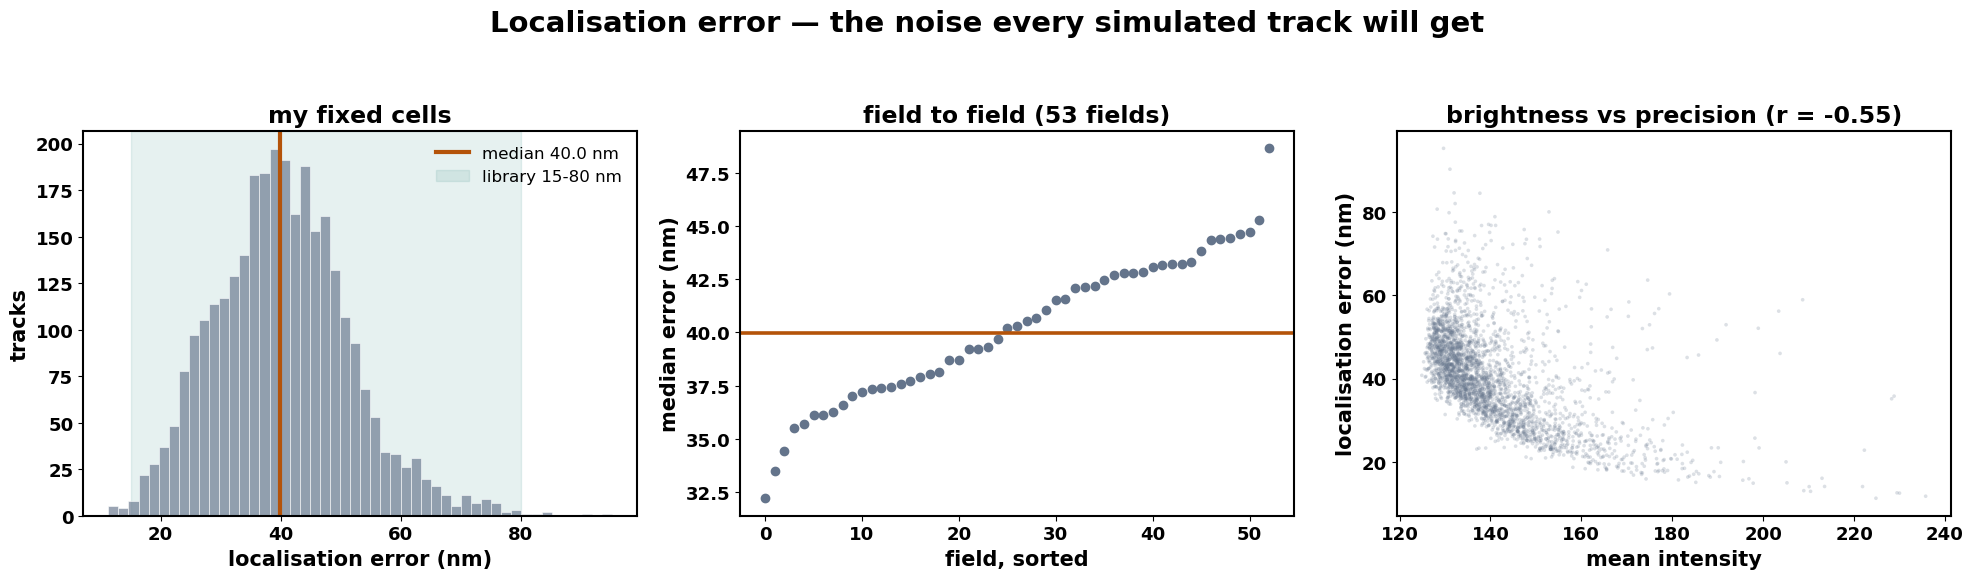

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.6))

ax = axes[0]
ax.hist(1000 * SIGMA, bins=50, color=C_FIX, alpha=.65, edgecolor="white", lw=.6)
ax.axvline(1000 * np.median(SIGMA), color="#b45309", lw=3,
           label=f"median {1000*np.median(SIGMA):.1f} nm")
ax.axvspan(1000 * SIGMA_RANGE[0], 1000 * SIGMA_RANGE[1], color="#0f766e",
           alpha=.10, zorder=0, label="library 15-80 nm")
ax.set_xlabel("localisation error (nm)"); ax.set_ylabel("tracks")
ax.set_title("my fixed cells")
ax.legend(frameon=False)

ax = axes[1]
pf = SIG_TAB.groupby("fov_uid").sigma_um.median().sort_values() * 1000
ax.plot(np.arange(len(pf)), pf.to_numpy(), "o", ms=6, color=C_FIX)
ax.axhline(1000 * np.median(SIGMA), color="#b45309", lw=2.6)
ax.set_xlabel("field, sorted"); ax.set_ylabel("median error (nm)")
ax.set_title(f"field to field ({len(pf)} fields)")

ax = axes[2]
ax.scatter(SIG_TAB.intensity, 1000 * SIG_TAB.sigma_um, s=7, alpha=.22,
           color=C_FIX, edgecolors="none")
r = SIG_TAB[["intensity", "sigma_um"]].corr().iloc[0, 1]
ax.set_xlabel("mean intensity"); ax.set_ylabel("localisation error (nm)")
ax.set_title(f"brightness vs precision (r = {r:.2f})")

bold_ticks(*axes)
fig.suptitle("Localisation error — the noise every simulated track will get",
             y=1.04)
fig.tight_layout()
fig.savefig(FIG_DIR / "M1_localisation_error.png", bbox_inches="tight")

### Blinking — measured, not modelled

Every simulated track inherits a real track's on/off pattern. I never generate
blinking; I only ever *thin* a real pattern to make a molecule blink more.
Adding a detection where the real molecule was dark would be inventing
photophysics I have not observed.

In [6]:
def donors_of(d, desc="donors"):
    """one row per real track, plus its frame pattern as offsets from its start"""
    tid, fr = d.track_gid.to_numpy(), d.frame.to_numpy()
    cuts = np.flatnonzero(np.diff(tid)) + 1
    starts = np.concatenate([[0], cuts])
    ends   = np.concatenate([cuts, [len(tid)]])
    rows, patterns, gaps = [], [], []
    for s, e in tqdm(zip(starts, ends), total=len(starts), desc=desc):
        f = fr[s:e]
        span = int(f[-1] - f[0] + 1)
        rows.append({"track_gid": tid[s], "n_det": e - s, "span": span,
                     "duty": (e - s) / span, "f0": int(f[0])})
        patterns.append((f - f[0]).astype(np.int32))
        g = np.diff(f) - 1
        gaps.append(g[g > 0])
    return (pd.DataFrame(rows), patterns,
            np.concatenate(gaps) if gaps else np.array([]))

FIX,  PAT_FIX,  GAP_FIX  = donors_of(real_fix,  "fixed donors")
LIVE, PAT_LIVE, GAP_LIVE = donors_of(real_live, "live donors")

for name, T, G in [("fixed", FIX, GAP_FIX), ("live", LIVE, GAP_LIVE)]:
    print(f"{name:5s}  duty median {T.duty.median():.3f}  "
          f"5-95th {T.duty.quantile(.05):.3f}-{T.duty.quantile(.95):.3f}  "
          f"min {T.duty.min():.3f}")
    print(f"       dark stretches: median {np.median(G):.0f} frames, "
          f"95th {np.quantile(G,.95):.0f}, longest {G.max()} "
          f"(my tracker gives up after 19)")
print(f"library duty range: {DUTY_RANGE[0]}-{DUTY_RANGE[1]}")

fixed donors:   0%|          | 0/3025 [00:00<?, ?it/s]

live donors:   0%|          | 0/2392 [00:00<?, ?it/s]

fixed  duty median 0.714  5-95th 0.292-0.998  min 0.199
       dark stretches: median 1 frames, 95th 6, longest 18 (my tracker gives up after 19)
live   duty median 0.759  5-95th 0.434-0.960  min 0.241
       dark stretches: median 1 frames, 95th 6, longest 18 (my tracker gives up after 19)
library duty range: 0.4-1.0


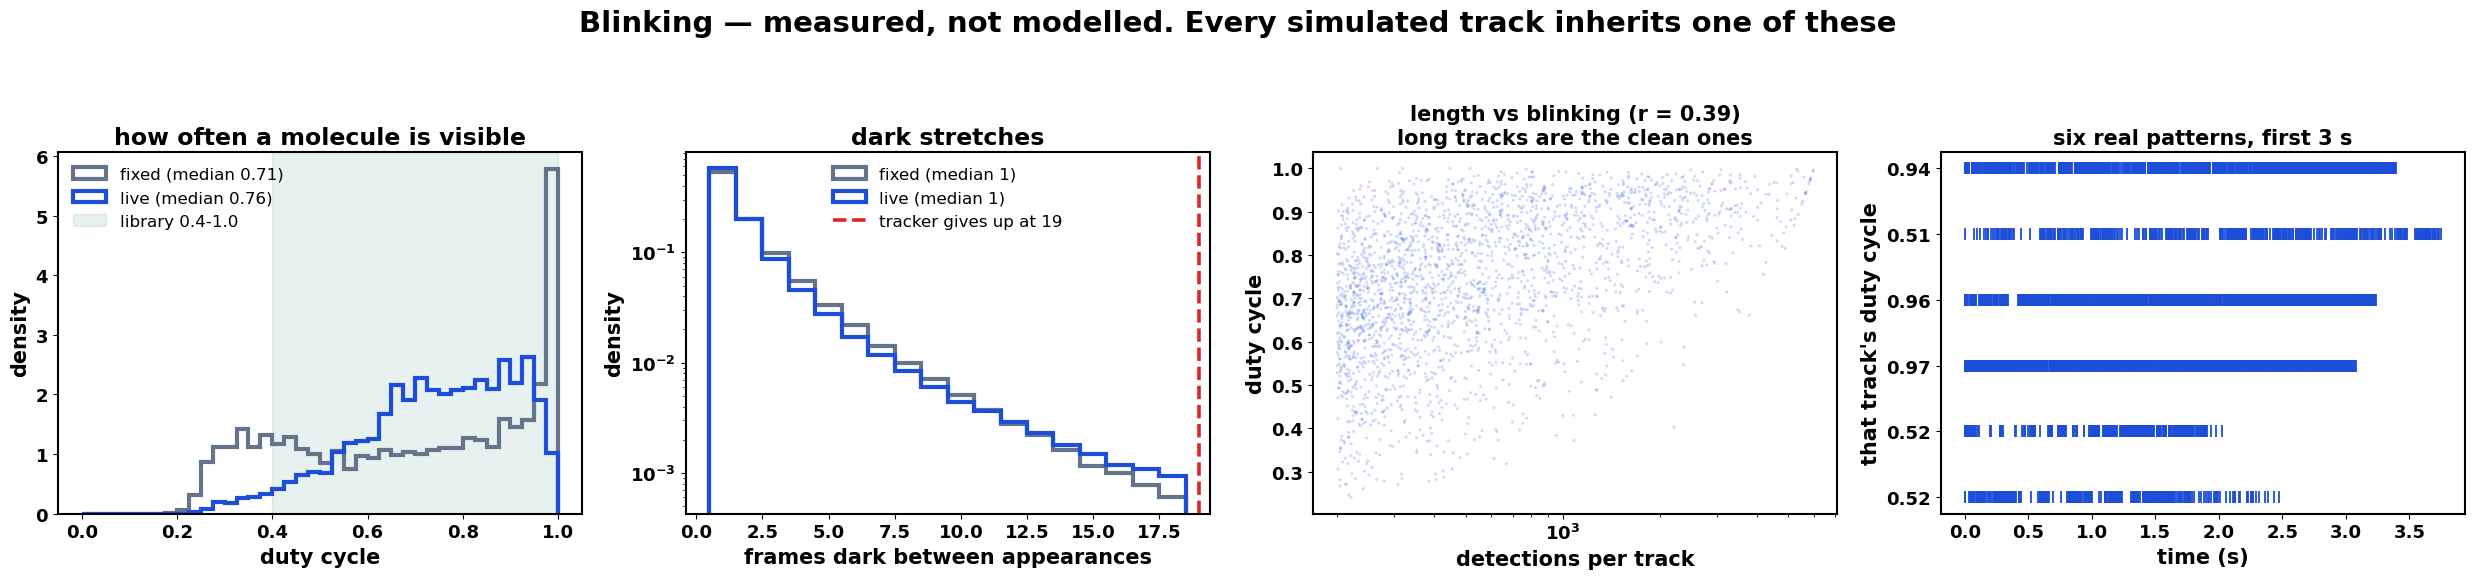

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(25, 5.6))

ax = axes[0]
bins = np.linspace(0, 1, 41)
for T, c, lab in [(FIX, C_FIX, "fixed"), (LIVE, C_LIVE, "live")]:
    ax.hist(T.duty, bins=bins, density=True, histtype="step", lw=3, color=c,
            label=f"{lab} (median {T.duty.median():.2f})")
ax.axvspan(*DUTY_RANGE, color="#0f766e", alpha=.10, zorder=0,
           label=f"library {DUTY_RANGE[0]}-{DUTY_RANGE[1]}")
ax.set_xlabel("duty cycle"); ax.set_ylabel("density")
ax.set_title("how often a molecule is visible")
ax.legend(frameon=False)

ax = axes[1]
mx = int(max(GAP_FIX.max(), GAP_LIVE.max()))
for G, c, lab in [(GAP_FIX, C_FIX, "fixed"), (GAP_LIVE, C_LIVE, "live")]:
    ax.hist(G, bins=np.arange(.5, mx + 1.5), density=True, histtype="step",
            lw=3, color=c, label=f"{lab} (median {np.median(G):.0f})")
ax.axvline(19, color="#dc2626", ls="--", lw=2.6, label="tracker gives up at 19")
ax.set_yscale("log")
ax.set_xlabel("frames dark between appearances"); ax.set_ylabel("density")
ax.set_title("dark stretches")
ax.legend(frameon=False)

ax = axes[2]
ax.scatter(LIVE.n_det, LIVE.duty, s=5, alpha=.2, color=C_LIVE,
           edgecolors="none")
ax.set_xscale("log")
r = LIVE[["n_det", "duty"]].corr().iloc[0, 1]
ax.set_xlabel("detections per track"); ax.set_ylabel("duty cycle")
ax.set_title(f"length vs blinking (r = {r:.2f})\nlong tracks are the clean ones",
             fontsize=15)

ax = axes[3]
pick = rng_global.choice(len(PAT_LIVE), 6, replace=False)
for row, i in enumerate(pick):
    p = PAT_LIVE[i][:600]
    ax.plot(p * DT_S, np.full(p.size, row), "|", ms=9, color=C_LIVE, mew=1.3)
ax.set_yticks(range(6))
ax.set_yticklabels([f"{LIVE.duty.iloc[i]:.2f}" for i in pick])
ax.set_xlabel("time (s)"); ax.set_ylabel("that track's duty cycle")
ax.set_title("six real patterns, first 3 s", fontsize=15)

bold_ticks(*axes)
fig.suptitle("Blinking — measured, not modelled. Every simulated track "
             "inherits one of these", y=1.04)
fig.tight_layout()
fig.savefig(FIG_DIR / "M2_blinking.png", bbox_inches="tight")

### Stage drift

A fixed molecule should sit still, so if every molecule in a field has moved
the same way by the end, that is the stage and not the biology.

In [8]:
def drift_per_field(d, min_det_each=100):
    """median shift of long-lived tracks, first quarter of the movie to last"""
    Q, rows = N_FRAMES // 4, []
    for fov, fd in tqdm(d.groupby("fov_uid"), total=d.fov_uid.nunique(),
                        desc="drift per field"):
        dx, dy = [], []
        for _, s in fd.groupby("track_gid"):
            a, b = s[s.frame < Q], s[s.frame >= N_FRAMES - Q]
            if len(a) >= min_det_each and len(b) >= min_det_each:
                dx.append(b.x_um.mean() - a.x_um.mean())
                dy.append(b.y_um.mean() - a.y_um.mean())
        if dx:
            rows.append({"fov_uid": fov, "n_long": len(dx),
                         "dx_um": np.median(dx), "dy_um": np.median(dy),
                         "drift_um": np.median(np.hypot(dx, dy))})
    return pd.DataFrame(rows)

DRIFT_TAB = drift_per_field(real_fix)
DRIFT     = DRIFT_TAB.drift_um.to_numpy()

print(f"stage drift: median {1000*np.median(DRIFT):.1f} nm/movie, "
      f"range {1000*DRIFT.min():.0f}-{1000*DRIFT.max():.0f} nm "
      f"({len(DRIFT)} fields)")
print(f"   library x{DRIFT_SCALE[0]}-{DRIFT_SCALE[1]} -> "
      f"{1000*DRIFT_SCALE[0]*DRIFT.min():.0f}-"
      f"{1000*DRIFT_SCALE[1]*DRIFT.max():.0f} nm")
print(f"   horizontal {1000*DRIFT_TAB.dx_um.abs().median():.1f} nm vs vertical "
      f"{1000*DRIFT_TAB.dy_um.abs().median():.1f} nm - one axis, not both")
print(f"   {(DRIFT_TAB.dx_um > 0).sum()} of {len(DRIFT_TAB)} fields drift the "
      f"same way in x, so this is the stage creeping, not random wander")

drift per field:   0%|          | 0/53 [00:00<?, ?it/s]

stage drift: median 71.4 nm/movie, range 17-136 nm (52 fields)
   library x0.5-3.0 -> 8-409 nm
   horizontal 65.0 nm vs vertical 13.0 nm - one axis, not both
   46 of 52 fields drift the same way in x, so this is the stage creeping, not random wander


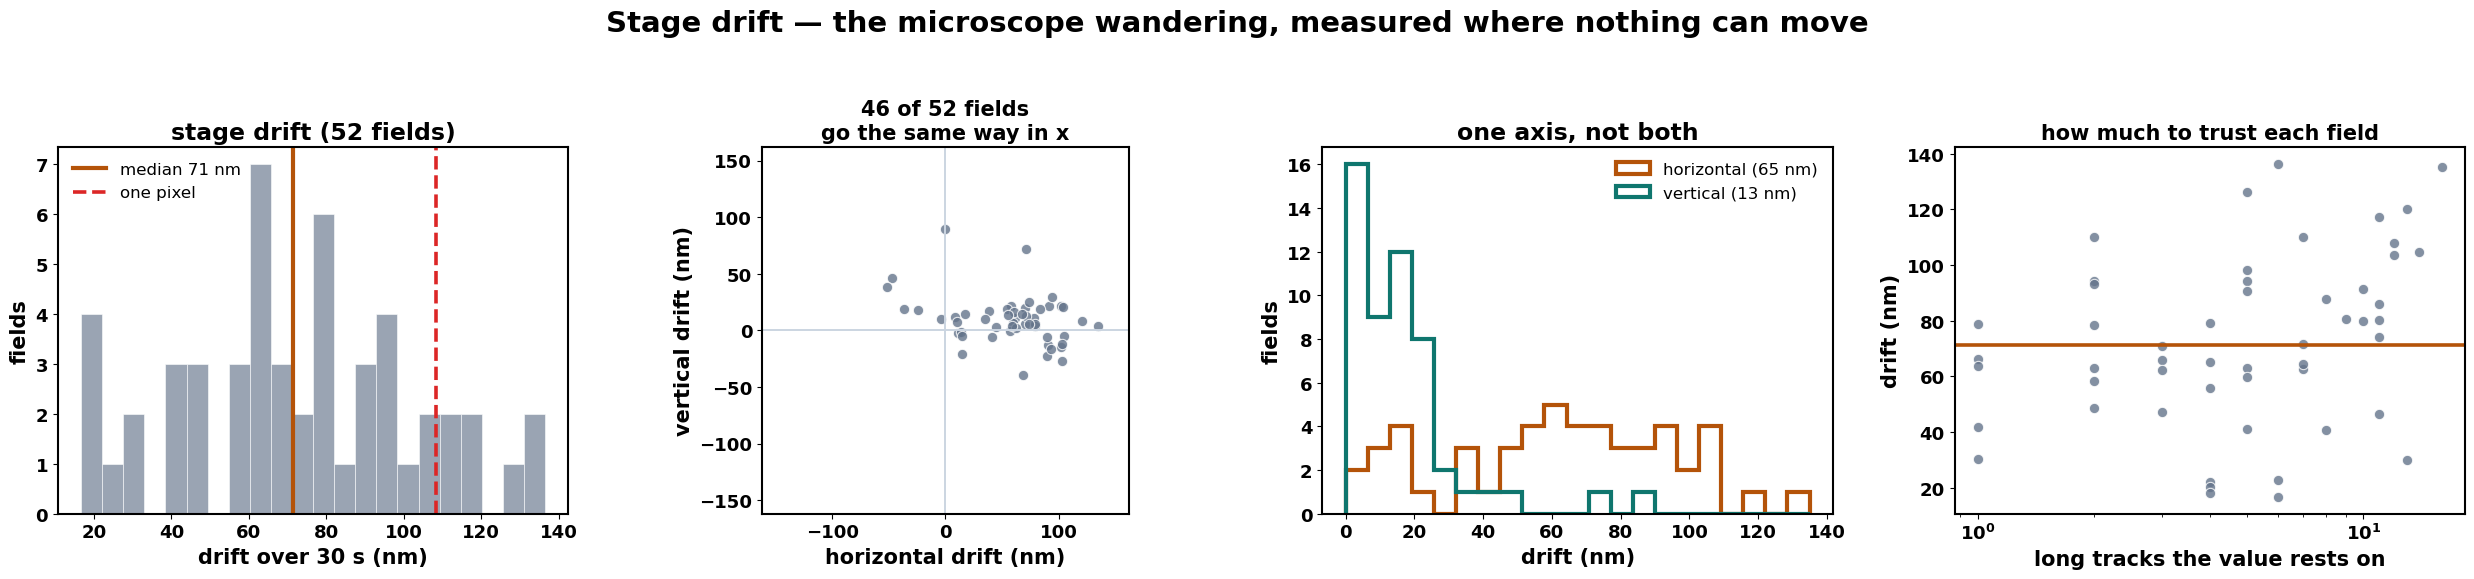

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(25, 5.6))

ax = axes[0]
ax.hist(1000 * DRIFT, bins=22, color=C_FIX, alpha=.65, edgecolor="white", lw=.6)
ax.axvline(1000 * np.median(DRIFT), color="#b45309", lw=3,
           label=f"median {1000*np.median(DRIFT):.0f} nm")
ax.axvline(1000 * PX_UM, color="#dc2626", ls="--", lw=2.6, label="one pixel")
ax.set_xlabel("drift over 30 s (nm)"); ax.set_ylabel("fields")
ax.set_title(f"stage drift ({len(DRIFT)} fields)")
ax.legend(frameon=False)

ax = axes[1]
ax.axhline(0, color="#cbd5e1", lw=1.4); ax.axvline(0, color="#cbd5e1", lw=1.4)
ax.scatter(1000 * DRIFT_TAB.dx_um, 1000 * DRIFT_TAB.dy_um, s=55, color=C_FIX,
           alpha=.8, edgecolors="white", lw=.8)
lim = 1000 * max(DRIFT_TAB.dx_um.abs().max(), DRIFT_TAB.dy_um.abs().max()) * 1.2
ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal")
ax.set_xlabel("horizontal drift (nm)"); ax.set_ylabel("vertical drift (nm)")
ax.set_title(f"{(DRIFT_TAB.dx_um>0).sum()} of {len(DRIFT_TAB)} fields\n"
             "go the same way in x", fontsize=15)

ax = axes[2]
bins = np.linspace(0, 1000 * max(DRIFT_TAB.dx_um.abs().max(),
                                 DRIFT_TAB.dy_um.abs().max()), 22)
ax.hist(1000 * DRIFT_TAB.dx_um.abs(), bins=bins, histtype="step", lw=3,
        color="#b45309",
        label=f"horizontal ({1000*DRIFT_TAB.dx_um.abs().median():.0f} nm)")
ax.hist(1000 * DRIFT_TAB.dy_um.abs(), bins=bins, histtype="step", lw=3,
        color="#0f766e",
        label=f"vertical ({1000*DRIFT_TAB.dy_um.abs().median():.0f} nm)")
ax.set_xlabel("drift (nm)"); ax.set_ylabel("fields")
ax.set_title("one axis, not both")
ax.legend(frameon=False)

ax = axes[3]
ax.scatter(DRIFT_TAB.n_long, 1000 * DRIFT_TAB.drift_um, s=55, color=C_FIX,
           alpha=.8, edgecolors="white", lw=.8)
ax.axhline(1000 * np.median(DRIFT), color="#b45309", lw=2.6)
ax.set_xscale("log")
ax.set_xlabel("long tracks the value rests on"); ax.set_ylabel("drift (nm)")
ax.set_title("how much to trust each field", fontsize=15)

bold_ticks(*axes)
fig.suptitle("Stage drift — the microscope wandering, measured where nothing "
             "can move", y=1.04)
fig.tight_layout()
fig.savefig(FIG_DIR / "M3_stage_drift.png", bbox_inches="tight")

### sRg, and my own cutoff

sRg = √(π/2) · Rg / mean step. Exactly 1.000 for a molecule that cannot move,
at any frame rate and any localisation error — both the top and the bottom of
the fraction scale the same way. That is why it transfers between experiments
where an absolute distance does not.

These three numbers are the gate: the simulated immobile tracks have to
reproduce them.

In [10]:
def srg_table(d, min_det=MIN_TRACK_LEN, desc="sRg"):
    """sRg, Rg, step and aspect ratio for every track long enough to measure"""
    tid, fr = d.track_gid.to_numpy(), d.frame.to_numpy()
    P = d[["x_um", "y_um"]].to_numpy(np.float64)
    cuts = np.flatnonzero(np.diff(tid)) + 1
    starts = np.concatenate([[0], cuts]); ends = np.concatenate([cuts, [len(tid)]])
    rows = []
    for s, e in tqdm(zip(starts, ends), total=len(starts), desc=desc):
        if e - s < min_det:
            continue
        p, f = P[s:e], fr[s:e]
        step = np.linalg.norm(np.diff(p, axis=0)[np.diff(f) == 1], axis=1)
        if step.size < 2:
            continue
        c = p - p.mean(0)
        Rg = np.sqrt((c ** 2).sum(1).mean())
        # "stretched": far longer than wide. In a fixed cell that means two
        # molecules linked into one track, not a molecule that travelled.
        lam = np.clip(np.linalg.eigvalsh(np.cov(c.T)), 1e-12, None)
        w = np.sqrt(lam)
        # two sites at +-d/2 along one axis, visited half the time each, add
        # d^2/4 to the variance along that axis and nothing across it; the
        # localisation error adds the same to both, so it cancels here
        rows.append({"track_gid": tid[s], "n_det": e - s,
                     "sRg": SQ * Rg / step.mean(), "Rg_um": Rg,
                     "step_um": step.mean(), "aspect": w[1] / w[0],
                     "sep_um": 2 * np.sqrt(max(lam[1] - lam[0], 0.0))})
    return pd.DataFrame(rows)

R_FIX  = srg_table(real_fix,  desc="sRg fixed")
R_LIVE = srg_table(real_live, desc="sRg live")
CUTOFF    = float(R_FIX.sRg.quantile(.95))
STRETCHED = 100 * float((R_FIX.aspect > ASPECT_CUT).mean())
TARGET = {"median sRg": float(R_FIX.sRg.median()),
          "95th percentile": CUTOFF, "stretched %": STRETCHED}

print("my real fixed data - the three numbers the simulation must reproduce:")
for k, v in TARGET.items():
    print(f"   {k:18s} {v:.4f}")
print(f"   n = {len(R_FIX):,} fixed tracks")
print()
# --- unresolved clusters: how far apart the two emitters sit ----------------
# Measured on the stretched fixed tracks, where the second emitter shows. The
# simulation scales this pool (fitted) and adds a wide minority (fitted).
CLUSTER_SEP = R_FIX.loc[R_FIX.aspect > ASPECT_CUT, "sep_um"].to_numpy()
print(f"cluster separation, {CLUSTER_SEP.size} stretched fixed tracks: median "
      f"{1000*np.median(CLUSTER_SEP):.0f} nm, 10-90th "
      f"{1000*np.quantile(CLUSTER_SEP,.1):.0f}-"
      f"{1000*np.quantile(CLUSTER_SEP,.9):.0f} nm (plan: 325 nm)")
print(f"99th percentile of fixed sRg: {R_FIX.sRg.quantile(.99):.3f} "
      f"(plan: 5.21) - the far tail the cluster model has to reach")
print()
print(f"applying that cutoff to my live data: "
      f"{100*(R_LIVE.sRg <= CUTOFF).mean():.1f}% immobile "
      f"({int((R_LIVE.sRg <= CUTOFF).sum()):,} of {len(R_LIVE):,})")

sRg fixed:   0%|          | 0/3025 [00:00<?, ?it/s]

sRg live:   0%|          | 0/2392 [00:00<?, ?it/s]

my real fixed data - the three numbers the simulation must reproduce:
   median sRg         1.1032
   95th percentile    2.7310
   stretched %        6.9091
   n = 3,025 fixed tracks

cluster separation, 209 stretched fixed tracks: median 318 nm, 10-90th 194-489 nm (plan: 325 nm)
99th percentile of fixed sRg: 5.099 (plan: 5.21) - the far tail the cluster model has to reach

applying that cutoff to my live data: 23.4% immobile (559 of 2,392)


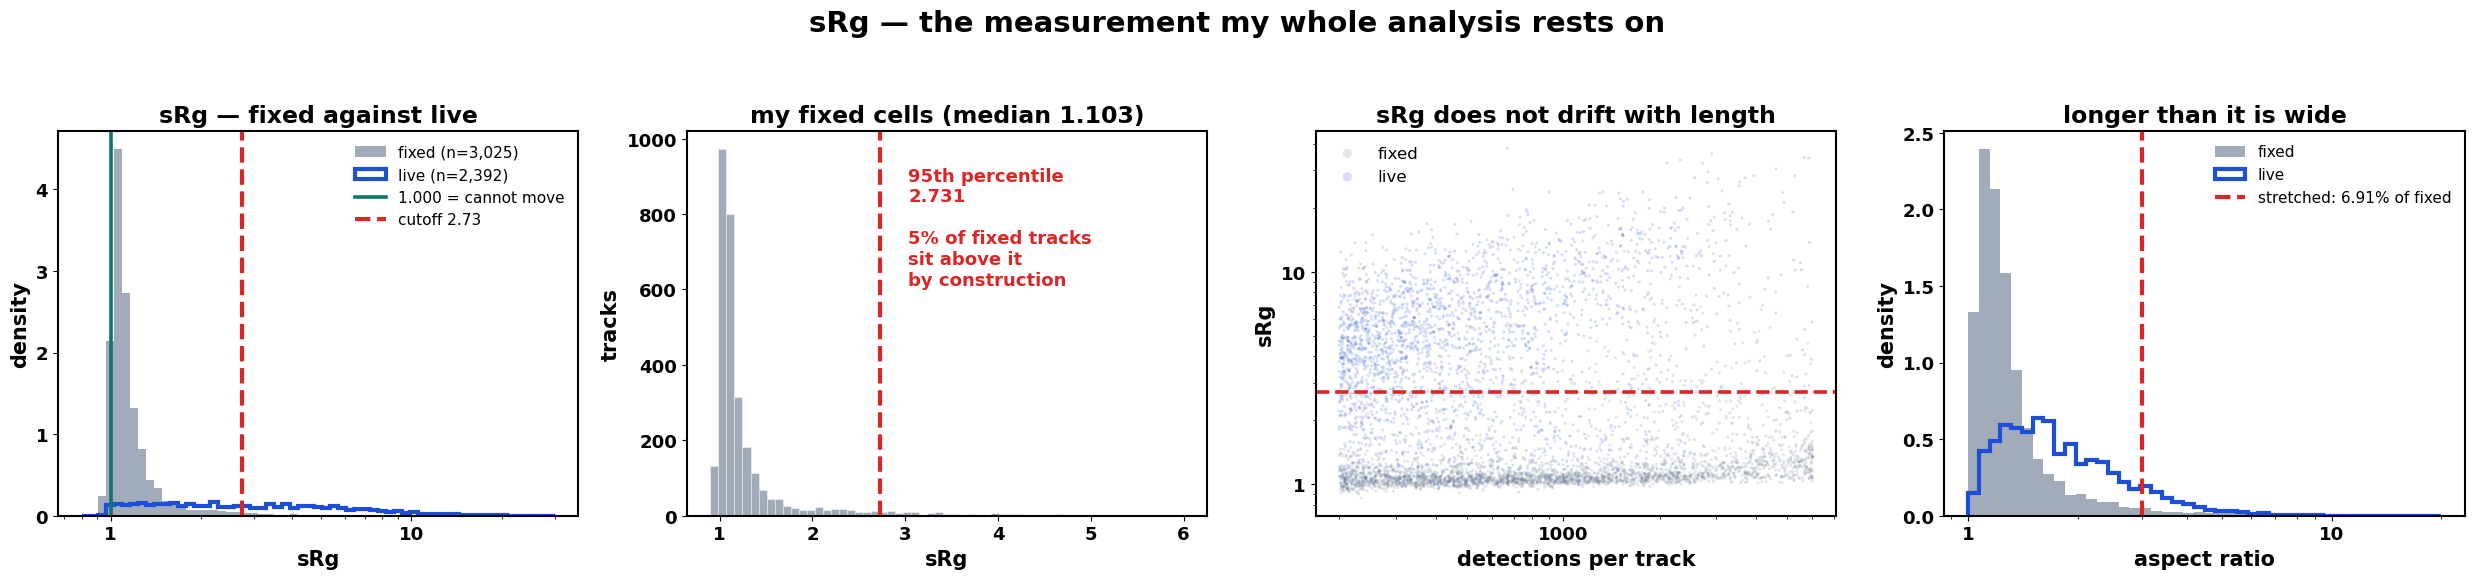

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(25, 5.6))
fmt = mpl.ticker.FuncFormatter(lambda v, _: f"{v:g}")

ax = axes[0]
bins = np.logspace(np.log10(0.8), np.log10(30), 60)
ax.hist(R_FIX.sRg, bins=bins, density=True, color=C_FIX, alpha=.6,
        label=f"fixed (n={len(R_FIX):,})")
ax.hist(R_LIVE.sRg, bins=bins, density=True, histtype="step", lw=3,
        color=C_LIVE, label=f"live (n={len(R_LIVE):,})")
ax.axvline(1.0, color="#0f766e", lw=2.6, label="1.000 = cannot move")
ax.axvline(CUTOFF, color="#dc2626", ls="--", lw=3, label=f"cutoff {CUTOFF:.2f}")
ax.set_xscale("log"); ax.xaxis.set_major_formatter(fmt)
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.set_xlabel("sRg"); ax.set_ylabel("density")
ax.set_title("sRg — fixed against live")
ax.legend(fontsize=11, frameon=False)

ax = axes[1]
ax.hist(R_FIX.sRg, bins=np.linspace(0.9, 6, 60), color=C_FIX, alpha=.6,
        edgecolor="white", lw=.5)
ax.axvline(CUTOFF, color="#dc2626", ls="--", lw=3)
ax.text(CUTOFF + .3, ax.get_ylim()[1] * .6,
        f"95th percentile\n{CUTOFF:.3f}\n\n5% of fixed tracks\nsit above it\n"
        f"by construction", color="#dc2626", fontsize=13, fontweight="bold")
ax.set_xlabel("sRg"); ax.set_ylabel("tracks")
ax.set_title(f"my fixed cells (median {R_FIX.sRg.median():.3f})")

ax = axes[2]
ax.scatter(R_FIX.n_det, R_FIX.sRg, s=5, alpha=.18, color=C_FIX,
           edgecolors="none", label="fixed")
ax.scatter(R_LIVE.n_det, R_LIVE.sRg, s=5, alpha=.18, color=C_LIVE,
           edgecolors="none", label="live")
ax.axhline(CUTOFF, color="#dc2626", ls="--", lw=2.6)
ax.set_xscale("log"); ax.set_yscale("log")
ax.xaxis.set_major_formatter(fmt); ax.yaxis.set_major_formatter(fmt)
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.set_xlabel("detections per track"); ax.set_ylabel("sRg")
ax.set_title("sRg does not drift with length")
ax.legend(frameon=False, markerscale=3)

ax = axes[3]
bins = np.logspace(0, np.log10(20), 45)
ax.hist(R_FIX.aspect, bins=bins, density=True, color=C_FIX, alpha=.6,
        label="fixed")
ax.hist(R_LIVE.aspect, bins=bins, density=True, histtype="step", lw=3,
        color=C_LIVE, label="live")
ax.axvline(ASPECT_CUT, color="#dc2626", ls="--", lw=3,
           label=f"stretched: {STRETCHED:.2f}% of fixed")
ax.set_xscale("log"); ax.xaxis.set_major_formatter(fmt)
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.set_xlabel("aspect ratio"); ax.set_ylabel("density")
ax.set_title("longer than it is wide")
ax.legend(fontsize=11, frameon=False)

bold_ticks(*axes)
fig.suptitle("sRg — the measurement my whole analysis rests on", y=1.04)
fig.tight_layout()
fig.savefig(FIG_DIR / "M4_srg_and_cutoff.png", bbox_inches="tight")

### Diffusion coefficient

Fitted as MSD = 4Dt + 4σ² over lags 1–8, so that D is not inflated by
localisation noise — the noise goes into the intercept and the motion into
the slope. Only tracks above my cutoff go into the pool; the immobile ones
would drag it down.

In [12]:
def fitted_D(fr, P, max_lag=8):
    """D and the noise floor, from the MSD over short lags. Gap-aware."""
    f0 = fr[0]
    span = int(fr[-1] - f0 + 1)
    A = np.full((span, 2), np.nan)
    A[fr - f0] = P
    lags, msd = [], []
    for k in range(1, min(max_lag, span - 1) + 1):
        dd = A[k:] - A[:-k]
        dd = dd[np.isfinite(dd).all(1)]
        if dd.shape[0] >= 20:
            lags.append(k); msd.append((dd ** 2).sum(1).mean())
    if len(lags) < 4:
        return np.nan, np.nan
    slope, icpt = np.polyfit(np.array(lags) * DT_S, np.array(msd), 1)
    return slope / 4, np.sqrt(max(icpt, 0) / 4)

tid = real_live.track_gid.to_numpy(); fr_ = real_live.frame.to_numpy()
P_ = real_live[["x_um", "y_um"]].to_numpy(np.float64)
cuts = np.flatnonzero(np.diff(tid)) + 1
starts = np.concatenate([[0], cuts]); ends = np.concatenate([cuts, [len(tid)]])
rows = []
for s, e in tqdm(zip(starts, ends), total=len(starts), desc="D per track"):
    if e - s < MIN_TRACK_LEN:
        continue
    D, sig = fitted_D(fr_[s:e], P_[s:e])
    rows.append({"track_gid": tid[s], "D": D, "sigma_fit": sig, "n_det": e - s})
D_TAB  = pd.DataFrame(rows).merge(R_LIVE[["track_gid", "sRg"]], on="track_gid")
D_POOL = D_TAB[(D_TAB.sRg > CUTOFF) & (D_TAB.D > 0)].D.to_numpy()

print(f"mobile tracks: {len(D_POOL):,} of {len(D_TAB):,} "
      f"(sRg above {CUTOFF:.3f})")
print(f"   D median {np.median(D_POOL):.4f} um2/s, "
      f"5-95th {np.quantile(D_POOL,.05):.4f}-{np.quantile(D_POOL,.95):.4f}")
print(f"   library x{D_SCALE[0]}-{D_SCALE[1]} -> "
      f"{D_SCALE[0]*np.quantile(D_POOL,.05):.4f}-"
      f"{D_SCALE[1]*np.quantile(D_POOL,.95):.4f}")
print(f"   the fit's own noise estimate: {1000*np.nanmedian(D_TAB.sigma_fit):.1f}"
      f" nm, against {1000*np.median(SIGMA):.1f} nm from fixed cells - two")
print(f"   independent measurements agreeing to about 10%")

# Live tracks get the LIVE localisation error. The plan gives 35.3 nm for live
# against 38.9 fixed; giving moving molecules the fixed-cell noise pulls their
# sRg towards 1 and inflates every "called immobile" number. The pool is the
# intercept of the fit above, on every live track it worked for.
SIGMA_LIVE = D_TAB.sigma_fit.dropna().to_numpy()
SIGMA_LIVE = SIGMA_LIVE[SIGMA_LIVE > 0.005]
print(f"live localisation-error pool: median {1000*np.median(SIGMA_LIVE):.1f} nm "
      f"(n={SIGMA_LIVE.size:,}), fixed {1000*np.median(SIGMA):.1f} nm")

D per track:   0%|          | 0/2392 [00:00<?, ?it/s]

mobile tracks: 1,833 of 2,392 (sRg above 2.731)
   D median 0.1180 um2/s, 5-95th 0.0278-0.2762
   library x0.3-3.0 -> 0.0083-0.8285
   the fit's own noise estimate: 36.0 nm, against 40.0 nm from fixed cells - two
   independent measurements agreeing to about 10%
live localisation-error pool: median 36.1 nm (n=2,383), fixed 40.0 nm


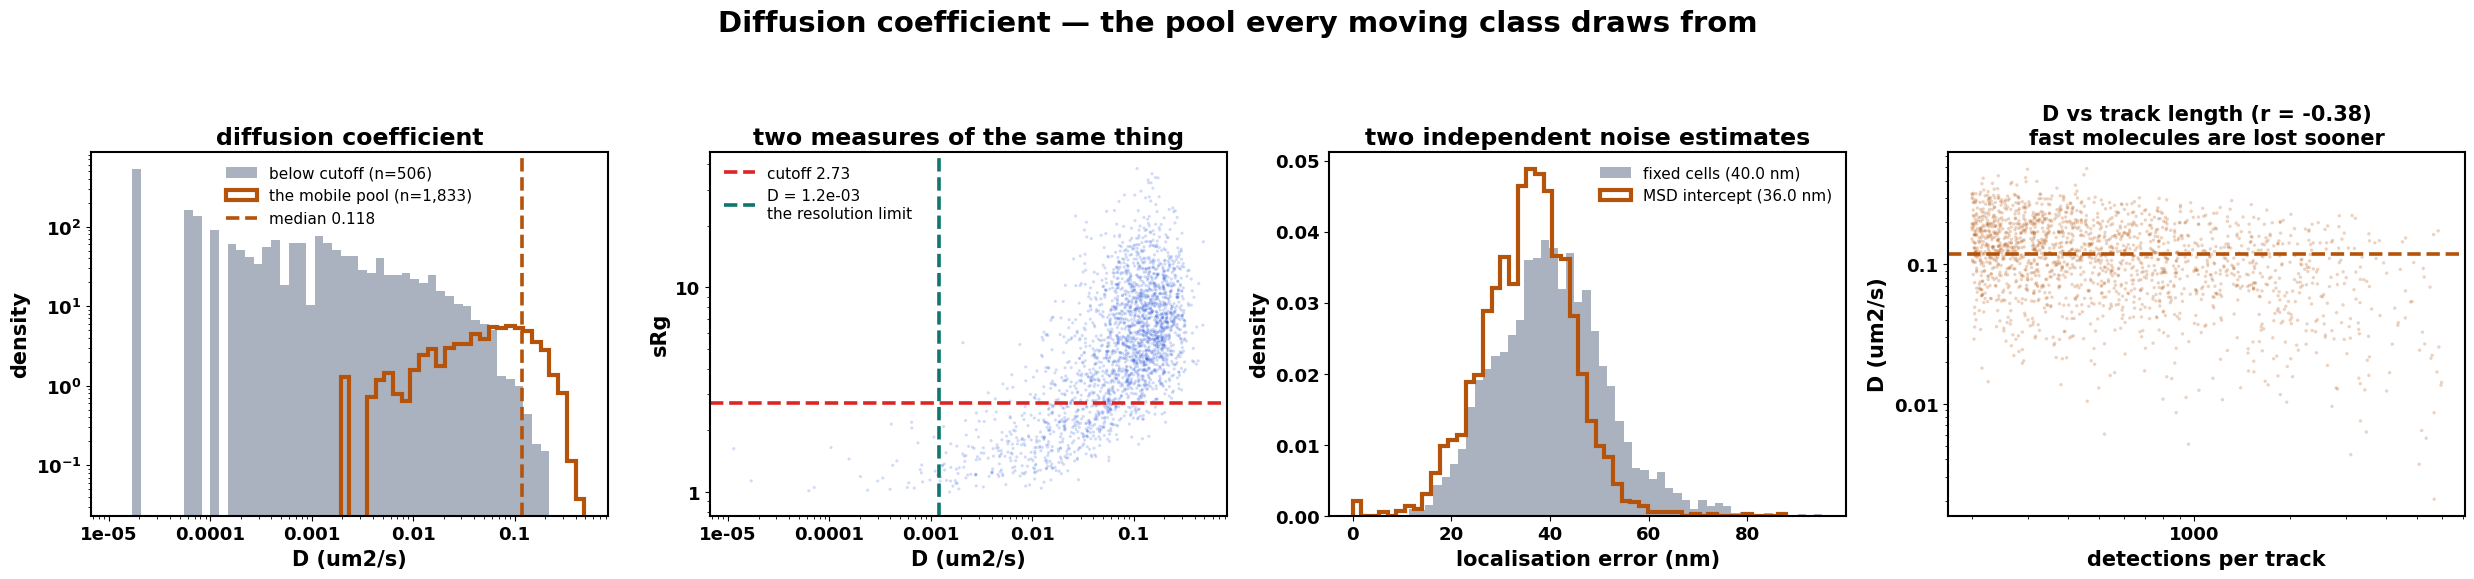

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(25, 5.6))
mobm = D_TAB[(D_TAB.sRg > CUTOFF) & (D_TAB.D > 0)]
immm = D_TAB[(D_TAB.sRg <= CUTOFF) & (D_TAB.D > 0)]

ax = axes[0]
bins = np.logspace(np.log10(max(D_TAB.D[D_TAB.D > 0].min(), 1e-5)),
                   np.log10(D_TAB.D.max()), 55)
ax.hist(immm.D, bins=bins, density=True, color=C_FIX, alpha=.55,
        label=f"below cutoff (n={len(immm):,})")
ax.hist(mobm.D, bins=bins, density=True, histtype="step", lw=3, color=C_SIM,
        label=f"the mobile pool (n={len(mobm):,})")
ax.axvline(np.median(D_POOL), color=C_SIM, ls="--", lw=2.6,
           label=f"median {np.median(D_POOL):.3f}")
ax.set_xscale("log"); ax.set_yscale("log")
ax.xaxis.set_major_formatter(fmt)
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.set_xlabel("D (um2/s)"); ax.set_ylabel("density")
ax.set_title("diffusion coefficient")
ax.legend(fontsize=11, frameon=False)

ax = axes[1]
ax.scatter(D_TAB.D, D_TAB.sRg, s=5, alpha=.2, color=C_LIVE, edgecolors="none")
ax.axhline(CUTOFF, color="#dc2626", ls="--", lw=2.6, label=f"cutoff {CUTOFF:.2f}")
ax.axvline(D_IMMOBILE[1], color="#0f766e", ls="--", lw=2.6,
           label=f"D = {D_IMMOBILE[1]:.1e}\nthe resolution limit")
ax.set_xscale("log"); ax.set_yscale("log")
ax.xaxis.set_major_formatter(fmt); ax.yaxis.set_major_formatter(fmt)
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.set_xlabel("D (um2/s)"); ax.set_ylabel("sRg")
ax.set_title("two measures of the same thing")
ax.legend(fontsize=11, frameon=False)

ax = axes[2]
ax.hist(1000 * SIGMA, bins=50, density=True, color=C_FIX, alpha=.55,
        label=f"fixed cells ({1000*np.median(SIGMA):.1f} nm)")
ax.hist(1000 * D_TAB.sigma_fit.dropna(), bins=50, density=True,
        histtype="step", lw=3, color=C_SIM,
        label=f"MSD intercept ({1000*np.nanmedian(D_TAB.sigma_fit):.1f} nm)")
ax.set_xlabel("localisation error (nm)"); ax.set_ylabel("density")
ax.set_title("two independent noise estimates")
ax.legend(fontsize=11, frameon=False)

ax = axes[3]
ax.scatter(mobm.n_det, mobm.D, s=6, alpha=.25, color=C_SIM, edgecolors="none")
ax.axhline(np.median(D_POOL), color=C_SIM, ls="--", lw=2.6)
ax.set_xscale("log"); ax.set_yscale("log")
ax.xaxis.set_major_formatter(fmt); ax.yaxis.set_major_formatter(fmt)
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
r = np.corrcoef(np.log(mobm.n_det), np.log(mobm.D))[0, 1]
ax.set_xlabel("detections per track"); ax.set_ylabel("D (um2/s)")
ax.set_title(f"D vs track length (r = {r:.2f})\nfast molecules are lost sooner",
             fontsize=15)

bold_ticks(*axes)
fig.suptitle("Diffusion coefficient — the pool every moving class draws from",
             y=1.04)
fig.tight_layout()
fig.savefig(FIG_DIR / "M5_diffusion.png", bbox_inches="tight")

### Corral radius

A molecule free to diffuse has an MSD that keeps rising. One held inside a
corral rises and then flattens, and the height it flattens at is the size of
the space. Localisation error adds a constant 4σ² to every point, so that
comes off; and a track flattening *at* the noise floor is immobile rather than
corralled, so the plateau has to clear twice the noise to count.

That requirement is also the blind spot: a corral tighter than about 2σ cannot
be seen at all.

In [14]:
def corral_pool(d, sigma_um, min_det=MIN_TRACK_LEN):
    """corral size from the plateau of each track's own MSD"""
    tid, fr = d.track_gid.to_numpy(), d.frame.to_numpy()
    P = d[["x_um", "y_um"]].to_numpy(np.float64)
    cuts = np.flatnonzero(np.diff(tid)) + 1
    starts = np.concatenate([[0], cuts]); ends = np.concatenate([cuts, [len(tid)]])
    noise, rows = 4 * sigma_um ** 2, []
    for s, e in tqdm(zip(starts, ends), total=len(starts), desc="corral sizes"):
        if e - s < min_det:
            continue
        f, p = fr[s:e], P[s:e]
        f0, span = f[0], int(f[-1] - f[0] + 1)
        A = np.full((span, 2), np.nan)
        A[f - f0] = p
        lags = np.unique(np.round(
            np.logspace(0, np.log10(max(8, span // 4)), 25)).astype(int))
        lags = lags[lags < span]
        msd = []
        for k in lags:
            dd = A[k:] - A[:-k]
            dd = dd[np.isfinite(dd).all(1)]
            msd.append((dd ** 2).sum(1).mean() if dd.shape[0] >= 20 else np.nan)
        msd = np.array(msd); ok = np.isfinite(msd)
        if ok.sum() < 8:
            continue
        m = msd[ok]
        late = m[int(.75 * len(m)):].mean()
        mid  = m[int(.40 * len(m)):int(.75 * len(m))].mean()
        rows.append({"track_gid": tid[s], "n_det": e - s, "plateau": late,
                     "flat": late < 1.25 * mid, "above_noise": late > 2 * noise,
                     "R_um": np.sqrt(late - noise) if late > noise else np.nan})
    return pd.DataFrame(rows)

CORRAL_TAB = corral_pool(real_live, float(np.median(SIGMA)))
keep = CORRAL_TAB.flat & CORRAL_TAB.above_noise & CORRAL_TAB.R_um.notna()
CORRAL = CORRAL_TAB.loc[keep, "R_um"].to_numpy()

print(f"{len(CORRAL_TAB):,} tracks examined")
print(f"   stopped rising:        {int(CORRAL_TAB.flat.sum()):,}")
print(f"   and cleared the noise: {len(CORRAL):,} "
      f"({100*len(CORRAL)/len(CORRAL_TAB):.1f}%)")
print(f"corral radius: median {1000*np.median(CORRAL):.0f} nm, "
      f"10-90th {1000*np.quantile(CORRAL,.10):.0f}-"
      f"{1000*np.quantile(CORRAL,.90):.0f} nm")
print(f"   blind below ~{2000*np.median(SIGMA):.0f} nm")
print(f"   library x{CORRAL_SCALE[0]}-{CORRAL_SCALE[1]} -> "
      f"{1000*CORRAL_SCALE[0]*CORRAL.min():.0f}-"
      f"{1000*CORRAL_SCALE[1]*CORRAL.max():.0f} nm")

corral sizes:   0%|          | 0/2392 [00:00<?, ?it/s]

2,392 tracks examined
   stopped rising:        254
   and cleared the noise: 96 (4.0%)
corral radius: median 119 nm, 10-90th 85-231 nm
   blind below ~80 nm
   library x0.5-3.0 -> 40-1083 nm


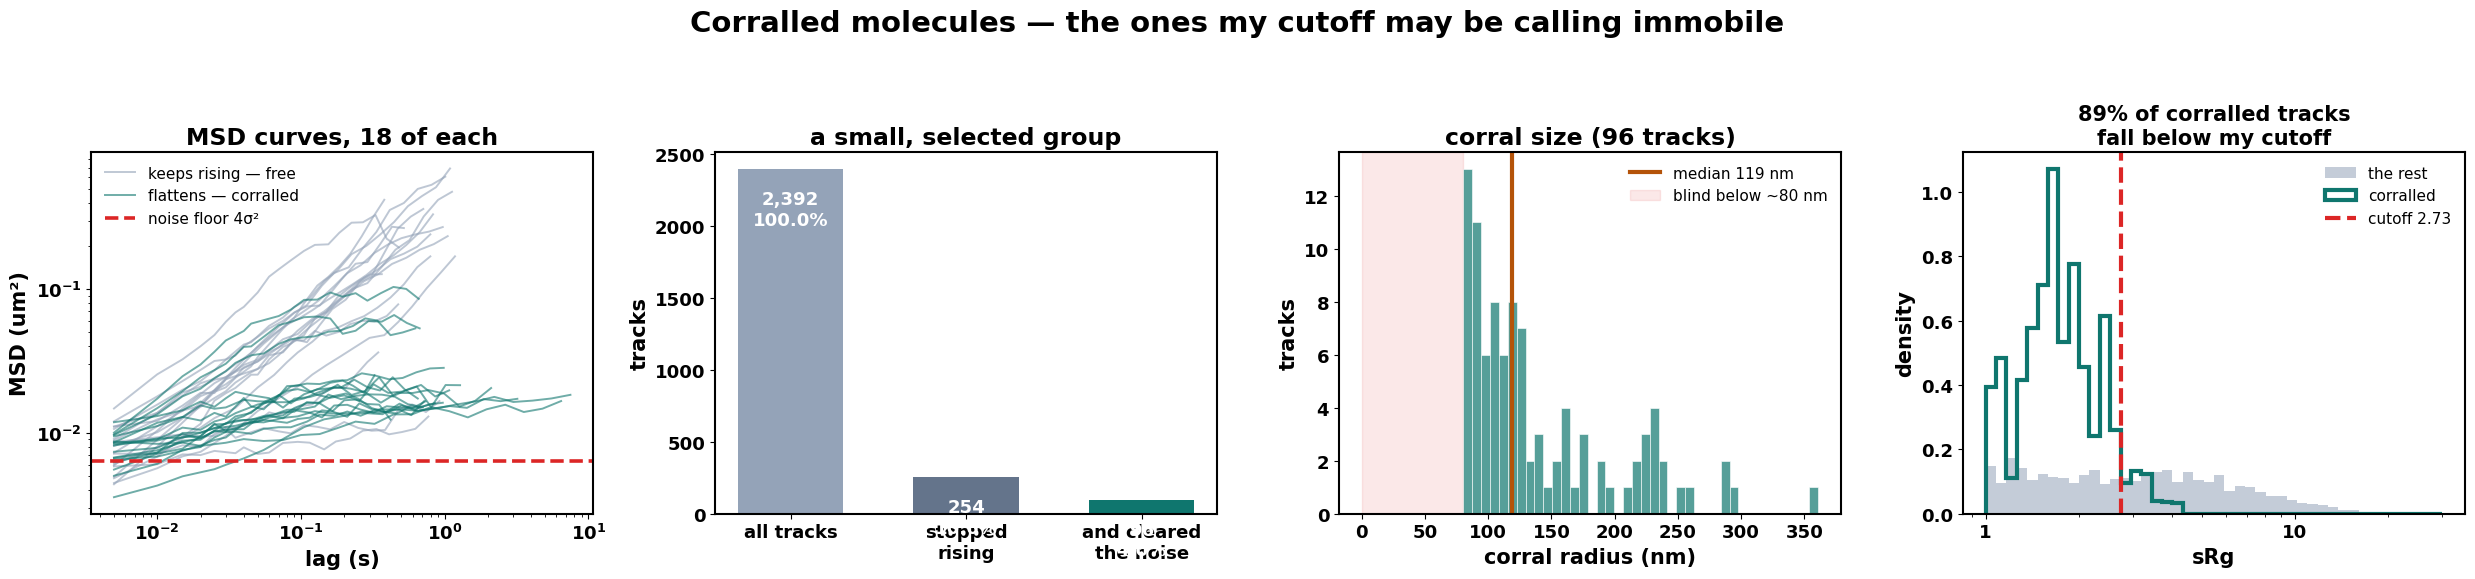

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(25, 5.6))
C_CORR, C_FREE = "#0f766e", "#94a3b8"
noise_level = 4 * float(np.median(SIGMA)) ** 2

def msd_curve(fr, P, n_lag=25):
    f0, span = fr[0], int(fr[-1] - fr[0] + 1)
    A = np.full((span, 2), np.nan); A[fr - f0] = P
    lags = np.unique(np.round(
        np.logspace(0, np.log10(max(8, span // 4)), n_lag)).astype(int))
    lags = lags[lags < span]
    out = []
    for k in lags:
        dd = A[k:] - A[:-k]; dd = dd[np.isfinite(dd).all(1)]
        out.append((dd ** 2).sum(1).mean() if dd.shape[0] >= 20 else np.nan)
    return lags * DT_S, np.array(out)

tid_l = real_live.track_gid.to_numpy(); fr_l = real_live.frame.to_numpy()
P_l = real_live[["x_um", "y_um"]].to_numpy(np.float64)
cuts = np.flatnonzero(np.diff(tid_l)) + 1
st_l = np.concatenate([[0], cuts]); en_l = np.concatenate([cuts, [len(tid_l)]])
pos = {t: (s, e) for t, s, e in zip(tid_l[st_l], st_l, en_l)}
flat_ids = CORRAL_TAB.loc[keep, "track_gid"].to_numpy()
free_ids = CORRAL_TAB.loc[~CORRAL_TAB.flat, "track_gid"].to_numpy()
rg = np.random.default_rng(SEED)

ax = axes[0]
for ids, c, lab in [(free_ids, C_FREE, "keeps rising — free"),
                    (flat_ids, C_CORR, "flattens — corralled")]:
    for j, t in enumerate(rg.choice(ids, min(18, len(ids)), replace=False)):
        s, e = pos[t]
        x, y = msd_curve(fr_l[s:e], P_l[s:e])
        ax.plot(x, y, lw=1.4, color=c, alpha=.6, label=lab if j == 0 else None)
ax.axhline(noise_level, color="#dc2626", ls="--", lw=2.6, label="noise floor 4σ²")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("lag (s)"); ax.set_ylabel("MSD (um²)")
ax.set_title("MSD curves, 18 of each")
ax.legend(fontsize=11, frameon=False)

ax = axes[1]
bars = [len(CORRAL_TAB), int(CORRAL_TAB.flat.sum()), len(CORRAL)]
ax.bar(range(3), bars, color=[C_FREE, "#64748b", C_CORR], width=.6)
for i, v in enumerate(bars):
    ax.text(i, v, f"\n{v:,}\n{100*v/bars[0]:.1f}%", ha="center", va="top",
            fontsize=13, fontweight="bold", color="white")
ax.set_xticks(range(3))
ax.set_xticklabels(["all tracks", "stopped\nrising", "and cleared\nthe noise"])
ax.set_ylabel("tracks")
ax.set_title("a small, selected group")

ax = axes[2]
ax.hist(1000 * CORRAL, bins=40, color=C_CORR, alpha=.7, edgecolor="white", lw=.6)
ax.axvline(1000 * np.median(CORRAL), color="#b45309", lw=3,
           label=f"median {1000*np.median(CORRAL):.0f} nm")
ax.axvspan(0, 2000 * np.median(SIGMA), color="#dc2626", alpha=.10, zorder=0,
           label=f"blind below ~{2000*np.median(SIGMA):.0f} nm")
ax.set_xlabel("corral radius (nm)"); ax.set_ylabel("tracks")
ax.set_title(f"corral size ({len(CORRAL)} tracks)")
ax.legend(fontsize=11, frameon=False)

ax = axes[3]
J = CORRAL_TAB.merge(R_LIVE[["track_gid", "sRg"]], on="track_gid")
J["corralled"] = J.flat & J.above_noise & J.R_um.notna()
bins = np.logspace(0, np.log10(30), 45)
ax.hist(J.loc[~J.corralled, "sRg"], bins=bins, density=True, color=C_FREE,
        alpha=.55, label="the rest")
ax.hist(J.loc[J.corralled, "sRg"], bins=bins, density=True, histtype="step",
        lw=3, color=C_CORR, label="corralled")
ax.axvline(CUTOFF, color="#dc2626", ls="--", lw=3, label=f"cutoff {CUTOFF:.2f}")
ax.set_xscale("log"); ax.xaxis.set_major_formatter(fmt)
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
pct = 100 * float((J.loc[J.corralled, "sRg"] <= CUTOFF).mean())
ax.set_xlabel("sRg"); ax.set_ylabel("density")
ax.set_title(f"{pct:.0f}% of corralled tracks\nfall below my cutoff", fontsize=15)
ax.legend(fontsize=11, frameon=False)

bold_ticks(*axes)
fig.suptitle("Corralled molecules — the ones my cutoff may be calling immobile",
             y=1.04)
fig.tight_layout()
fig.savefig(FIG_DIR / "M6_corral.png", bbox_inches="tight")

### Density

How crowded a field is, measured as detections per frame over the area the
molecules actually cover. It matters because it sets how often the tracker
picks the wrong neighbour.

In [16]:
def density_per_field(d):
    """detections per frame / convex hull area, per field"""
    rows = []
    for fov, g in tqdm(d.groupby("fov_uid"), total=d.fov_uid.nunique(),
                       desc="density per field"):
        P = g[["x_um", "y_um"]].to_numpy()
        if len(P) < 10:
            continue
        area = ConvexHull(P).volume
        rows.append({"fov_uid": fov, "area_um2": area,
                     "n_tracks": g.track_gid.nunique(),
                     "per_frame": len(g) / g.frame.nunique(),
                     "density": len(g) / g.frame.nunique() / area})
    return pd.DataFrame(rows)

DENS_TAB = density_per_field(real_live)
DENS_FIX = density_per_field(real_fix)
DENSITY  = DENS_TAB.density.to_numpy()
my_density = float(np.median(DENSITY))

print(f"density: median {my_density:.4f} puncta/um2, "
      f"range {DENSITY.min():.4f}-{DENSITY.max():.4f} ({len(DENSITY)} fields)")
print(f"   library {DENSITY_RANGE[0]}-{DENSITY_RANGE[1]} /um2, log-uniform")
print(f"   fields below the library floor: "
      f"{int((DENSITY < DENSITY_RANGE[0]).sum())} of {len(DENSITY)}")

density per field:   0%|          | 0/27 [00:00<?, ?it/s]

density per field:   0%|          | 0/53 [00:00<?, ?it/s]

density: median 0.0522 puncta/um2, range 0.0222-0.1102 (27 fields)
   library 0.02-0.8 /um2, log-uniform
   fields below the library floor: 0 of 27


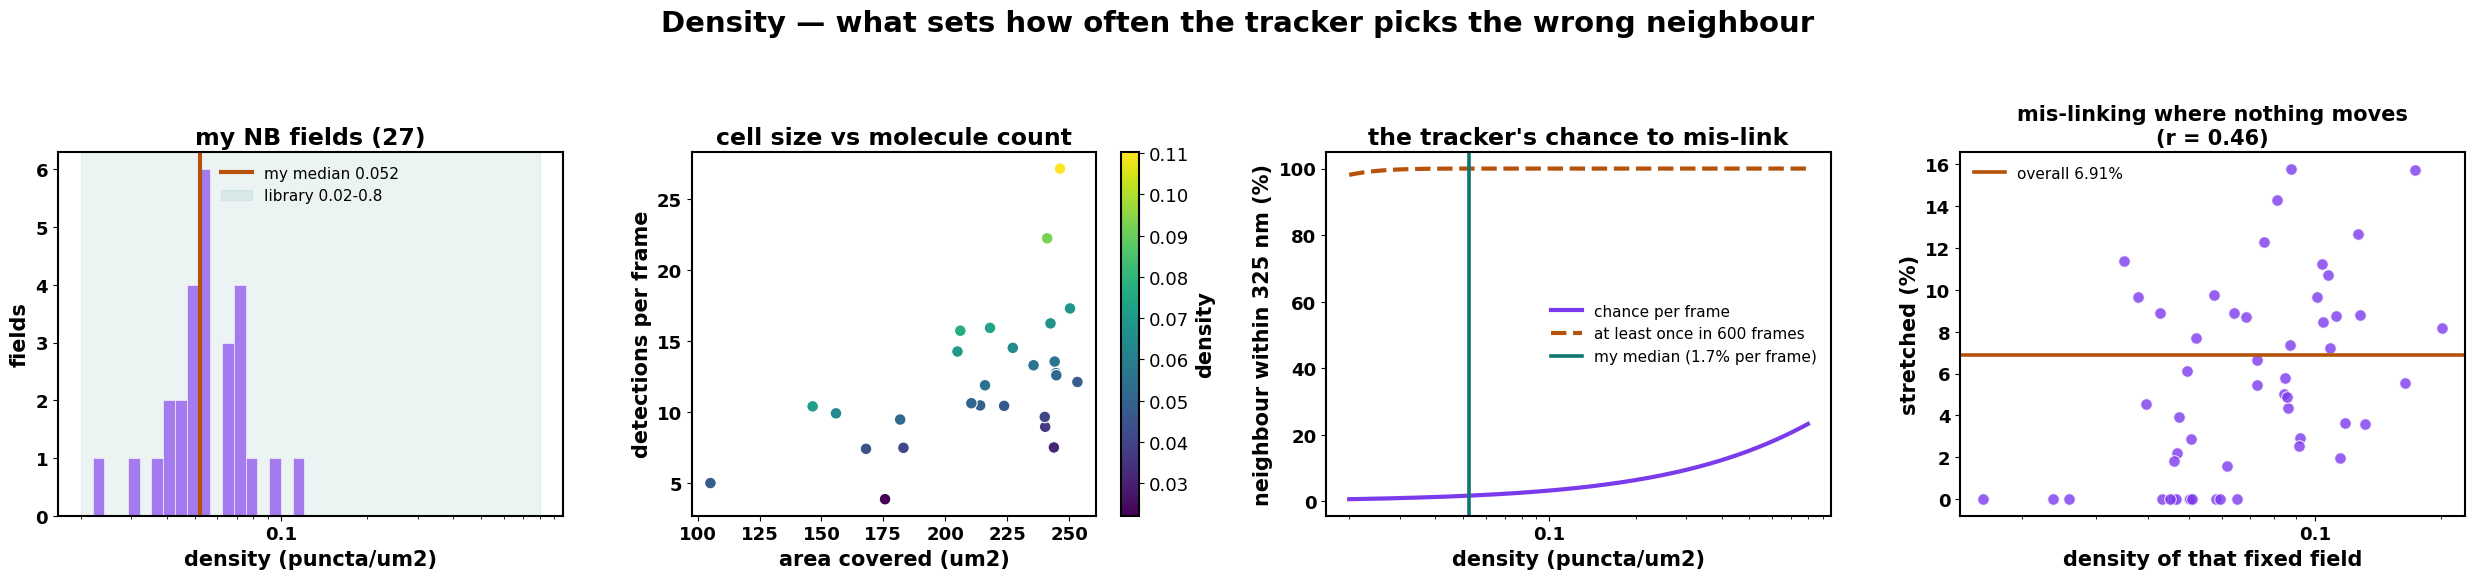

In [17]:
fig, axes = plt.subplots(1, 4, figsize=(25, 5.6))
C_DEN = "#7c3aed"

ax = axes[0]
bins = np.logspace(np.log10(DENSITY_RANGE[0]), np.log10(DENSITY_RANGE[1]), 40)
ax.hist(DENSITY, bins=bins, color=C_DEN, alpha=.65, edgecolor="white", lw=.6)
ax.axvline(my_density, color="#b45309", lw=3, label=f"my median {my_density:.3f}")
ax.axvspan(*DENSITY_RANGE, color="#0f766e", alpha=.08, zorder=0,
           label=f"library {DENSITY_RANGE[0]}-{DENSITY_RANGE[1]}")
ax.set_xscale("log"); ax.xaxis.set_major_formatter(fmt)
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.set_xlabel("density (puncta/um2)"); ax.set_ylabel("fields")
ax.set_title(f"my NB fields ({len(DENSITY)})")
ax.legend(fontsize=11, frameon=False)

ax = axes[1]
sc = ax.scatter(DENS_TAB.area_um2, DENS_TAB.per_frame, s=70,
                c=DENS_TAB.density, cmap="viridis", edgecolors="white", lw=.8)
plt.colorbar(sc, ax=ax, label="density")
ax.set_xlabel("area covered (um2)"); ax.set_ylabel("detections per frame")
ax.set_title("cell size vs molecule count")

ax = axes[2]
d_grid = np.logspace(np.log10(DENSITY_RANGE[0]), np.log10(DENSITY_RANGE[1]), 200)
p_frame = 1 - np.exp(-d_grid * np.pi * R_LINK ** 2)
ax.plot(d_grid, 100 * p_frame, lw=3, color=C_DEN, label="chance per frame")
ax.plot(d_grid, 100 * (1 - (1 - p_frame) ** 600), lw=3, color="#b45309",
        ls="--", label="at least once in 600 frames")
ax.axvline(my_density, color="#0f766e", lw=2.6,
           label=f"my median ({100*(1-np.exp(-my_density*np.pi*R_LINK**2)):.1f}%"
                 f" per frame)")
ax.set_xscale("log"); ax.xaxis.set_major_formatter(fmt)
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.set_xlabel("density (puncta/um2)")
ax.set_ylabel(f"neighbour within {1000*R_LINK:.0f} nm (%)")
ax.set_title("the tracker's chance to mis-link")
ax.legend(fontsize=11, frameon=False)

ax = axes[3]
fov_of = real_fix.groupby("track_gid").fov_uid.first().reset_index()
Jd = R_FIX.merge(fov_of, on="track_gid")
Jd["stretched"] = Jd.aspect > ASPECT_CUT
per_fov = (Jd.groupby("fov_uid").stretched.mean().mul(100)
           .rename("stretched_pct").reset_index()
           .merge(DENS_FIX[["fov_uid", "density"]], on="fov_uid"))
ax.scatter(per_fov.density, per_fov.stretched_pct, s=70, color=C_DEN, alpha=.8,
           edgecolors="white", lw=.8)
r = per_fov[["density", "stretched_pct"]].corr().iloc[0, 1]
ax.axhline(STRETCHED, color="#b45309", lw=2.6, label=f"overall {STRETCHED:.2f}%")
ax.set_xscale("log"); ax.xaxis.set_major_formatter(fmt)
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.set_xlabel("density of that fixed field"); ax.set_ylabel("stretched (%)")
ax.set_title(f"mis-linking where nothing moves\n(r = {r:.2f})", fontsize=15)
ax.legend(fontsize=11, frameon=False)

bold_ticks(*axes)
fig.suptitle("Density — what sets how often the tracker picks the wrong "
             "neighbour", y=1.04)
fig.tight_layout()
fig.savefig(FIG_DIR / "M7_density.png", bbox_inches="tight")

### Unresolved pairs — estimating them from brightness

The brightness analysis below estimates the fraction of fixed-cell tracks whose
mean intensity is above 1.5 times the single-molecule brightness mode. This is a
**brightness-based proxy**, not a definitive count of unresolved pairs: focus,
dye brightness, and illumination can also make a single molecule appear bright.

The field simulation gives a separate prediction based on random spatial
overlap. Keep the brightness estimate and simulation prediction separate; do
not treat them as interchangeable measurements.

In [18]:
# what my field simulation predicted, from the run with my own linker
# settings. These are measurements, so they live here with the others rather
# than down in the artefact model that uses them.
LINK_TABLE = pd.DataFrame({
    "density":     [0.02, 0.05, 0.10, 0.20, 0.45, 0.80],
    "mislink_pct": [0.00, 1.48, 2.61, 5.59, 11.70, 17.92],
    "pair_pct":    [0.00, 0.07, 0.39, 1.24,  2.48,  4.34]})

def pair_rate_fieldsim(density):
    """The field simulation's pair prediction, kept for comparison."""
    return float(np.interp(density, LINK_TABLE.density,
                           LINK_TABLE.pair_pct)) / 100

_I = SIG_TAB.intensity.to_numpy()
_I = _I[np.isfinite(_I) & (_I > 0)]
# the single-molecule brightness is the mode, not the mean: pairs and brighter
# artefacts pull a mean up, a mode is where most molecules sit
_h, _e = np.histogram(_I, bins=80)
_mode = 0.5 * (_e[int(np.argmax(_h))] + _e[int(np.argmax(_h)) + 1])
# Brightness-based unresolved-pair proxy. Version 2 no longer uses it as the
# simulation's rate: the plan fits the cluster rate to the fixed sRg
# distribution (section 5). It is kept as an independent number to compare
# the fitted rate with.
PAIR_AT_MINE = float(np.mean(_I > 1.5 * _mode))

rows = []
for thr, lab in [(1.5, "1.5x the single-molecule mode"),
                 (1.7, "1.7x"), (2.0, "2.0x (a clean double)")]:
    rows.append({"threshold": lab,
                 "intensity": round(thr * _mode, 1),
                 "tracks above": int((_I > thr * _mode).sum()),
                 "% of tracks": round(100 * float((_I > thr * _mode).mean()), 2)})
PAIR_I = pd.DataFrame(rows)
PAIR_I.to_csv(TAB_DIR / "pair_rate_from_brightness.csv", index=False)
print(f"single-molecule brightness (mode): {_mode:.1f}")
print(PAIR_I.to_string(index=False))
print()
print("for comparison:")
print(f"   brightness-based proxy: {100*PAIR_AT_MINE:.2f}%")
print(f"   field-simulation prediction: {pair_rate_fieldsim(my_density)*100:.2f}%")
print("These are different estimation methods. The brightness threshold is a")
print("proxy for unresolved pairs, not a definitive pair count.")

single-molecule brightness (mode): 131.1
                    threshold  intensity  tracks above  % of tracks
1.5x the single-molecule mode      196.7            24         0.79
                         1.7x      222.9             6         0.20
        2.0x (a clean double)      262.3             0         0.00

for comparison:
   brightness-based proxy: 0.79%
   field-simulation prediction: 0.08%
These are different estimation methods. The brightness threshold is a
proxy for unresolved pairs, not a definitive pair count.


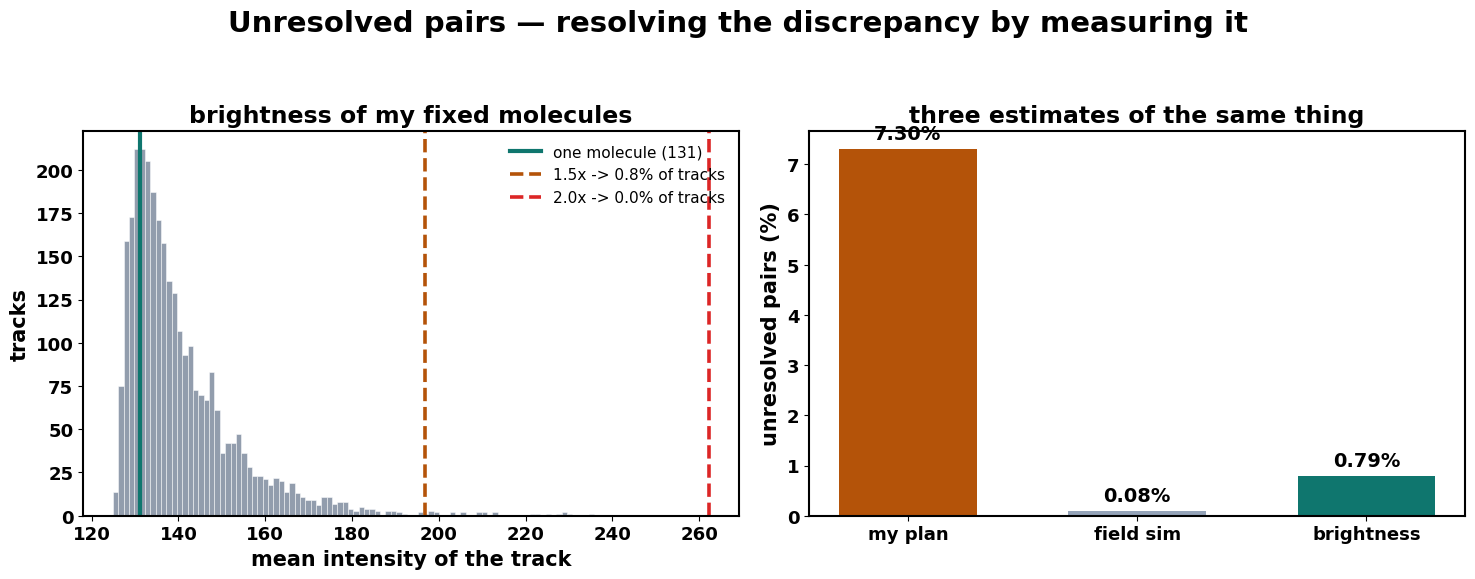

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))

ax = axes[0]
ax.hist(_I, bins=90, color=C_FIX, alpha=.7, edgecolor="white", lw=.5)
ax.axvline(_mode, color="#0f766e", lw=3, label=f"one molecule ({_mode:.0f})")
for thr, c in [(1.5, "#b45309"), (2.0, "#dc2626")]:
    ax.axvline(thr * _mode, color=c, ls="--", lw=2.6,
               label=f"{thr}x -> {100*(_I > thr*_mode).mean():.1f}% of tracks")
ax.set_xlabel("mean intensity of the track"); ax.set_ylabel("tracks")
ax.set_title("brightness of my fixed molecules")
ax.legend(fontsize=11, frameon=False)

ax = axes[1]
ax.bar(range(3), [7.30, 100 * pair_rate_fieldsim(my_density),
                  float(PAIR_I.loc[PAIR_I.threshold.str.startswith("1.5"),
                                   "% of tracks"].iloc[0])],
       color=["#b45309", "#94a3b8", "#0f766e"], width=.6)
for i, v in enumerate([7.30, 100 * pair_rate_fieldsim(my_density),
                       float(PAIR_I.loc[PAIR_I.threshold.str.startswith("1.5"),
                                        "% of tracks"].iloc[0])]):
    ax.text(i, v + .2, f"{v:.2f}%", ha="center", fontsize=14, fontweight="bold")
ax.set_xticks(range(3))
ax.set_xticklabels(["my plan", "field sim", "brightness"])
ax.set_ylabel("unresolved pairs (%)")
ax.set_title("three estimates of the same thing")

bold_ticks(*axes)
fig.suptitle("Unresolved pairs — resolving the discrepancy by measuring it",
             y=1.04)
fig.tight_layout()
fig.savefig(FIG_DIR / "M7b_pair_rate.png", bbox_inches="tight")

### Everything measured, in one table

In [20]:
duty_all = pd.concat([FIX.duty, LIVE.duty])
MEASURED = pd.DataFrame([
    ("localisation error", f"{1000*np.median(SIGMA):.1f} nm",
     f"{1000*SIGMA_RANGE[0]:.0f}-{1000*SIGMA_RANGE[1]:.0f} nm",
     "fixed cells: every step is pure error"),
    ("duty cycle", f"{duty_all.median():.2f}",
     f"{DUTY_RANGE[0]}-{DUTY_RANGE[1]}", "every real track's frame pattern"),
    ("stage drift", f"{1000*np.median(DRIFT):.0f} nm/movie "
                    f"({1000*DRIFT.min():.0f}-{1000*DRIFT.max():.0f})",
     f"x{DRIFT_SCALE[0]}-{DRIFT_SCALE[1]}", "long tracks, start vs end"),
    ("linker jump limit", f"{1000*R_LINK:.0f} nm", f"{1000*R_LINK:.0f} nm",
     "the tracking software, not the sample - so no range"),
    ("density", f"{my_density:.3f} /um2 "
                f"({DENSITY.min():.3f}-{DENSITY.max():.3f})",
     f"{DENSITY_RANGE[0]}-{DENSITY_RANGE[1]} /um2",
     "detections per frame / hull area"),
    ("diffusion coefficient", f"{np.median(D_POOL):.3f} um2/s",
     f"x{D_SCALE[0]}-{D_SCALE[1]}", "MSD fit, lags 1-8, mobile tracks only"),
    ("corral radius", f"{1000*np.median(CORRAL):.0f} nm "
                      f"({1000*np.quantile(CORRAL,.1):.0f}-"
                      f"{1000*np.quantile(CORRAL,.9):.0f})",
     f"x{CORRAL_SCALE[0]}-{CORRAL_SCALE[1]}",
     f"MSD plateau, {len(CORRAL)} tracks; blind below "
     f"{2000*np.median(SIGMA):.0f} nm"),
    ("unresolved clusters", f"{100*PAIR_AT_MINE:.2f}% bright; "
                            f"{STRETCHED:.2f}% stretched; separation "
                            f"{1000*np.median(CLUSTER_SEP):.0f} nm",
     f"fitted rate x{CLUSTER_SCALE[0]}-{CLUSTER_SCALE[1]}",
     "rate, separation scale, wide share and dwell FITTED (section 5)"),
    ("mis-linking", "notebook 04 field simulation",
     f"{LINK_TABLE.mislink_pct.min():.0f}-{LINK_TABLE.mislink_pct.max():.0f}% "
     "by density", "read off the density curve, as the plan says"),
    ("sigma within a track", f"end/start 10-90th "
                             f"{np.exp(np.quantile(SIG_LOGRATIO,.1)):.2f}-"
                             f"{np.exp(np.quantile(SIG_LOGRATIO,.9)):.2f}",
     "same", "fixed cells, first vs last third, estimator noise removed"),
    ("detection threshold", "not measurable",
     f"{EXPOSURE_RANGE[0]}-{EXPOSURE_RANGE[1]} of a frame",
     "ASSUMED - a photon threshold, and I took intensity out"),
    ("obstacle spacing", "not measurable",
     f"{LATTICE_NM[0]:.0f}-{LATTICE_NM[1]:.0f} nm",
     "ASSUMED - below what single-particle tracking resolves"),
    ("drift direction", "mostly one axis",
     "drawn from my measured per-field angles",
     "shared within a field, as a stage is - not per molecule"),
], columns=["parameter", "what I measured", "training library", "how / caveat"])
MEASURED.to_csv(TAB_DIR / "measured_parameters.csv", index=False)
print(MEASURED.to_string(index=False))

# Everything from here runs on the pools measured above, not on the raw
# positions, so the two real track tables can go. Together they are about four
# million rows, and holding them alongside three simulated sets is what ran the
# kernel out of memory.
N_REAL_FIX = int(real_fix.track_gid.nunique())
N_REAL_LIVE = int(real_live.track_gid.nunique())
# tracks per field in my real data: the simulated reference and fixed sets
# use the same, so a handful of drift trajectories cannot dominate them
TRACKS_PER_FIELD = {
    "fixed": N_REAL_FIX / real_fix.fov_uid.nunique(),
    "live": N_REAL_LIVE / real_live.fov_uid.nunique()}
print("tracks per field: " + ", ".join(f"{k} {v:.0f}"
                                         for k, v in TRACKS_PER_FIELD.items()))

# --- before the raw tables go: the measures the plan's third check compares ---
# One function, used on my real tracks here and on the simulated ones later,
# so both sides of the comparison are computed the same way.
MSD_LAGS = np.unique(np.round(np.logspace(0, np.log10(400), 24)).astype(int))

def track_measures(fr, P, dt=DT_S):
    """Per-track measures from frame numbers and positions alone."""
    f0, span = int(fr[0]), int(fr[-1] - fr[0] + 1)
    g = np.diff(fr) - 1
    ok1 = np.diff(fr) == 1
    step = np.linalg.norm(np.diff(P, axis=0)[ok1], axis=1)
    c = P - P.mean(0)
    Rg = np.sqrt((c ** 2).sum(1).mean())
    A = np.full((span, 2), np.nan); A[fr - f0] = P
    msd = np.full(MSD_LAGS.size, np.nan)
    for i, k in enumerate(MSD_LAGS):
        if k >= span:
            break
        dd = A[k:] - A[:-k]; dd = dd[np.isfinite(dd).all(1)]
        if dd.shape[0] >= 20:
            msd[i] = (dd ** 2).sum(1).mean()
    m8 = msd[MSD_LAGS <= 8]
    alpha = (np.polyfit(np.log(MSD_LAGS[MSD_LAGS <= 8][np.isfinite(m8)]),
                        np.log(m8[np.isfinite(m8)]), 1)[0]
             if np.isfinite(m8).sum() >= 4 else np.nan)
    return {"n_det": fr.size, "duty": fr.size / span,
            "dark_frac": 1 - fr.size / span, "n_gaps": int((g > 0).sum()),
            "longest_gap": int(g.max()) if g.size else 0,
            "Rg_um": Rg, "step_um": step.mean() if step.size else np.nan,
            "sRg": SQ * Rg / step.mean() if step.size >= 2 else np.nan,
            "alpha_1_8": alpha, "msd": msd}

def measures_of(d, min_det=MIN_TRACK_LEN, desc="measures"):
    tid, fr = d.track_gid.to_numpy(), d.frame.to_numpy()
    P = d[["x_um", "y_um"]].to_numpy(np.float64)
    cuts = np.flatnonzero(np.diff(tid)) + 1
    st = np.concatenate([[0], cuts]); en = np.concatenate([cuts, [len(tid)]])
    rows, msds = [], []
    for s_, e_ in tqdm(zip(st, en), total=len(st), desc=desc, leave=False):
        if e_ - s_ < min_det:
            continue
        m = track_measures(fr[s_:e_], P[s_:e_])
        msds.append(m.pop("msd"))
        m["track_gid"] = tid[s_]
        rows.append(m)
    return pd.DataFrame(rows), np.vstack(msds)

MEAS_LIVE, MSD_LIVE = measures_of(real_live, desc="real live measures")
MEAS_FIX, MSD_FIX = measures_of(real_fix, desc="real fixed measures")
FIX_DENSITY = float(DENS_FIX.density.median())
print(f"kept {len(MEAS_LIVE):,} live and {len(MEAS_FIX):,} fixed per-track "
      f"measures for the side-by-side check (section 6b)")
print(f"fixed-cell density {FIX_DENSITY:.3f} /um2 (live {my_density:.3f})")
del real_fix, real_live
gc.collect()
print()
print("freed the real track tables; the measured pools carry on from here")

            parameter                                  what I measured                        training library                                                    how / caveat
   localisation error                                          40.0 nm                                15-80 nm                           fixed cells: every step is pure error
           duty cycle                                             0.74                                 0.4-1.0                                every real track's frame pattern
          stage drift                             71 nm/movie (17-136)                                x0.5-3.0                                       long tracks, start vs end
    linker jump limit                                           325 nm                                  325 nm             the tracking software, not the sample - so no range
              density                         0.052 /um2 (0.022-0.110)                           0.02-0.8 /um2               

real live measures:   0%|          | 0/2392 [00:00<?, ?it/s]

real fixed measures:   0%|          | 0/3025 [00:00<?, ?it/s]

kept 2,392 live and 3,025 fixed per-track measures for the side-by-side check (section 6b)
fixed-cell density 0.069 /um2 (live 0.052)

freed the real track tables; the measured pools carry on from here


## 2. The five motion models

Saxton MJ & Jacobson K (1997), *Annu. Rev. Biophys. Biomol. Struct.* 26:373–399,
doi:10.1146/annurev.biophys.26.1.373

| type | model | MSD |
|---|---|---|
| normal | free Brownian diffusion | 4Dt |
| restricted | fractional Gaussian noise | 4Dt^α, α = 0.3–0.9 |
| corralled | diffusion inside a circular corral | rises, flattens at R² |
| directed | Brownian diffusion plus a velocity | 4Dt + (vt)² |
| immobile | very slow Brownian motion | ≈ 0 |

Two things I deliberately do not take on faith. The corral curve uses no
fitted constants — R²(1 − exp(−4Dt/R²)) is 4Dt at short lags and R² at long
ones, and R² is the exact plateau for a particle spread over a disc. And the
anomalous curves are anchored at one frame: in 4Dt^α the coefficient only has
units of µm²/s when α = 1, so reusing the same number at a different α would
make a restricted molecule take *bigger* steps than a free one.

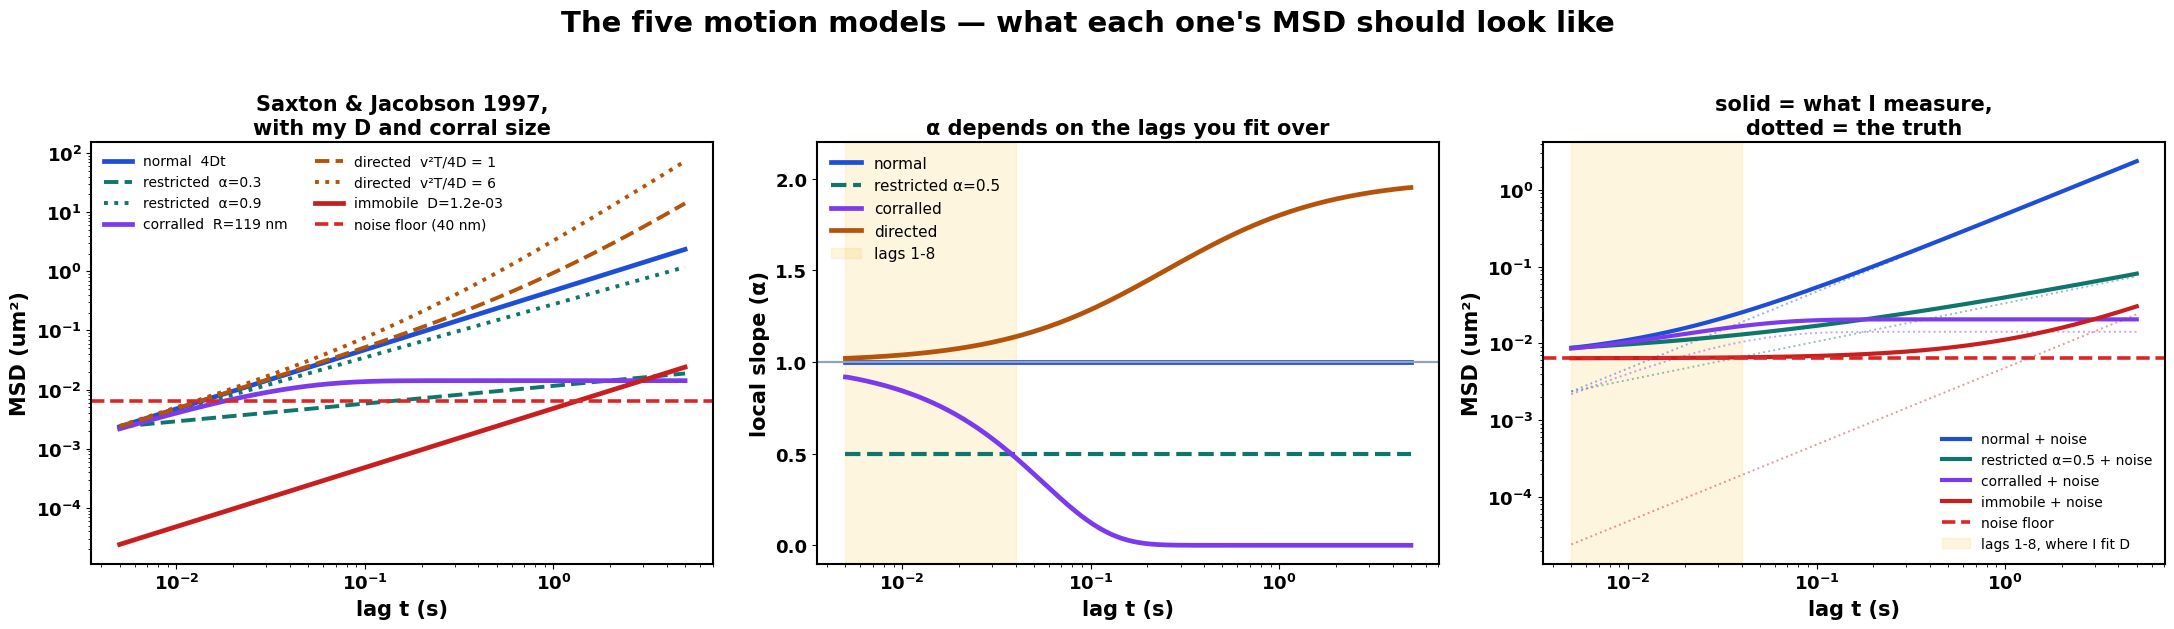

In [21]:
D_  = float(np.median(D_POOL))
rc_ = float(np.median(CORRAL))
t   = np.logspace(np.log10(DT_S), np.log10(5.0), 300)
noise = 4 * float(np.median(SIGMA)) ** 2

msd_normal     = lambda tt: 4 * D_ * tt
msd_restricted = lambda tt, a: 4 * (D_ * DT_S ** (1 - a)) * tt ** a
msd_corralled  = lambda tt: rc_ ** 2 * (1 - np.exp(-4 * D_ * tt / rc_ ** 2))
msd_directed   = lambda tt, dn, T=1.0: (4 * D_ * tt
                                        + (np.sqrt(4 * D_ * dn / T) * tt) ** 2)
msd_immobile   = lambda tt: 4 * D_IMMOBILE[1] * tt

fig, axes = plt.subplots(1, 3, figsize=(22, 6.2))

ax = axes[0]
ax.plot(t, msd_normal(t), lw=3.4, color=COL["normal"], label="normal  4Dt")
for a_, ls in ((0.3, "--"), (0.9, ":")):
    ax.plot(t, msd_restricted(t, a_), lw=2.8, color=COL["restricted"], ls=ls,
            label=f"restricted  α={a_}")
ax.plot(t, msd_corralled(t), lw=3.4, color=COL["corralled"],
        label=f"corralled  R={1000*rc_:.0f} nm")
for dn, ls in ((1, "--"), (6, ":")):
    ax.plot(t, msd_directed(t, dn), lw=2.8, color=COL["directed"], ls=ls,
            label=f"directed  v²T/4D = {dn}")
ax.plot(t, msd_immobile(t), lw=3.4, color=COL["immobile"],
        label=f"immobile  D={D_IMMOBILE[1]:.1e}")
ax.axhline(noise, color="#dc2626", ls="--", lw=2.6,
           label=f"noise floor ({1000*np.median(SIGMA):.0f} nm)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("lag t (s)"); ax.set_ylabel("MSD (um²)")
ax.set_title(f"Saxton & Jacobson 1997,\nwith my D and corral size", fontsize=15)
ax.legend(fontsize=10, frameon=False, loc="upper left", ncol=2)

ax = axes[1]
slope_of = lambda y: np.gradient(np.log(y), np.log(t))
ax.plot(t, slope_of(msd_normal(t)), lw=3.4, color=COL["normal"], label="normal")
ax.plot(t, slope_of(msd_restricted(t, 0.5)), lw=3, color=COL["restricted"],
        ls="--", label="restricted α=0.5")
ax.plot(t, slope_of(msd_corralled(t)), lw=3.4, color=COL["corralled"],
        label="corralled")
ax.plot(t, slope_of(msd_directed(t, 4)), lw=3.4, color=COL["directed"],
        label="directed")
ax.axhline(1, color="#94a3b8", lw=1.6)
ax.axvspan(DT_S, 8 * DT_S, color="#fbbf24", alpha=.15, zorder=0, label="lags 1-8")
ax.set_xscale("log"); ax.set_ylim(-0.1, 2.2)
ax.set_xlabel("lag t (s)"); ax.set_ylabel("local slope (α)")
ax.set_title("α depends on the lags you fit over", fontsize=15)
ax.legend(fontsize=11, frameon=False)

ax = axes[2]
for name, key, y in [("normal", "normal", msd_normal(t)),
                     ("restricted α=0.5", "restricted", msd_restricted(t, 0.5)),
                     ("corralled", "corralled", msd_corralled(t)),
                     ("immobile", "immobile", msd_immobile(t))]:
    ax.plot(t, y + noise, lw=3, color=COL[key], label=f"{name} + noise")
    ax.plot(t, y, lw=1.4, color=COL[key], alpha=.45, ls=":")
ax.axhline(noise, color="#dc2626", ls="--", lw=2.6, label="noise floor")
ax.axvspan(DT_S, 8 * DT_S, color="#fbbf24", alpha=.15, zorder=0,
           label="lags 1-8, where I fit D")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("lag t (s)"); ax.set_ylabel("MSD (um²)")
ax.set_title("solid = what I measure,\ndotted = the truth", fontsize=15)
ax.legend(fontsize=10, frameon=False)

bold_ticks(*axes)
fig.suptitle("The five motion models — what each one's MSD should look like",
             y=1.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "M8_saxton_msd_shapes.png", bbox_inches="tight")

### Fractional Gaussian noise, and a test that it works

Two things to check, and only one is obvious. The **exponent** is easy. The
**variance** is the one that matters and is easy to miss, because a constant
scale factor does not change the slope of a log-log fit at all — so the
exponent test passes whether or not the scale is right. If the variance is not
1, a restricted molecule takes systematically different steps from a free one
at the same D, and the classifier learns to separate the classes by step size
instead of by motion.

In [22]:
def fgn(n, H, rng):
    """Fractional Gaussian noise of unit variance (Davies-Harte); H = alpha/2."""
    if n < 2:
        return rng.standard_normal(max(n, 0))
    k = np.arange(n)
    g = 0.5 * (np.abs(k - 1) ** (2 * H) - 2 * np.abs(k) ** (2 * H)
               + np.abs(k + 1) ** (2 * H))
    c = np.concatenate([g, g[-2:0:-1]])
    lam = np.clip(np.fft.fft(c).real, 0, None)
    m = c.size
    V = rng.standard_normal(m) + 1j * rng.standard_normal(m)
    return np.fft.fft(np.sqrt(lam / m) * V).real[:n]

_rng = np.random.default_rng(SEED)
LAGS = np.arange(1, 41)
rows = []
for a_ in (0.3, 0.5, 0.7, 0.9, 1.0):
    msd = np.zeros(LAGS.size)
    for _ in range(300):
        x = np.cumsum(fgn(800, a_ / 2, _rng))
        y = np.cumsum(fgn(800, a_ / 2, _rng))
        for i, k in enumerate(LAGS):
            msd[i] += ((x[k:] - x[:-k]) ** 2 + (y[k:] - y[:-k]) ** 2).mean()
    fit = np.polyfit(np.log(LAGS), np.log(msd / 300), 1)[0]
    var = float(np.mean([np.var(fgn(5000, a_ / 2, _rng)) for _ in range(20)]))
    rows.append({"asked for": a_, "measured α": round(fit, 3),
                 "α error": round(fit - a_, 3), "step variance": round(var, 3)})
TEST = pd.DataFrame(rows)
print(TEST.to_string(index=False))
print(f"\nexponent      {'PASS' if TEST['α error'].abs().max()<.05 else 'FAIL'}"
      f"  largest error {TEST['α error'].abs().max():.3f}")
print(f"step variance {'PASS' if (TEST['step variance']-1).abs().max()<.05 else 'FAIL'}"
      f"  largest deviation {(TEST['step variance']-1).abs().max():.3f}")

 asked for  measured α  α error  step variance
       0.3       0.300   -0.000          1.001
       0.5       0.502    0.002          0.997
       0.7       0.698   -0.002          1.002
       0.9       0.909    0.009          1.004
       1.0       0.996   -0.004          0.999

exponent      PASS  largest error 0.009
step variance PASS  largest deviation 0.004


### The obstacle model — held out, not trained on

My plan allows restricted motion to be generated either as fractional Gaussian
noise *or* by obstacles. The test below shows obstacles only reach α = 0.79–0.93
over the lags I fit, while my restricted class needs 0.3–0.9 — so mixing them
would make the class bimodal in exponent.

Instead the obstacle model is **held out**: after the model is trained on fGn
alone, I show it obstacle tracks it has never seen and ask whether it still
calls them restricted. That tests whether it learned subdiffusion or merely the
generator I produced it with.

In [23]:
LATTICE_N = 256

def obstructed(n, D, dt, lattice_um, conc, rng):
    """a molecule picking its way between immobile obstacles on a lattice"""
    a = lattice_um
    # hops per frame on an empty lattice, so that MSD per frame = 4*D*dt.
    # Drawn from a Poisson rather than rounded: at 5 ms this quantity is near 1,
    # and rounding it to an integer made the walker up to 52% too fast or 32%
    # too slow depending on the lattice spacing. A random walk's MSD is
    # E[hops]*a^2 whatever the hop count's distribution, so the mean is exact.
    lam = 4 * D * dt / a ** 2
    hops = rng.poisson(lam, n)
    blocked = rng.random((LATTICE_N, LATTICE_N)) < conc
    ix, iy = 0, 0
    while blocked[ix % LATTICE_N, iy % LATTICE_N]:
        ix, iy = int(rng.integers(LATTICE_N)), int(rng.integers(LATTICE_N))
    out = np.empty((n, 2))
    mv = ((1, 0), (-1, 0), (0, 1), (0, -1))
    draws = rng.integers(4, size=int(hops.sum()) + 1)
    j = 0
    for i in range(n):
        for _ in range(hops[i]):
            dx, dy = mv[draws[j]]; j += 1
            if not blocked[(ix + dx) % LATTICE_N, (iy + dy) % LATTICE_N]:
                ix += dx; iy += dy
        out[i] = (ix * a, iy * a)
    return out

_rng = np.random.default_rng(SEED)
N_LONG = 6000
LG = np.unique(np.round(np.logspace(0, np.log10(N_LONG // 4), 25)).astype(int))
rows = []
for conc in (0.20, 0.30, 0.38, 0.41, 0.45, 0.50):
    msd = np.zeros(LG.size); spread = []
    for _ in range(15):
        P = obstructed(N_LONG, D_, DT_S, 0.040, conc, _rng)
        for i, k in enumerate(LG):
            msd[i] += ((P[k:] - P[:-k]) ** 2).sum(1).mean()
        spread.append(np.sqrt(((P - P.mean(0)) ** 2).sum(1).mean()))
    msd /= 15
    early = np.polyfit(np.log(LG[:8]), np.log(msd[:8]), 1)[0]
    late  = np.polyfit(np.log(LG[-8:]), np.log(msd[-8:]), 1)[0]
    mid_m = msd[int(.40*len(msd)):int(.75*len(msd))].mean()
    late_m = msd[int(.75*len(msd)):].mean()
    rows.append({"blocked": conc, "α at the lags I fit": round(early, 2),
                 "α at long lags": round(late, 2),
                 "spread (nm)": round(1000 * np.mean(spread)),
                 "flattens?": "YES" if late_m < 1.25 * mid_m else "no"})
OBS = pd.DataFrame(rows)
OBS.to_csv(TAB_DIR / "obstacle_model_test.csv", index=False)
print(OBS.to_string(index=False))
print(f"\npercolation threshold ~0.4073 blocked. Nothing flattens, so no "
      f"obstacle track\nwould be mistaken for corralled - but α "
      f"{OBS['α at the lags I fit'].min():.2f}-"
      f"{OBS['α at the lags I fit'].max():.2f} does not cover the "
      f"{ALPHA_RANGE[0]}-{ALPHA_RANGE[1]} my restricted class needs.")
print("So: fGn for training, obstacles held out as a generalisation test.")

 blocked  α at the lags I fit  α at long lags  spread (nm) flattens?
    0.20                 0.94            1.04         1158        no
    0.30                 0.88            0.85          722        no
    0.38                 0.83            0.76          439        no
    0.41                 0.84            0.57          366        no
    0.45                 0.80            0.58          258        no
    0.50                 0.75            0.39          148        no

percolation threshold ~0.4073 blocked. Nothing flattens, so no obstacle track
would be mistaken for corralled - but α 0.75-0.94 does not cover the 0.3-0.9 my restricted class needs.
So: fGn for training, obstacles held out as a generalisation test.


### The five generators

In [24]:
RD_MECHANISM = "fgn"
STILL_D = (1e-9, 1e-6)        # um2/s: the share fixation holds completely still

# The things the plan says I cannot measure. They are FITTED together
# in section 5 against my fixed-cell sRg distribution; these are only the
# starting values the motion figures below are drawn with.
#   still_share  - what fraction fixation holds completely still
#   resid_hi     - how much the rest still drifts: D up to this, log-uniform
#                  from 1e-6. Capped at the immobile boundary, by definition
#   wig_hi, wig_tau - how much an anchored molecule wobbles on its tether
#                  (rms per axis, drawn 0 to wig_hi per track) and how fast
#                  (correlation time, frames at 5 ms). The plan's "how much a
#                  fixed molecule still wiggles", split into a bounded wobble
#                  and slow drift, because the two shape the sRg distribution
#                  differently (section 5 shows why both are needed)
#   bad_frac     - how often a localisation is badly fitted (thrown ~3 sigma)
#   cl_rate      - how many tracks are unresolved clusters
#   cl_sep_scale - x my measured separations of the two emitters
#   cl_wide      - the share of clusters 1.5-4x wider than that
#   cl_dwell     - how long the centroid stays on one emitter (frames at 5 ms)
FIT = {"still_share": 0.35, "resid_hi": 1.2e-3, "bad_frac": 0.01,
       "wig_hi": 0.0, "wig_tau": 20.0,
       "cl_rate": 0.10, "cl_sep_scale": 1.0, "cl_wide": 0.10, "cl_dwell": 20.0}

def path_normal(n, dt, p, rng):
    """free Brownian diffusion - Saxton's rho_ND"""
    return np.cumsum(rng.normal(0, np.sqrt(2 * p["D"] * dt), (n, 2)), axis=0)

def path_restricted(n, dt, p, rng):
    """Subdiffusion by fGn: MSD(t) = 4 D dt^(1-alpha) t^alpha.

    Anchored at THIS track's frame time, so one frame is 4 D dt for every
    class at every frame rate. Anchored at a fixed 5 ms (version 1), a
    restricted molecule took (5 ms / dt)^(1-alpha) of a normal one's step -
    0.12x at 100 ms and alpha 0.3 - which a classifier can learn as step size.
    """
    alpha = float(p["alpha"])
    s = np.sqrt(2 * p["D"] * dt)
    return np.column_stack([np.cumsum(s * fgn(n, alpha / 2, rng)),
                            np.cumsum(s * fgn(n, alpha / 2, rng))])

def path_corralled(n, dt, p, rng, sub_frac=0.25, max_sub=400):
    """Diffusion inside a circular corral; it may hop to the next one.

    Sub-steps: each frame is split until one sub-step is under a quarter of R.
    Without them (version 1), a step larger than R - slow frames, high D, a
    small corral - was reflected through the centre and clamped onto the wall.

    Escape (plan): at a wall hit the molecule leaves with probability
    p_escape and enters the neighbouring corral, centred 2R further along that
    direction. p_escape = 0 is a closed corral.
    """
    R = float(p["R"])
    s = np.sqrt(2 * p["D"] * dt)
    n_sub = int(min(max_sub, max(1, np.ceil((s / (sub_frac * R)) ** 2))))
    ss = s / np.sqrt(n_sub)
    pe = float(p.get("p_escape", 0.0))
    th, rr = rng.uniform(0, 2 * np.pi), R * np.sqrt(rng.random())
    pos = np.array([rr * np.cos(th), rr * np.sin(th)])     # from the centre
    centre = np.array(p.get("centre", np.zeros(2)), float).copy()
    steps = rng.normal(0, ss, (n, n_sub, 2))
    hit = rng.random((n, n_sub))
    out = np.empty((n, 2))
    n_esc = 0
    for i in range(n):
        for j in range(n_sub):
            trial = pos + steps[i, j]
            r = np.hypot(trial[0], trial[1])
            if r > R:
                u = trial / r
                if pe > 0 and hit[i, j] < pe:               # into the next one
                    centre = centre + 2 * R * u
                    trial = trial - 2 * R * u
                    n_esc += 1
                else:                                       # bounce
                    trial = trial * (2 * R - r) / r
                r2 = np.hypot(trial[0], trial[1])
                if r2 > R:                                  # rare with sub-steps
                    trial = trial * (R * 0.999 / r2)
            pos = trial
        out[i] = centre + pos
    p["n_escapes"] = n_esc
    return out

def path_directed(n, dt, p, rng):
    """Brownian diffusion plus a constant velocity (Saxton rho_DM)."""
    s = np.sqrt(2 * p["D"] * dt)
    walk = np.cumsum(rng.normal(0, s, (n, 2)), axis=0)
    tt = np.arange(1, n + 1)[:, None] * dt
    return walk + p["v"] * tt * np.array([np.cos(p["theta"]),
                                          np.sin(p["theta"])])

def path_immobile(n, dt, p, rng):
    """Very slow Brownian motion, plus a bounded wobble.

    The slow diffusion is one of the two residual-mobility populations. The
    wobble is what an anchored molecule does on its tether - the label and
    linker flex, so the emitter jiggles around a fixed point without ever
    wandering off: an Ornstein-Uhlenbeck process of rms size p["wig"] per axis
    and correlation time p["wig_tau"] frames at 5 ms (the same in seconds at
    any frame time). Unlike slow diffusion, it does not grow with track length,
    so it lifts the whole sRg distribution without blowing up its tail.
    """
    walk = np.cumsum(rng.normal(0, np.sqrt(2 * p["D"] * dt), (n, 2)), axis=0)
    a = float(p.get("wig", 0.0))
    if a > 0 and n > 0:
        rho = np.exp(-dt / (p["wig_tau"] * DT_S))
        e = rng.normal(0, a * np.sqrt(1 - rho ** 2), (n, 2))
        e[0] = rng.normal(0, a, 2)                 # start in equilibrium
        walk = walk + lfilter([1.0], [1.0, -rho], e, axis=0)
    return walk

PATH = {"normal": path_normal, "restricted": path_restricted,
        "corralled": path_corralled, "directed": path_directed,
        "immobile": path_immobile}

def draw_params(kind, n, dt, rng, vary=True, slow_ok=True):
    """Motion parameters for one track; vary=True is the library.

    One mobile track in five (SLOW_SHARE) is drawn from the slow boundary:
    D between the immobile boundary and my mobile pool's lower quartile. These
    are the tracks the sRg cutoff cannot place, and without them the library
    left an empty gap in D between immobile and mobile (plan, section 7).
    """
    D = float(rng.choice(D_POOL))
    slow = False
    if kind != "immobile" and slow_ok and rng.random() < SLOW_SHARE:
        D = float(np.exp(rng.uniform(np.log(D_IMMOBILE[1]),
                                     np.log(np.quantile(D_POOL, 0.25)))))
        slow = True
    elif vary:
        D *= float(np.exp(rng.uniform(*np.log(D_SCALE))))
    p = {"D": D, "slow": slow}
    if kind == "restricted":
        p["mechanism"] = RD_MECHANISM
        p["alpha"] = float(rng.uniform(*ALPHA_RANGE))
    elif kind == "corralled":
        R = float(rng.choice(CORRAL))
        if vary:
            R *= float(np.exp(rng.uniform(*np.log(CORRAL_SCALE))))
        p["R"], p["centre"] = R, np.zeros(2)
        p["p_escape"] = (0.0 if rng.random() < IMPERMEABLE else
                         float(np.exp(rng.uniform(*np.log(ESCAPE_P)))))
    elif kind == "directed":
        p["directedness"] = float(rng.uniform(*DIRECTEDNESS))
        p["v"] = float(np.sqrt(4 * D * p["directedness"] / (n * dt)))
        p["theta"] = float(rng.uniform(0, 2 * np.pi))
    elif kind == "immobile":
        still = rng.random() < FIT["still_share"]
        lo, hi = STILL_D if still else (1e-6, min(FIT["resid_hi"],
                                                 D_IMMOBILE[1]))
        p["D"] = float(np.exp(rng.uniform(np.log(lo), np.log(hi))))
        p["population"] = "still" if still else "residual"
        p["wig"] = FIT["wig_hi"] * float(rng.random())
        p["wig_tau"] = FIT["wig_tau"]
    return p

# --- does each model produce the MSD it should? fitted PER TRACK -------------
_rng = np.random.default_rng(SEED)
LG = np.unique(np.round(np.logspace(0, np.log10(350), 22)).astype(int))
rows = []
for kind in CLASSES:
    a_e, a_l, lag1, extra = [], [], [], []
    for _ in range(150):
        # the textbook shapes: closed corrals, no slow-boundary draws
        p = draw_params(kind, 1500, DT_S, _rng, vary=False, slow_ok=False)
        if kind == "corralled":
            p["p_escape"] = 0.0
        P = PATH[kind](1500, DT_S, p, _rng)
        m = np.array([((P[k:] - P[:-k]) ** 2).sum(1).mean() for k in LG])
        a_e.append(np.polyfit(np.log(LG[:8]), np.log(m[:8]), 1)[0])
        a_l.append(np.polyfit(np.log(LG[-8:]), np.log(m[-8:]), 1)[0])
        lag1.append(m[0])
        if kind == "restricted":
            extra.append(np.polyfit(np.log(LG), np.log(m), 1)[0] - p["alpha"])
        elif kind == "corralled":
            extra.append(m[-8:].mean() / p["R"] ** 2)
    rows.append({"class": kind,
                 "α early": f"{np.mean(a_e):.2f} ± {np.std(a_e):.2f}",
                 "α late": f"{np.mean(a_l):.2f} ± {np.std(a_l):.2f}",
                 "MSD at lag 1": f"{np.mean(lag1):.2e}",
                 "vs noise": f"{np.mean(lag1)/noise:.2f}x",
                 "the check": (f"α error {np.mean(extra):+.3f}"
                               if kind == "restricted" else
                               f"plateau/R² = {np.mean(extra):.3f}"
                               if kind == "corralled" else "-")})
VAL = pd.DataFrame(rows)
VAL.to_csv(TAB_DIR / "motion_model_validation.csv", index=False)
print(VAL.to_string(index=False))
print(f"\nnoise floor 4σ² = {noise:.2e} um². Restricted α error should be ~0 and")
print("corralled plateau/R² should be ~1. Directed sits at α≈1 over the lags I")
print("fit, by design - directedness is defined over the whole track.")

     class     α early      α late MSD at lag 1 vs noise          the check
    normal 1.00 ± 0.03 0.96 ± 0.19     2.78e-03    0.44x                  -
restricted 0.61 ± 0.17 0.56 ± 0.20     2.58e-03    0.40x     α error -0.011
 corralled 0.71 ± 0.18 0.06 ± 0.15     2.12e-03    0.33x plateau/R² = 0.954
  directed 1.01 ± 0.03 1.20 ± 0.21     2.63e-03    0.41x                  -
  immobile 1.00 ± 0.03 0.95 ± 0.19     1.77e-06    0.00x                  -

noise floor 4σ² = 6.39e-03 um². Restricted α error should be ~0 and
corralled plateau/R² should be ~1. Directed sits at α≈1 over the lags I
fit, by design - directedness is defined over the whole track.


In [25]:
# Check that restricted-motion MSD has the intended scale at different frame times.
# This is a generator check, not validation against experimental data.
_rng_test = np.random.default_rng(SEED + 341)
D_TEST, ALPHA_TEST = 0.08, 0.60
DT_TESTS = [0.005, 0.025, 0.100]
LAGS_TEST = np.array([1, 2, 4, 8, 16])
N_REP, N_STEPS = 80, 1200
rows = []

for dt_test in DT_TESTS:
    accum = np.zeros(len(LAGS_TEST))
    p_test = {"D": D_TEST, "alpha": ALPHA_TEST}
    for _ in range(N_REP):
        P_test = path_restricted(N_STEPS, dt_test, p_test, _rng_test)
        for j, lag in enumerate(LAGS_TEST):
            delta = P_test[lag:] - P_test[:-lag]
            accum[j] += np.mean(np.sum(delta * delta, axis=1))
    observed = accum / N_REP
    t_test = LAGS_TEST * dt_test
    expected = 4 * D_TEST * dt_test**(1 - ALPHA_TEST) * t_test**ALPHA_TEST
    rel_err = np.abs(observed - expected) / expected
    # the check that matters for a classifier: one frame of a restricted
    # molecule against one frame of a normal one at the same D
    step_ratio = observed[0] / (4 * D_TEST * dt_test)
    rows.append({
        "frame time (ms)": int(round(dt_test * 1000)),
        "median relative MSD error": float(np.median(rel_err)),
        "max relative MSD error": float(np.max(rel_err)),
        "lag-1 restricted / normal": float(step_ratio),
        "result": ("PASS" if np.median(rel_err) < 0.15
                   and abs(step_ratio - 1) < 0.05 else "REVIEW")
    })

RESTRICTED_SCALE_TEST = pd.DataFrame(rows)
print(RESTRICTED_SCALE_TEST.round(3).to_string(index=False))
print("The last column must be 1.00 at every frame time: otherwise a restricted")
print("molecule takes different steps from a normal one at the same D, and the")
print("classifier can tell them apart by step size instead of by motion.")

# The same kind of check for the corral, across the library's whole range:
# positions must stay spread evenly over the disc (<r^2> = R^2/2, and 3% of
# them in the outer 1.5% of the radius), not pile up on the wall.
rows = []
for D_c, dt_c, R_c in [(np.median(D_POOL), 0.005, np.median(CORRAL)),
                       (3 * np.median(D_POOL), 0.100, 0.5 * np.median(CORRAL)),
                       (3 * np.quantile(D_POOL, .95), 0.050,
                        0.5 * CORRAL.min())]:
    P_c = path_corralled(3000, dt_c, {"D": D_c, "R": R_c, "p_escape": 0.0},
                         _rng_test)
    r_c = np.hypot(*P_c.T) / R_c
    rows.append({"D (um2/s)": round(D_c, 3), "frame time (ms)": 1000 * dt_c,
                 "R (nm)": round(1000 * R_c), "step / R":
                 round(float(np.sqrt(2 * D_c * dt_c) / R_c), 1),
                 "<r2>/R2 (0.50)": round(float(np.mean(r_c ** 2)), 3),
                 "at the wall (0.03)": round(float(np.mean(r_c > .985)), 3)})
CORRAL_TEST = pd.DataFrame(rows)
CORRAL_TEST.to_csv(TAB_DIR / "corral_generator_test.csv", index=False)
print()
print(CORRAL_TEST.to_string(index=False))

 frame time (ms)  median relative MSD error  max relative MSD error  lag-1 restricted / normal result
               5                      0.005                   0.011                      0.997   PASS
              25                      0.002                   0.004                      0.998   PASS
             100                      0.003                   0.008                      1.004   PASS
The last column must be 1.00 at every frame time: otherwise a restricted
molecule takes different steps from a normal one at the same D, and the
classifier can tell them apart by step size instead of by motion.

 D (um2/s)  frame time (ms)  R (nm)  step / R  <r2>/R2 (0.50)  at the wall (0.03)
     0.118              5.0     119       0.3           0.485               0.022
     0.354            100.0      60       4.5           0.484               0.028
     0.828             50.0      40       7.2           0.468               0.020


one molecule per motion type:
   M9_normal     .png   spans     1508 nm
   M9_restricted .png   spans      215 nm
   M9_corralled  .png   spans      387 nm
   M9_directed   .png   spans     2864 nm
   M9_immobile   .png   spans       19 nm
   M9_motion_types.png   all five, one scale


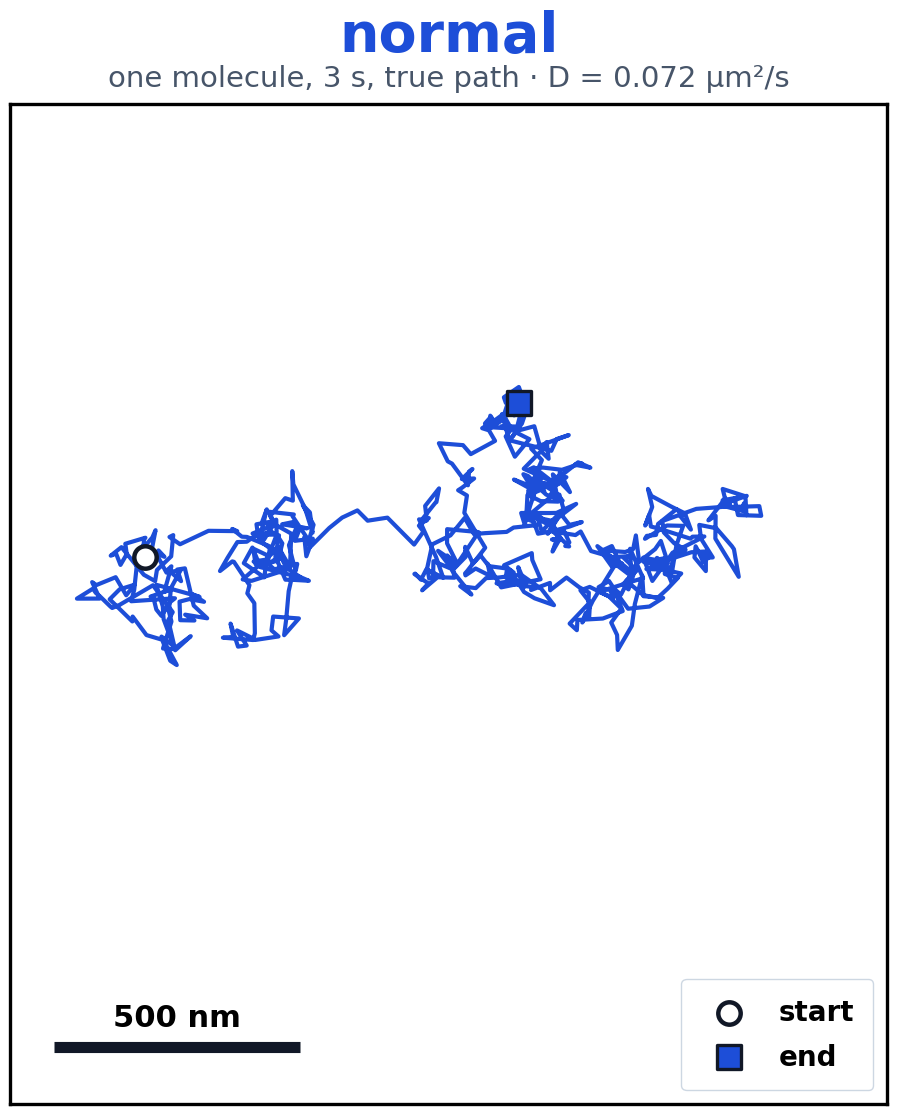

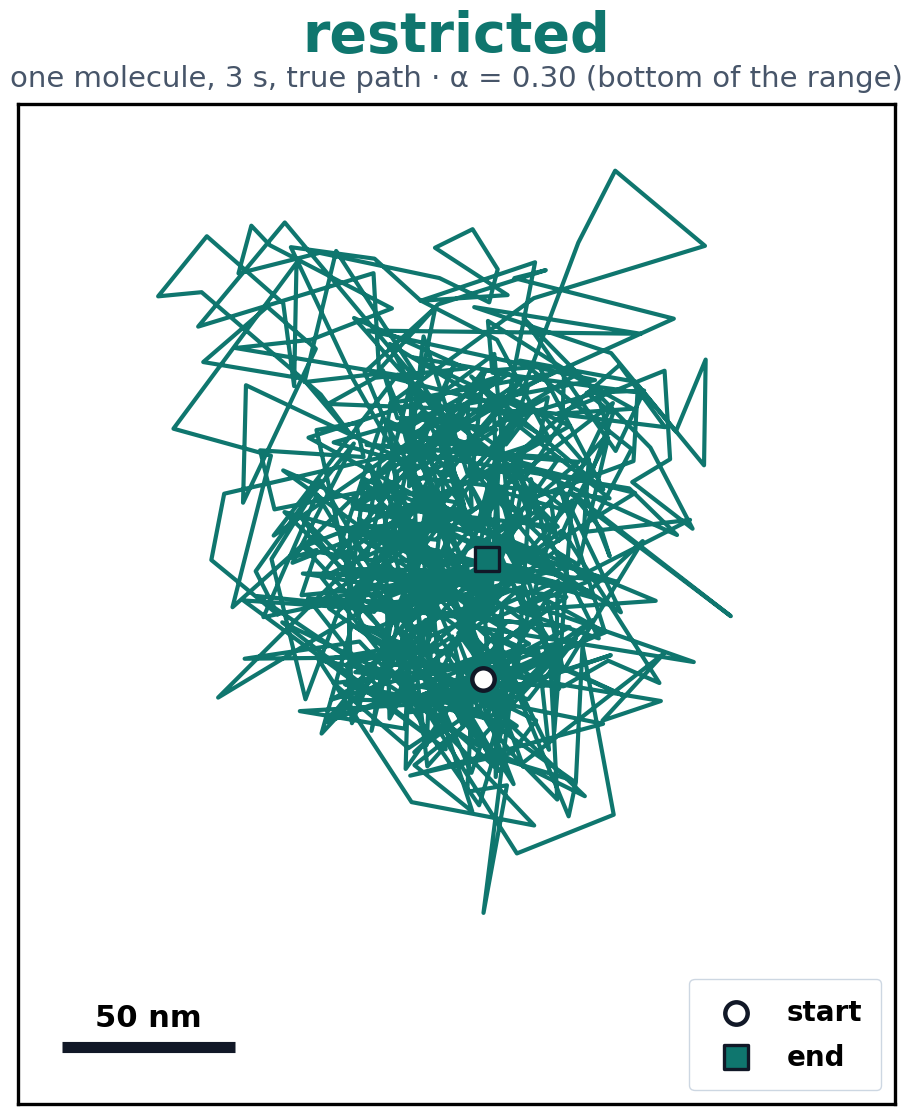

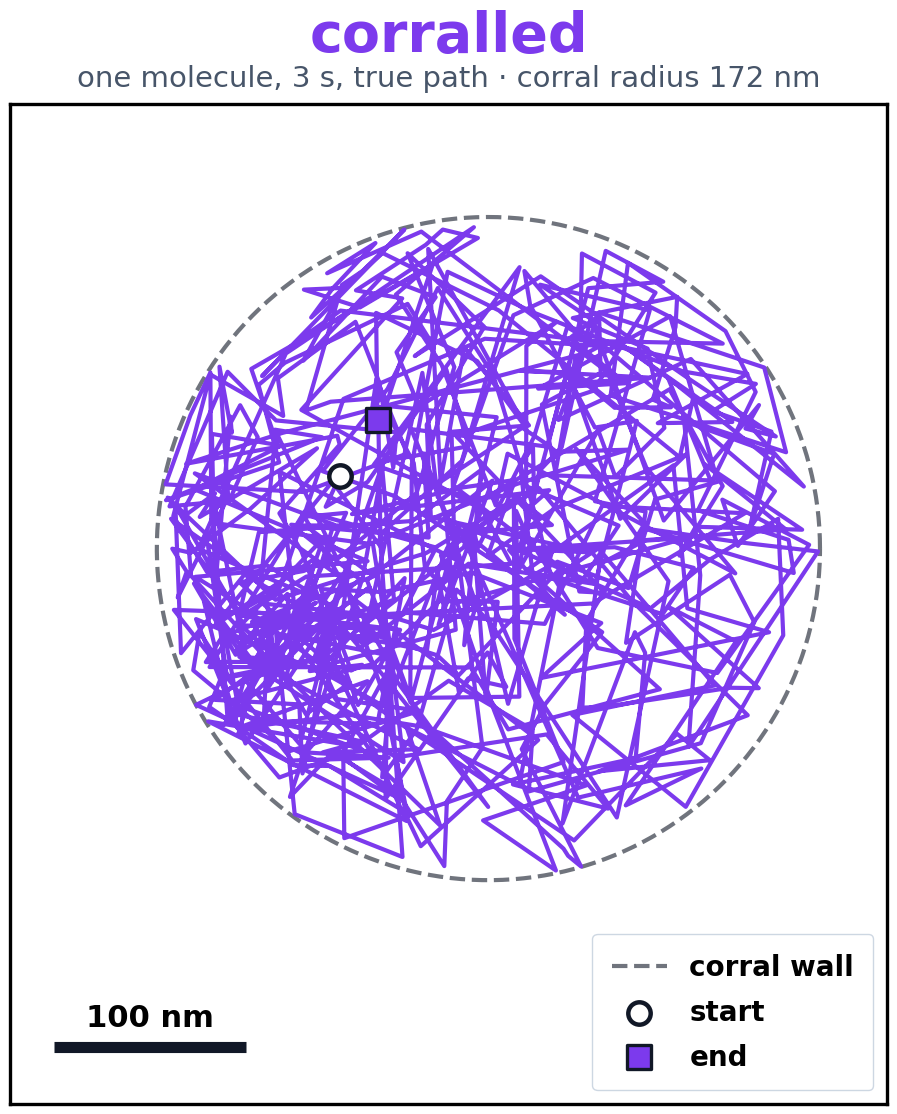

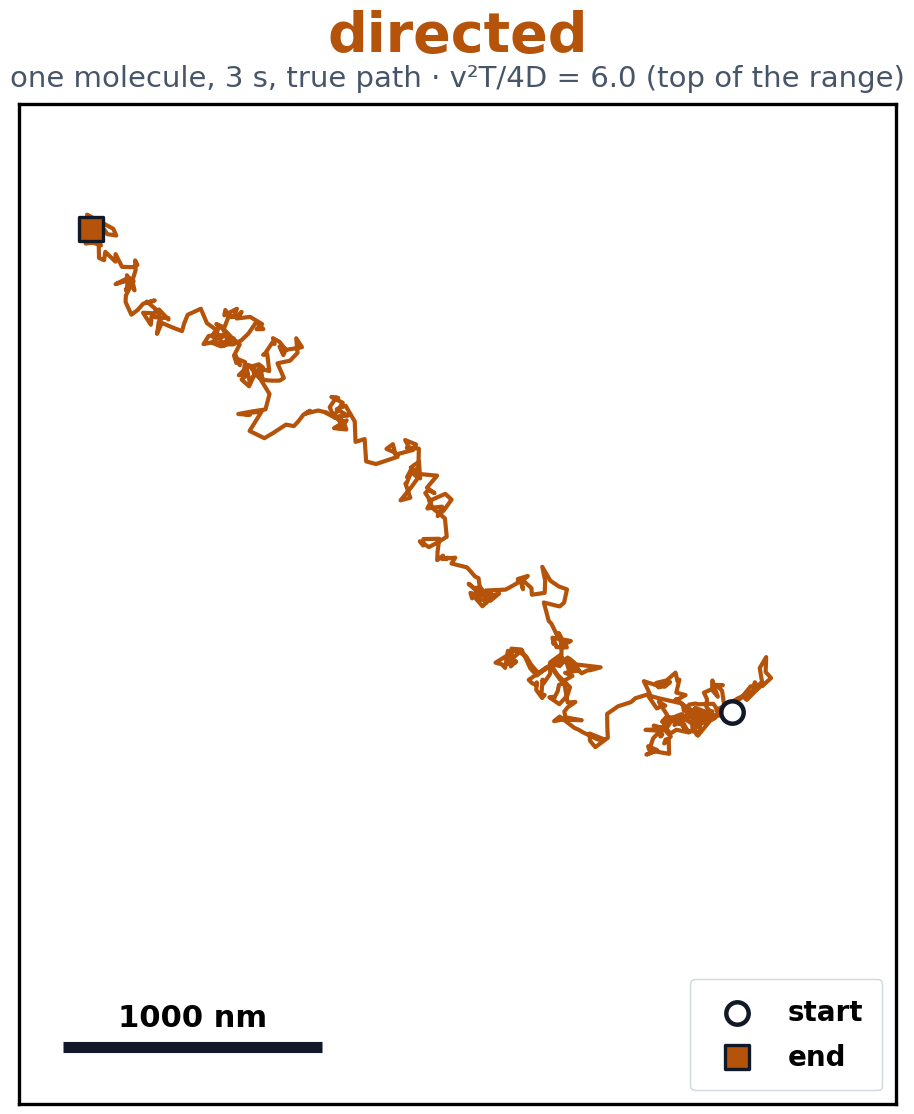

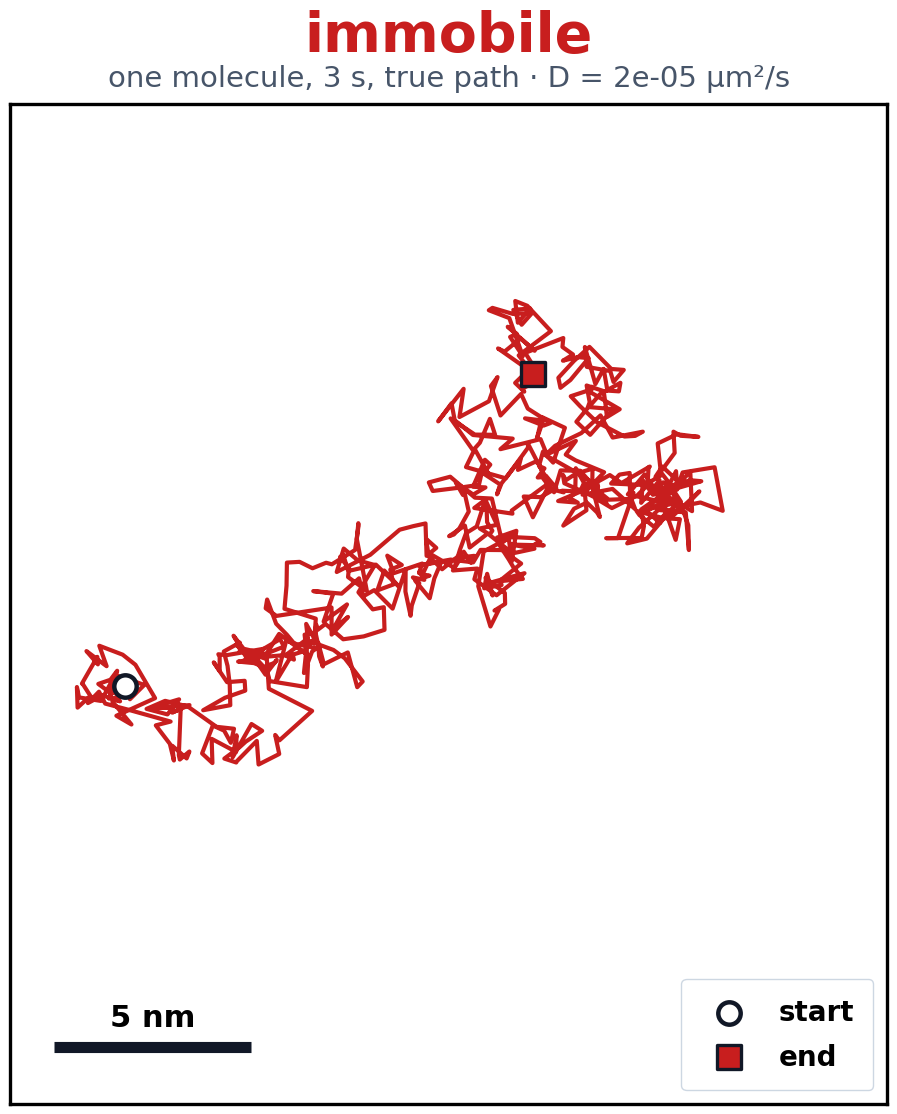

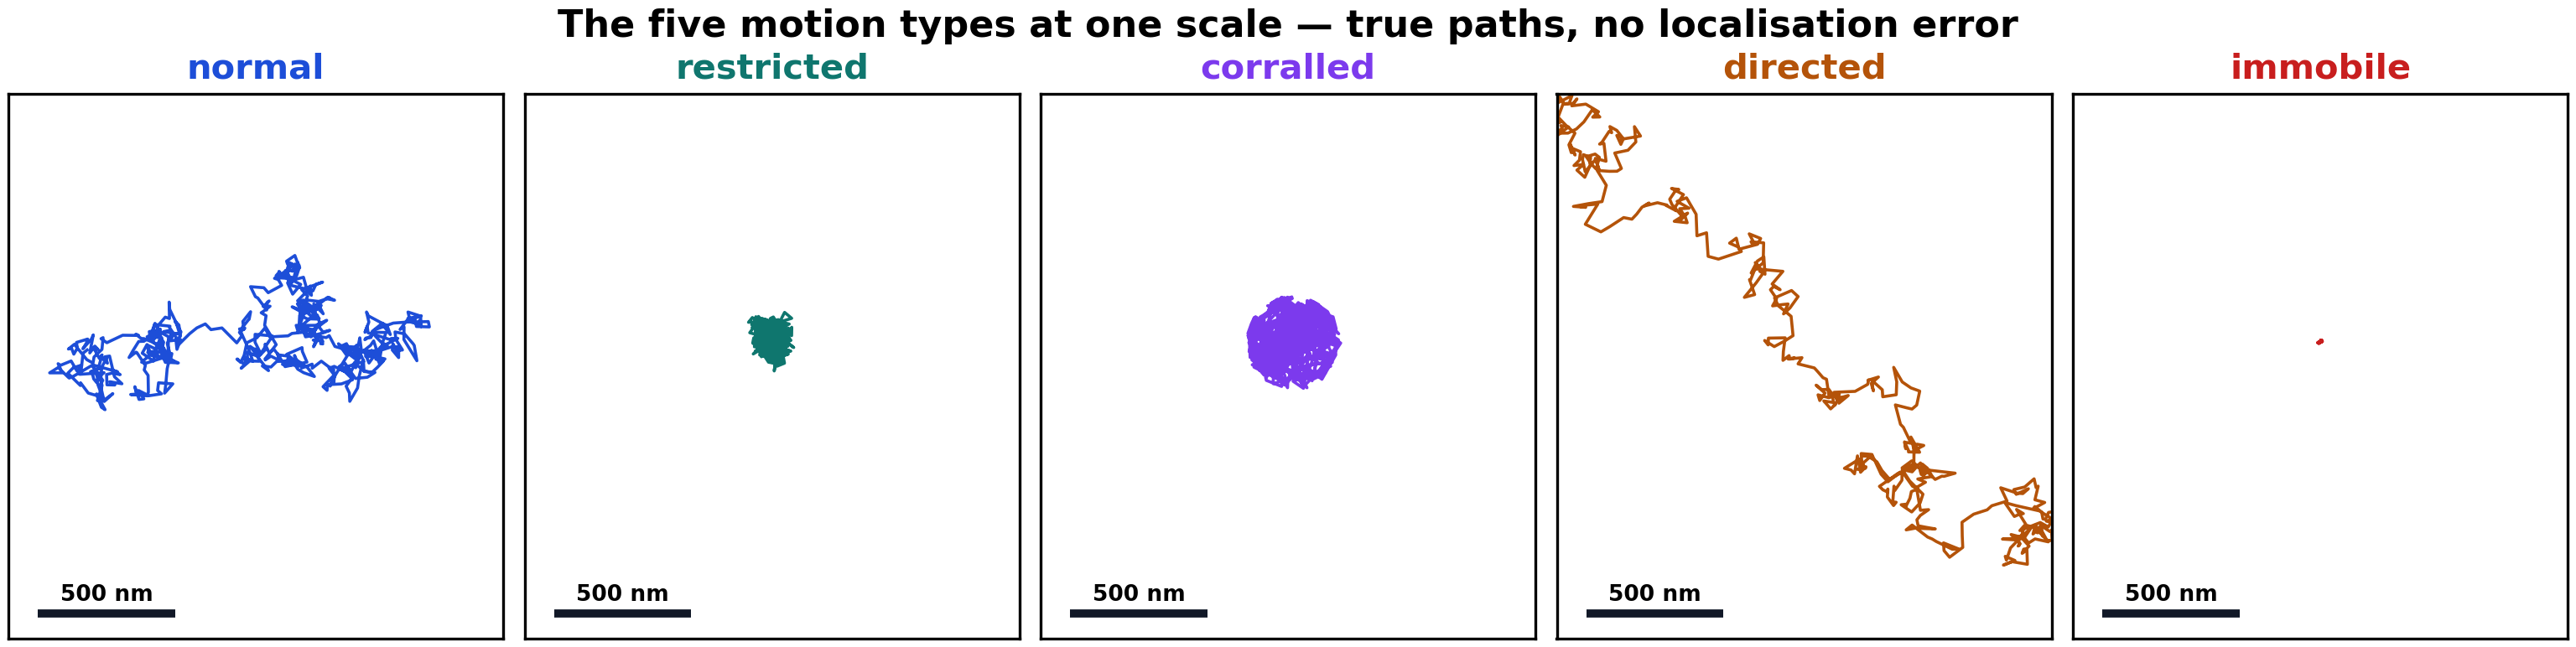

In [26]:
_rng = np.random.default_rng(SEED + 3)
N_SHOW = 600                      # 600 frames = 3 s, like a typical real track

# one molecule per class. The mean is kept as well as the path, because the
# drawing is centred on it and the corral wall has to be placed from the same
# point.
# For the gallery, each class is shown at the end of its range where the class
# is legible: directedness at the top, where the drift wins over the diffusion,
# and alpha at the bottom, where the subdiffusion is visible. At the other ends
# both look like ordinary diffusion - which is true of the classes and is why
# they are hard to tell apart, but it makes a poor picture of what they mean.
# The library still draws across the whole range; this is an illustration.
SHOWCASE = {"directed": ("directedness", DIRECTEDNESS[1]),
            "restricted": ("alpha", ALPHA_RANGE[0])}

tracks = {}
for k in CLASSES:
    p = draw_params(k, N_SHOW, DT_S, _rng, vary=False, slow_ok=False)
    if k == "corralled":
        p["p_escape"] = 0.0          # one corral, so the wall can be drawn
    if k in SHOWCASE:
        field, value = SHOWCASE[k]
        p[field] = value
        if k == "directed":          # the velocity follows from directedness
            p["v"] = float(np.sqrt(4 * p["D"] * value / (N_SHOW * DT_S)))
    P = PATH[k](N_SHOW, DT_S, p, _rng)
    tracks[k] = (P, p, P.mean(0))

def value_of(k, p):
    if k == "normal":     return f"D = {p['D']:.3f} \u00b5m\u00b2/s"
    if k == "restricted": return f"\u03b1 = {p['alpha']:.2f}"
    if k == "corralled":  return f"corral radius {1000*p['R']:.0f} nm"
    if k == "directed":   return f"v\u00b2T/4D = {p['directedness']:.1f}"
    return f"D = {p['D']:.0e} \u00b5m\u00b2/s"

SPAN = {}
for k in CLASSES:
    Praw, p, mu = tracks[k]
    C = 1000 * (Praw - mu)                       # nm, centred on the path
    reach = np.abs(C).max()
    if k == "corralled":                          # the wall has to fit too
        wx, wy = 1000 * (p["centre"] - mu)
        reach = max(reach, np.hypot(wx, wy) + 1000 * p["R"])
    SPAN[k] = 2 * reach
    m = reach * 1.18

    fig, ax = plt.subplots(figsize=(10.5, 11.4))
    if k == "corralled":
        th = np.linspace(0, 2 * np.pi, 400)
        ax.plot(wx + 1000 * p["R"] * np.cos(th), wy + 1000 * p["R"] * np.sin(th),
                ls="--", lw=3, color="#111827", alpha=.6, zorder=2,
                label="corral wall")
    ax.plot(C[:, 0], C[:, 1], lw=3, color=COL[k], solid_joinstyle="round",
            zorder=3, label="_nolegend_")
    ax.scatter(C[0, 0], C[0, 1], s=260, marker="o", facecolor="white",
               edgecolor="#111827", lw=3.2, zorder=6, label="start")
    ax.scatter(C[-1, 0], C[-1, 1], s=290, marker="s", facecolor=COL[k],
               edgecolor="#111827", lw=2.4, zorder=6, label="end")

    # a strip below the data: the scale bar and the legend live there, so
    # nothing is ever drawn over the molecule
    ax.set_xlim(-m, m); ax.set_ylim(-m * 1.28, m)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_linewidth(2.4)

    raw = 2 * m * 0.24
    e = 10 ** np.floor(np.log10(raw))
    L = min([1, 2, 5, 10], key=lambda q: abs(q * e - raw)) * e
    yb = -m * 1.15
    ax.plot([-m * 0.90, -m * 0.90 + L], [yb, yb], lw=8, color="#111827",
            solid_capstyle="butt")
    ax.text(-m * 0.90 + L / 2, yb + m * 0.035, f"{L:.0f} nm", ha="center",
            va="bottom", fontsize=22, fontweight="bold")

    ax.set_title(k, fontsize=40, fontweight="bold", color=COL[k], pad=38)
    _edge = " (top of the range)" if k == "directed" else (
            " (bottom of the range)" if k == "restricted" else "")
    ax.text(0.5, 1.012,
            f"one molecule, 3 s, true path \u00b7 {value_of(k, p)}{_edge}",
            transform=ax.transAxes, ha="center", va="bottom", fontsize=21,
            color="#475569")
    leg = ax.legend(loc="lower right", fontsize=20, frameon=True,
                    framealpha=.95, edgecolor="#cbd5e1", borderpad=.7,
                    labelspacing=.6, handletextpad=.8)
    for t in leg.get_texts():
        t.set_fontweight("bold")
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"M9_{k}.png", bbox_inches="tight")

# --- and the five at one scale, so the classes can be compared --------------
fig, axes = plt.subplots(1, 5, figsize=(31, 7.6))
lim = 1000 * np.abs(tracks["normal"][0] - tracks["normal"][2]).max() * 1.2
for ax, k in zip(axes, CLASSES):
    Praw, p, mu = tracks[k]
    C = 1000 * (Praw - mu)
    ax.plot(C[:, 0], C[:, 1], lw=2.6, color=COL[k], solid_joinstyle="round")
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim * 1.20, lim)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_linewidth(2.4)
    ax.set_title(k, fontsize=30, fontweight="bold", color=COL[k], pad=14)
    raw = 2 * lim * 0.26
    e = 10 ** np.floor(np.log10(raw))
    L = min([1, 2, 5, 10], key=lambda q: abs(q * e - raw)) * e
    yb = -lim * 1.10
    ax.plot([-lim * 0.88, -lim * 0.88 + L], [yb, yb], lw=7, color="#111827",
            solid_capstyle="butt")
    ax.text(-lim * 0.88 + L / 2, yb + lim * 0.035, f"{L:.0f} nm", ha="center",
            va="bottom", fontsize=19, fontweight="bold")
fig.suptitle("The five motion types at one scale \u2014 true paths, "
             "no localisation error", fontsize=32, fontweight="bold", y=1.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "M9_motion_types.png", bbox_inches="tight")

print("one molecule per motion type:")
for k in CLASSES:
    print(f"   M9_{k:11s}.png   spans {SPAN[k]:8.0f} nm")
print("   M9_motion_types.png   all five, one scale")

## 2b. The five motion types, drawn at stated values

Everywhere else the parameters are drawn from measured pools and differ track
to track, which is what a training set needs and what a figure cannot show.
Here each class appears once at a single named value, so the picture can be
described in a caption.

| type | model | value shown |
|---|---|---|
| normal | Brownian diffusion | D = 0.118 µm²/s — my measured median mobile D |
| restricted | fractional Gaussian noise | α = 0.60, inside my 0.3–0.9 range |
| corralled | reflecting circular boundary | R = 119 nm — my measured median corral radius |
| directed | Brownian diffusion plus a constant velocity | v²T/4D = 3.5, inside my 1–6 range |
| immobile | very slow Brownian motion | D = 10⁻⁷ µm²/s — the very-slow population |

**Imaging conditions:** 600 frames over 3 s at 5 ms per frame, with 40 nm
localisation error per coordinate.

Nothing in this section feeds the library, the reference or any result. It
only draws.

In [27]:
# --- the values this section shows, all in one place ------------------------
SHOW_N      = 600       # frames
SHOW_DT     = 0.005     # s, so 3 s in total
SHOW_SIGMA  = 0.040     # um per coordinate
SHOW_PARAMS = {
    "normal":     {"D": 0.118},
    "restricted": {"D": 0.118, "alpha": 0.60, "mechanism": "fgn"},
    "corralled":  {"D": 0.118, "R": 0.119, "centre": np.zeros(2)},
    "directed":   {"D": 0.118, "directedness": 3.5,
                   "v": float(np.sqrt(4 * 0.118 * 3.5 / (600 * 0.005))),
                   "theta": 0.6},
    "immobile":   {"D": 1e-7, "population": "still"},
}
SHOW_CAPTION = {
    "normal":     "Brownian diffusion, D = 0.118 um2/s, my measured median "
                  "mobile diffusion coefficient",
    "restricted": "fractional Gaussian noise with alpha = 0.60, inside my "
                  "0.3-0.9 range",
    "corralled":  "reflecting circular boundary of radius 119 nm, my measured "
                  "median corral radius",
    "directed":   "Brownian diffusion plus a constant velocity, directedness "
                  "v2T/4D = 3.5, inside my 1-6 range",
    "immobile":   "very slow Brownian motion, D = 1e-7 um2/s, the very-slow "
                  "population",
}
SHOW_VALUE = {"normal": "D = 0.118 \u00b5m\u00b2/s", "restricted": "\u03b1 = 0.60",
              "corralled": "R = 119 nm", "directed": "v\u00b2T/4D = 3.5",
              "immobile": "D = 10\u207b\u2077 \u00b5m\u00b2/s"}

_srng = np.random.default_rng(SEED + 404)
show = {}
for k in CLASSES:
    Pt = PATH[k](SHOW_N, SHOW_DT, SHOW_PARAMS[k], _srng)
    obs = Pt + _srng.normal(0, SHOW_SIGMA, Pt.shape)
    show[k] = (Pt - Pt.mean(0), obs - Pt.mean(0), SHOW_PARAMS[k])

print("the five motion types, at stated values")
print(f"600 frames over 3 s at {1000*SHOW_DT:.0f} ms, "
      f"{1000*SHOW_SIGMA:.0f} nm localisation error per coordinate")
print()
for k in CLASSES:
    T, O, _ = show[k]
    print(f"   {k:11s} true path spans {2000*np.abs(T).max():6.0f} nm, "
          f"recorded {2000*np.abs(O).max():6.0f} nm")

the five motion types, at stated values
600 frames over 3 s at 5 ms, 40 nm localisation error per coordinate

   normal      true path spans   1262 nm, recorded   1318 nm
   restricted  true path spans    801 nm, recorded    850 nm
   corralled   true path spans    239 nm, recorded    417 nm
   directed    true path spans   2656 nm, recorded   2729 nm
   immobile    true path spans      3 nm, recorded    238 nm



CAPTION (also saved to tables/visualisation_caption.txt)

The five motion types PiMoTIF simulates. Normal: Brownian diffusion, D = 0.118 um2/s, my
measured median mobile diffusion coefficient. Restricted: fractional Gaussian noise with
alpha = 0.60, inside my 0.3-0.9 range. Corralled: reflecting circular boundary of radius
119 nm, my measured median corral radius. Directed: Brownian diffusion plus a constant
velocity, directedness v2T/4D = 3.5, inside my 1-6 range. Immobile: very slow Brownian
motion, D = 1e-7 um2/s, the very-slow population. Imaging conditions: 600 frames over 3
s at 5 ms per frame, with 40 nm localisation error per coordinate.


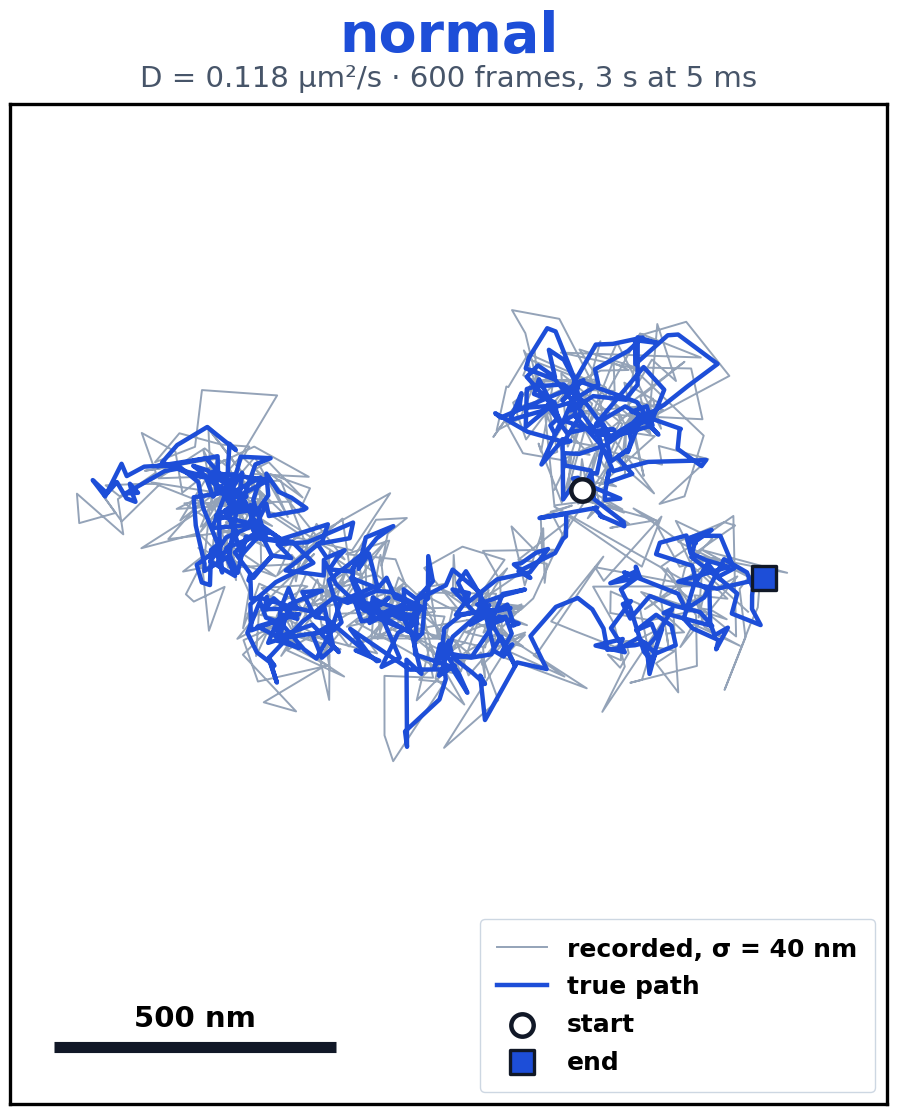

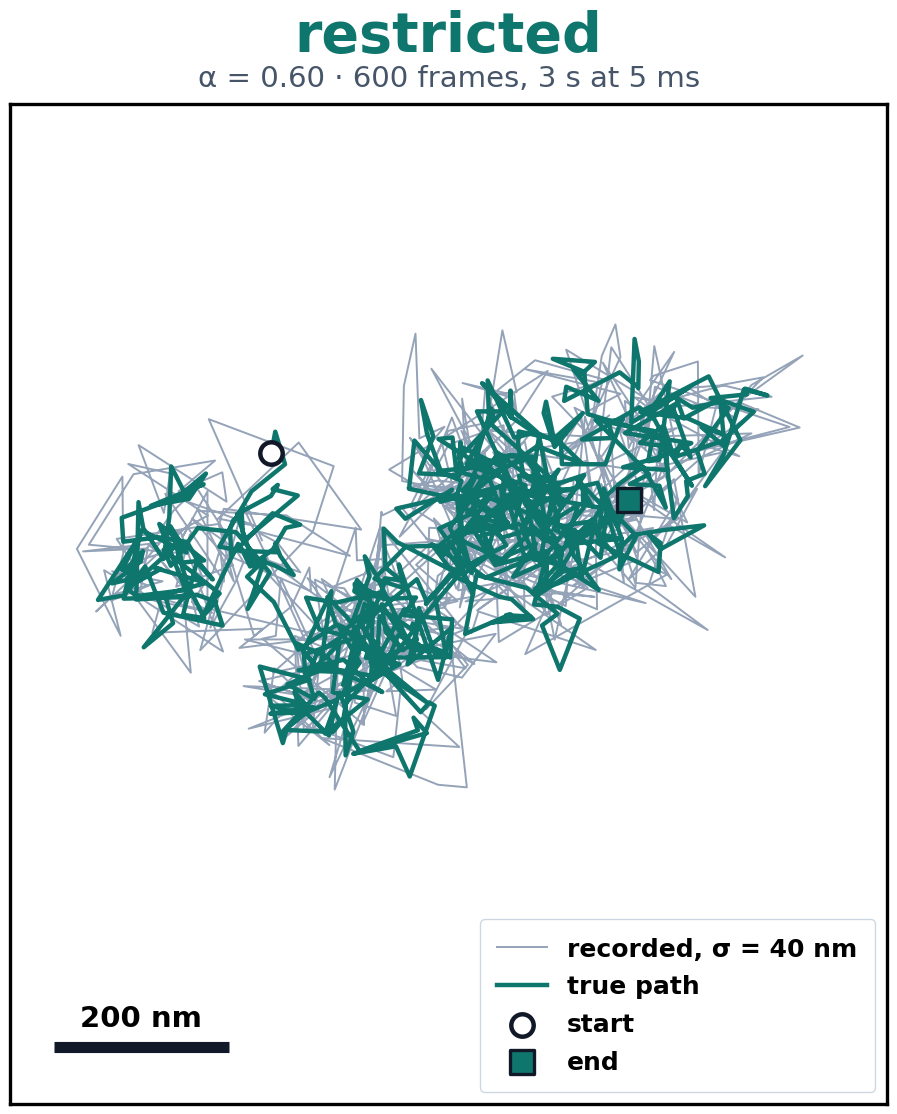

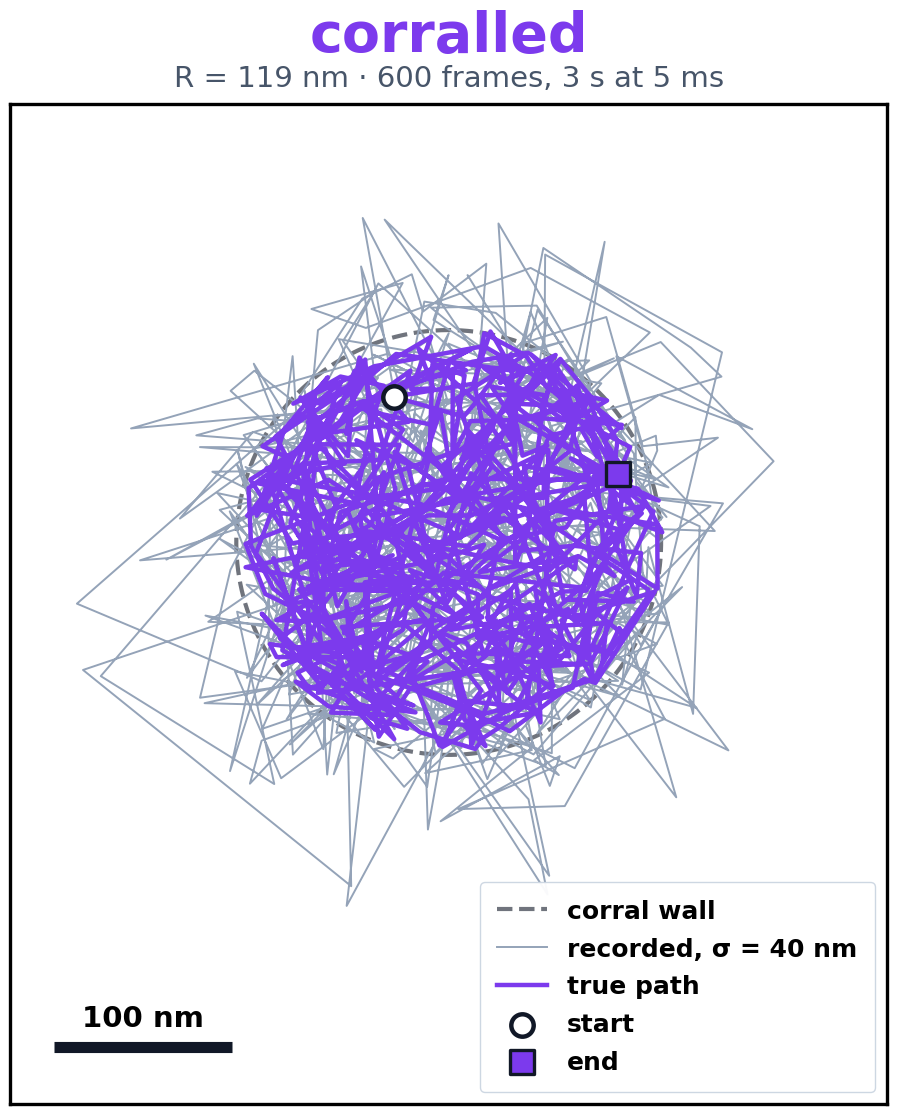

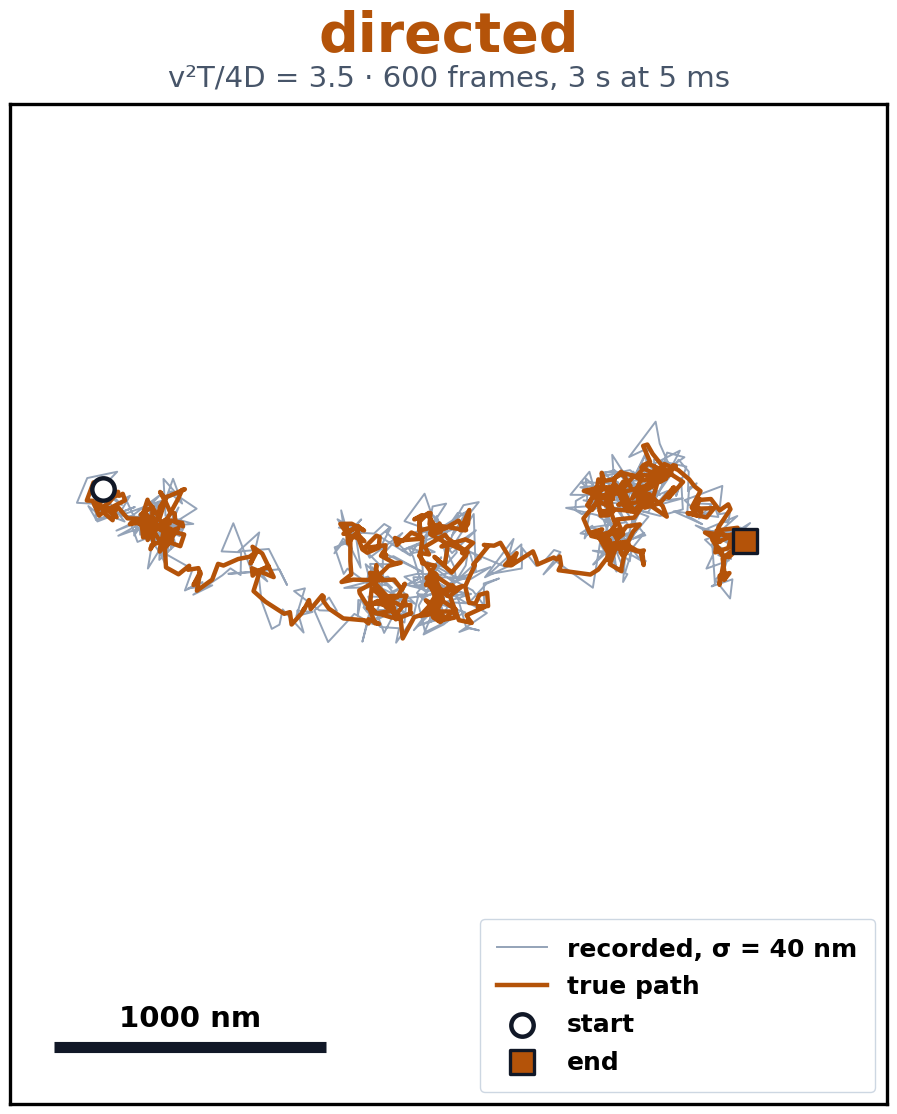

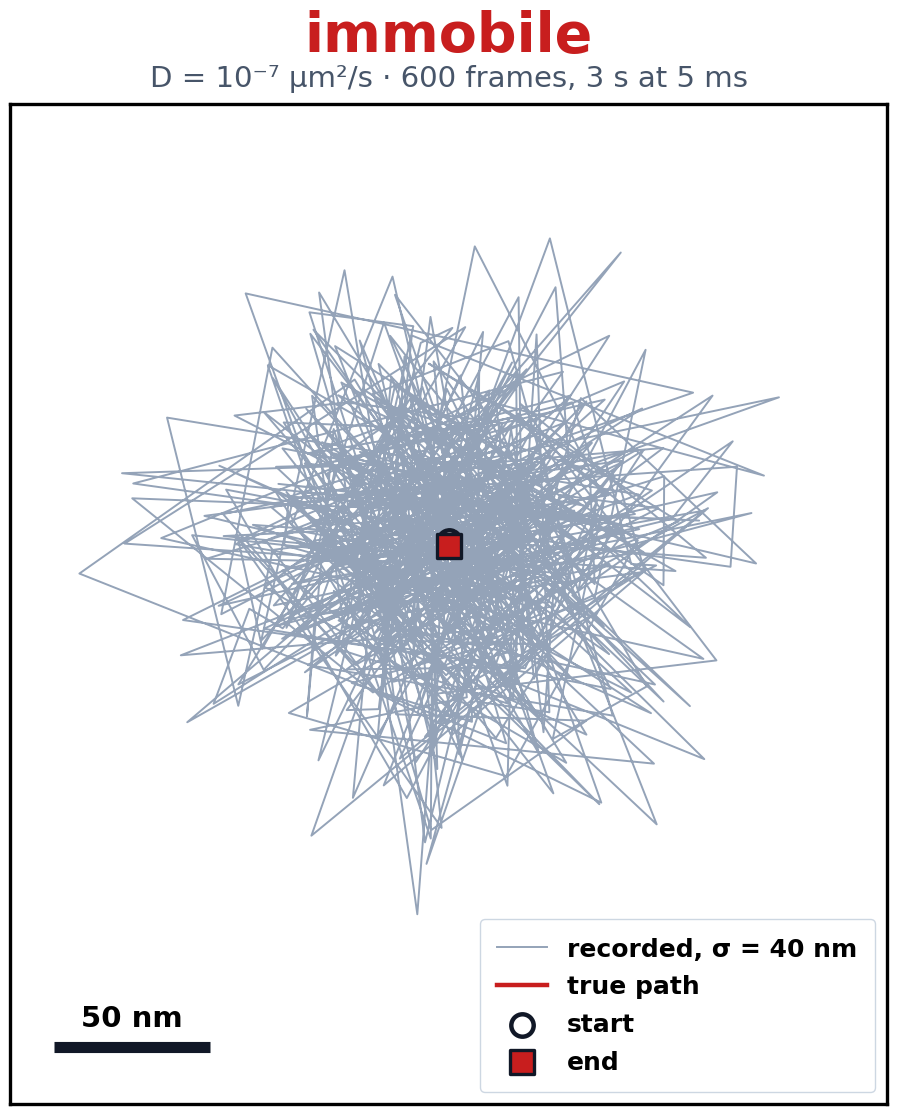

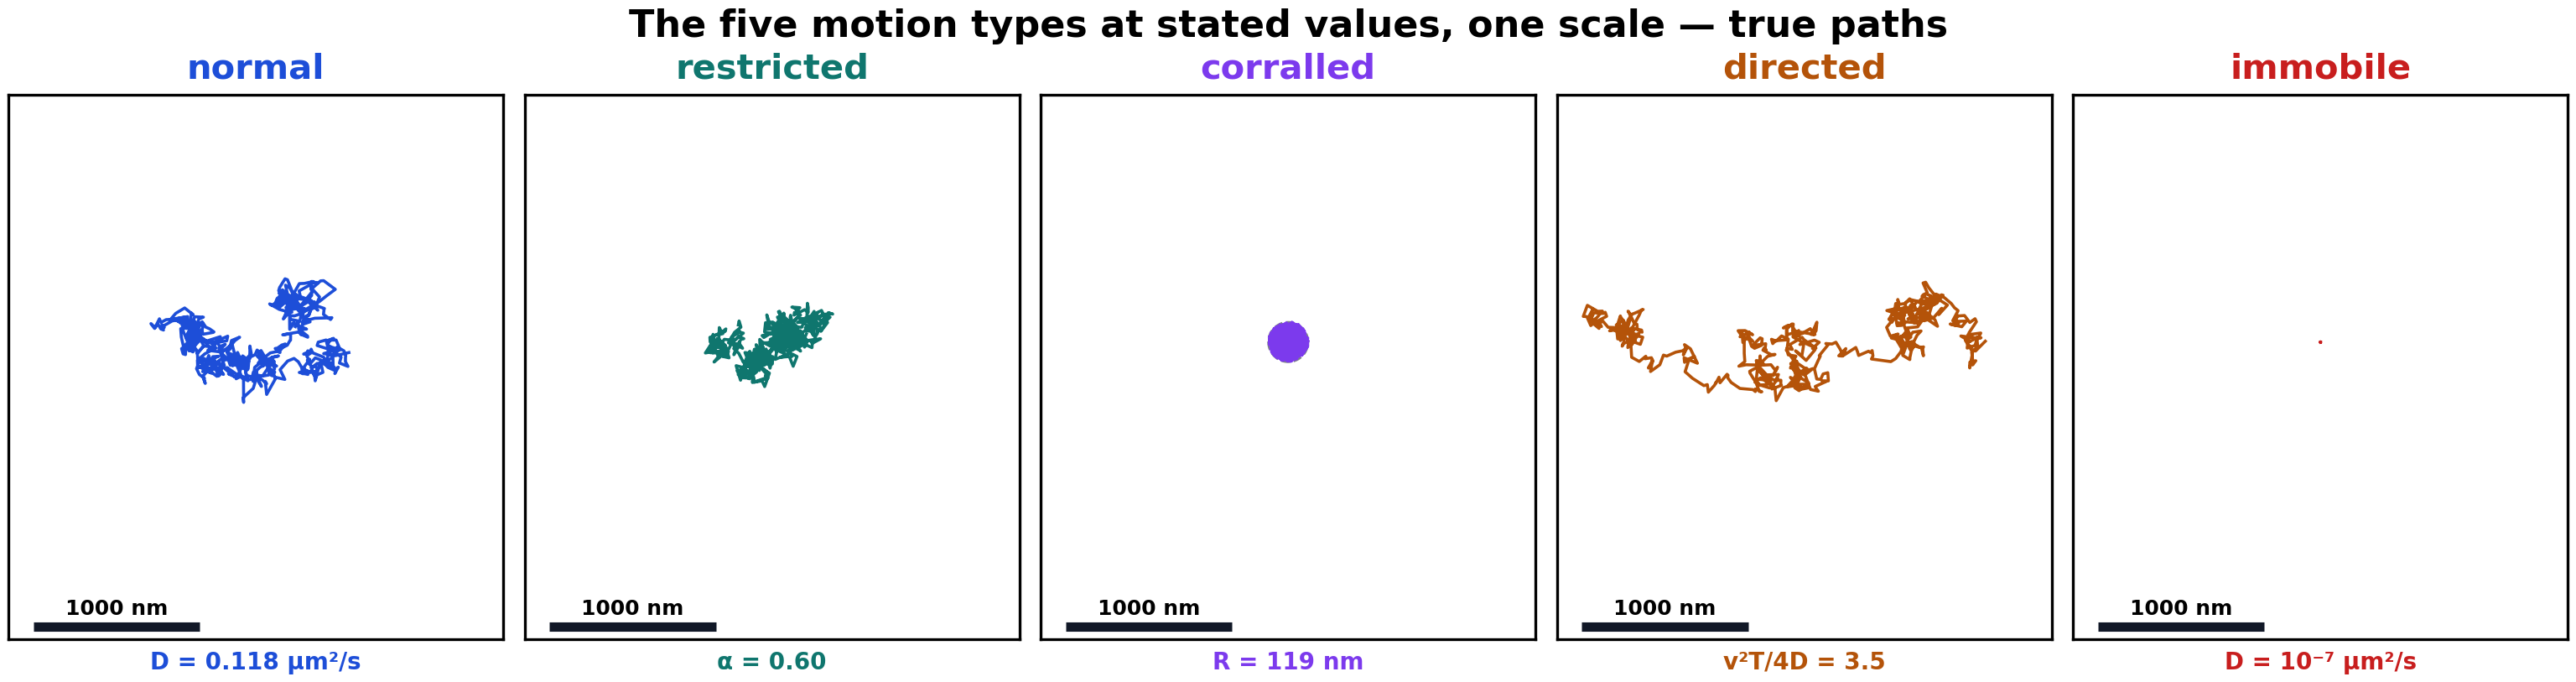

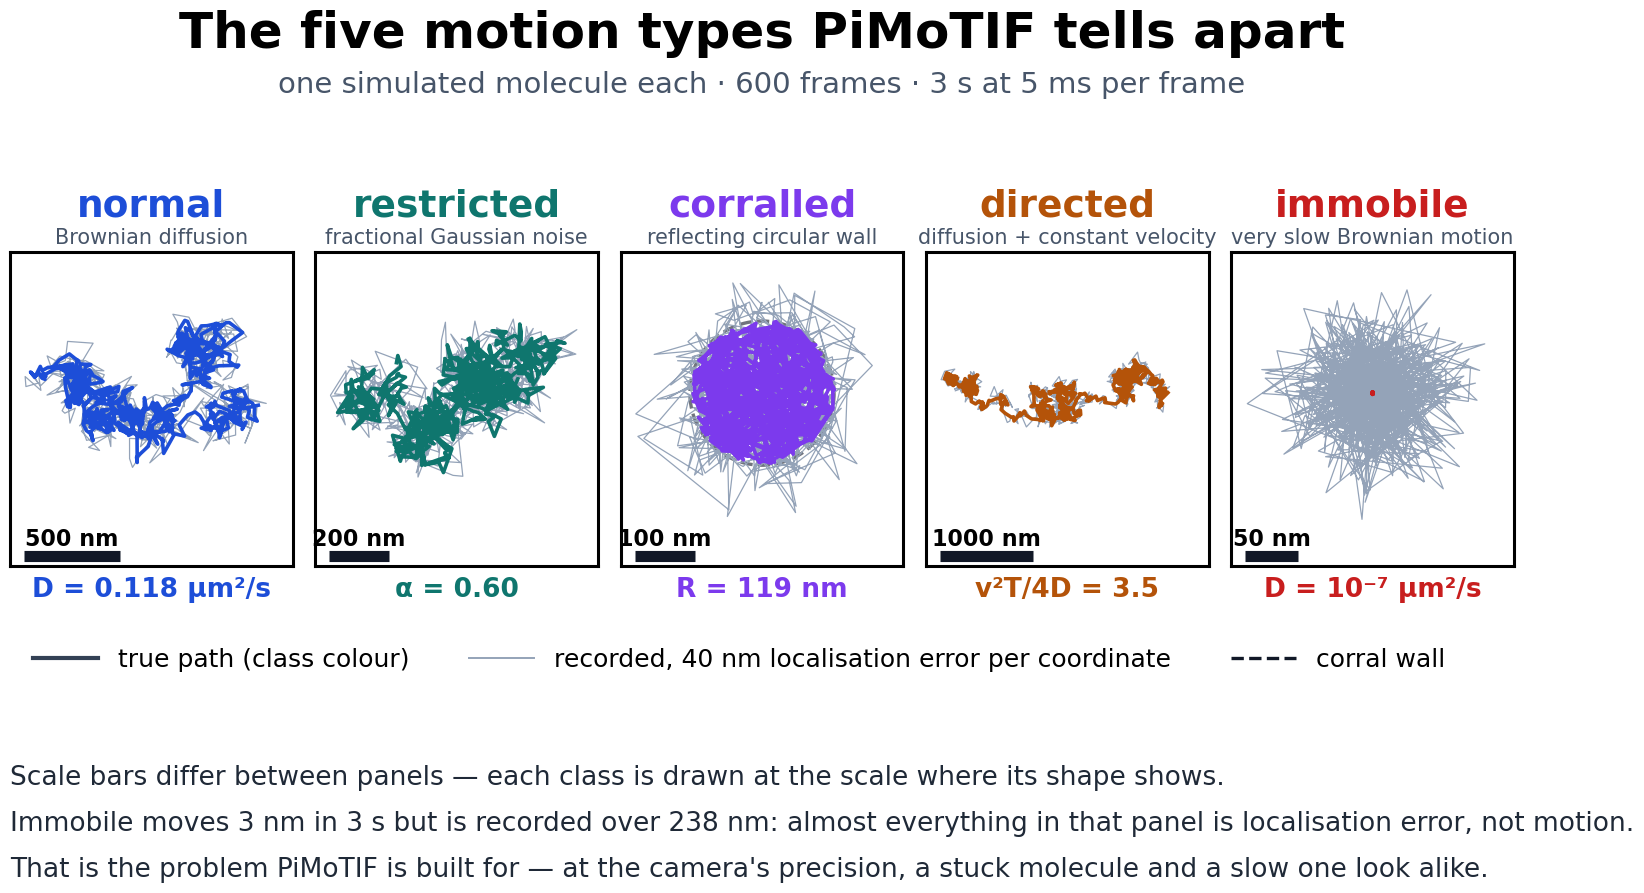

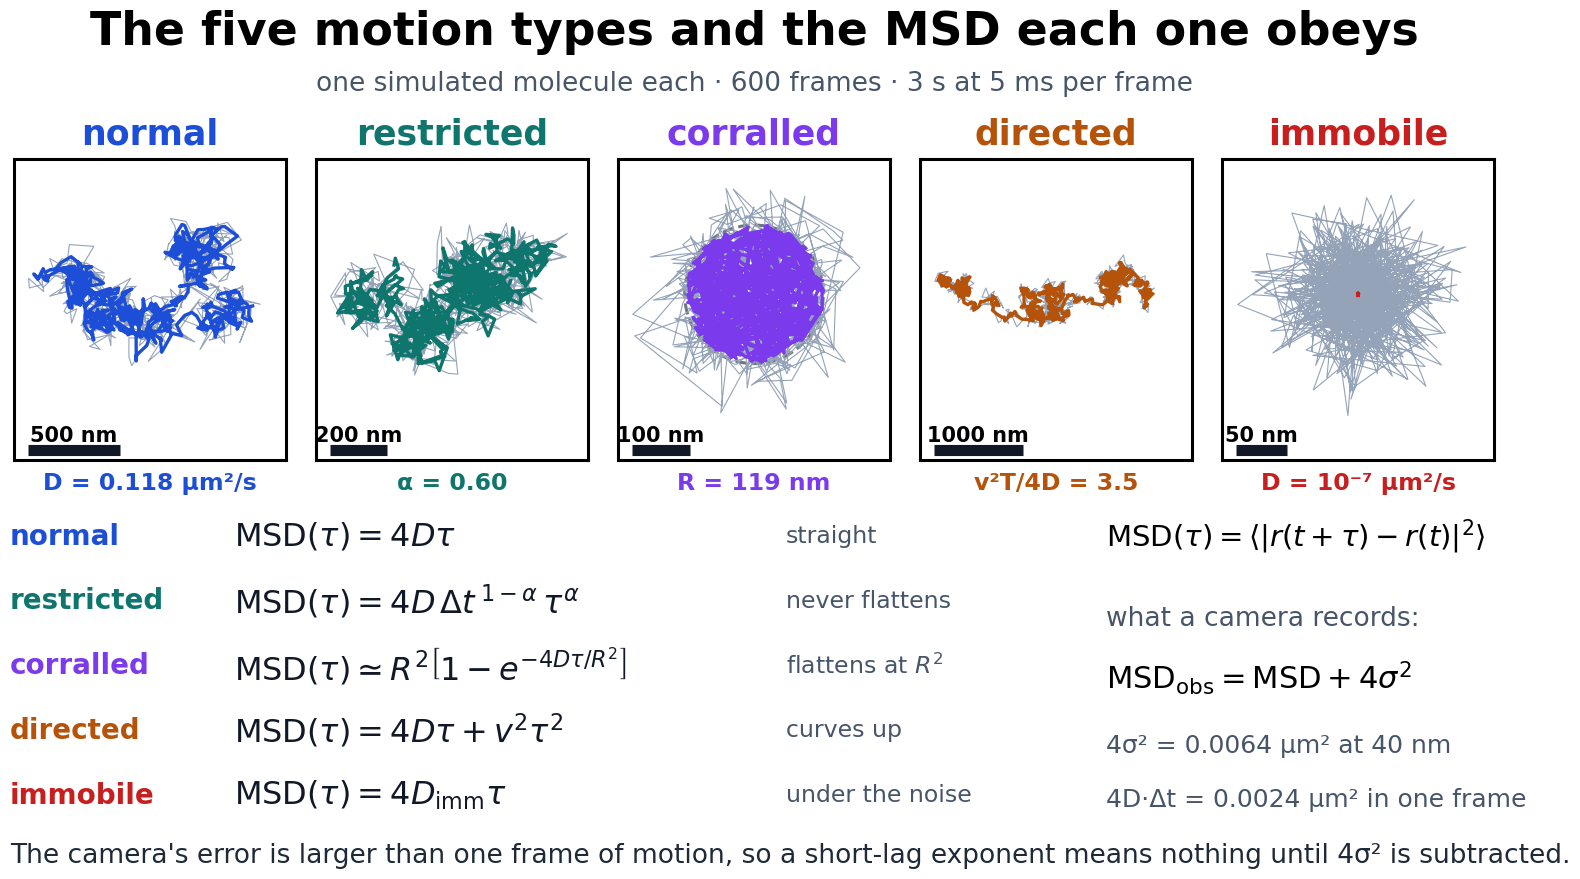

In [28]:
def _bar(ax, m, frac=0.24, fs=21):
    raw = 2 * m * frac
    e = 10 ** np.floor(np.log10(raw))
    L = min([1, 2, 5, 10], key=lambda q: abs(q * e - raw)) * e
    yb = -m * 1.15
    ax.plot([-m * 0.90, -m * 0.90 + L], [yb, yb], lw=8, color="#111827",
            solid_capstyle="butt")
    ax.text(-m * 0.90 + L / 2, yb + m * 0.035, f"{L:.0f} nm", ha="center",
            va="bottom", fontsize=fs, fontweight="bold")

for k in CLASSES:
    T, O, p = show[k]
    reach = 1000 * np.abs(O).max()
    if k == "corralled":
        reach = max(reach, 1000 * p["R"] * 1.1)
    m = reach * 1.18

    fig, ax = plt.subplots(figsize=(10.5, 11.4))
    if k == "corralled":
        th = np.linspace(0, 2 * np.pi, 400)
        ax.plot(1000 * p["R"] * np.cos(th), 1000 * p["R"] * np.sin(th),
                ls="--", lw=3, color="#111827", alpha=.6, zorder=2,
                label="corral wall")
    ax.plot(1000 * O[:, 0], 1000 * O[:, 1], lw=1.4, color="#94a3b8",
            zorder=2, label=f"recorded, \u03c3 = {1000*SHOW_SIGMA:.0f} nm")
    ax.plot(1000 * T[:, 0], 1000 * T[:, 1], lw=3.2, color=COL[k],
            solid_joinstyle="round", zorder=3, label="true path")
    ax.scatter(1000 * T[0, 0], 1000 * T[0, 1], s=260, marker="o",
               facecolor="white", edgecolor="#111827", lw=3.2, zorder=6,
               label="start")
    ax.scatter(1000 * T[-1, 0], 1000 * T[-1, 1], s=290, marker="s",
               facecolor=COL[k], edgecolor="#111827", lw=2.4, zorder=6,
               label="end")

    ax.set_xlim(-m, m); ax.set_ylim(-m * 1.28, m)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_linewidth(2.4)
    _bar(ax, m)
    ax.set_title(k, fontsize=40, fontweight="bold", color=COL[k], pad=38)
    ax.text(0.5, 1.012, f"{SHOW_VALUE[k]} \u00b7 600 frames, 3 s at 5 ms",
            transform=ax.transAxes, ha="center", va="bottom", fontsize=21,
            color="#475569")
    leg = ax.legend(loc="lower right", fontsize=18, frameon=True,
                    framealpha=.95, edgecolor="#cbd5e1", borderpad=.7,
                    labelspacing=.55)
    for t in leg.get_texts():
        t.set_fontweight("bold")
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"V_{k}.png", bbox_inches="tight")

# the five together, at one scale, true paths only
fig, axes = plt.subplots(1, 5, figsize=(31, 7.6))
# the widest of the five sets the scale, so nothing is cut off
lim = 1.12 * max(1000 * np.abs(show[k][0]).max() for k in CLASSES)
for ax, k in zip(axes, CLASSES):
    T, _, p = show[k]
    if k == "corralled":
        th = np.linspace(0, 2 * np.pi, 300)
        ax.plot(1000 * p["R"] * np.cos(th), 1000 * p["R"] * np.sin(th),
                ls="--", lw=2, color="#111827", alpha=.55)
    ax.plot(1000 * T[:, 0], 1000 * T[:, 1], lw=2.6, color=COL[k],
            solid_joinstyle="round")
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim * 1.20, lim)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_linewidth(2.4)
    ax.set_title(k, fontsize=30, fontweight="bold", color=COL[k], pad=14)
    ax.text(0.5, -0.02, SHOW_VALUE[k], transform=ax.transAxes, ha="center",
            va="top", fontsize=20, fontweight="bold", color=COL[k])
    _bar(ax, lim, frac=0.26, fs=18)
fig.suptitle("The five motion types at stated values, one scale \u2014 true paths",
             fontsize=32, fontweight="bold", y=1.02)
fig.tight_layout()
fig.savefig(FIG_DIR / "V_motion_types.png", bbox_inches="tight")

# --- and one 16:9 slide: all five, each at its own scale, explained ---------
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator

MODEL = {"normal":     "Brownian diffusion",
         "restricted": "fractional Gaussian noise",
         "corralled":  "reflecting circular wall",
         "directed":   "diffusion + constant velocity",
         "immobile":   "very slow Brownian motion"}

fig = plt.figure(figsize=(16, 9), facecolor="white")
gs = fig.add_gridspec(2, 5, height_ratios=[1.0, 0.34], hspace=0.02,
                      wspace=0.08, left=0.03, right=0.97, top=0.83,
                      bottom=0.04)
fig.text(0.5, 0.955, "The five motion types PiMoTIF tells apart",
         ha="center", va="center", fontsize=36, fontweight="bold")
fig.text(0.5, 0.898,
         "one simulated molecule each · 600 frames · 3 s at 5 ms per frame",
         ha="center", va="center", fontsize=21, color="#475569")

for j, k in enumerate(CLASSES):
    T, O, p = show[k]
    ax = fig.add_subplot(gs[0, j])
    reach = 1000 * np.abs(O).max()
    if k == "corralled":
        reach = max(reach, 1000 * p["R"] * 1.1)
    m = reach * 1.12
    if k == "corralled":
        th = np.linspace(0, 2 * np.pi, 400)
        ax.plot(1000 * p["R"] * np.cos(th), 1000 * p["R"] * np.sin(th),
                ls="--", lw=2.4, color="#111827", alpha=.6, zorder=2)
    ax.plot(1000 * O[:, 0], 1000 * O[:, 1], lw=0.9, color="#94a3b8", zorder=2)
    ax.plot(1000 * T[:, 0], 1000 * T[:, 1], lw=2.6, color=COL[k],
            solid_joinstyle="round", zorder=3)
    ax.set_xlim(-m, m); ax.set_ylim(-m * 1.22, m)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_linewidth(2.2)
    _bar(ax, m, frac=0.26, fs=16)
    ax.set_title(k, fontsize=27, fontweight="bold", color=COL[k], pad=26)
    ax.text(0.5, 1.015, MODEL[k], transform=ax.transAxes, ha="center",
            va="bottom", fontsize=15, color="#475569")
    ax.text(0.5, -0.035, SHOW_VALUE[k], transform=ax.transAxes, ha="center",
            va="top", fontsize=19, fontweight="bold", color=COL[k])

axb = fig.add_subplot(gs[1, :]); axb.axis("off")
axb.set_xlim(0, 1); axb.set_ylim(0, 1)
axb.legend(handles=[
    Line2D([], [], color="#334155", lw=3, label="true path (class colour)"),
    Line2D([], [], color="#94a3b8", lw=1.4,
           label="recorded, 40 nm localisation error per coordinate"),
    Line2D([], [], color="#111827", lw=2.4, ls="--", label="corral wall")],
    loc="upper left", bbox_to_anchor=(0.0, 1.30), ncol=3, frameon=False,
    fontsize=18, handlelength=2.6, columnspacing=2.4)

_im_true = 2000 * np.abs(show["immobile"][0]).max()
_im_rec = 2000 * np.abs(show["immobile"][1]).max()
for y, txt in [
    (0.52, "Scale bars differ between panels — each class is drawn at the "
           "scale where its shape shows."),
    (0.26, f"Immobile moves {_im_true:.0f} nm in 3 s but is recorded over "
           f"{_im_rec:.0f} nm: almost everything in that panel is localisation "
           "error, not motion."),
    (0.00, "That is the problem PiMoTIF is built for — at the camera's "
            "precision, a stuck molecule and a slow one look alike.")]:
    axb.text(0.0, y, txt, fontsize=19, color="#1f2937", va="top")

fig.savefig(FIG_DIR / "V_slide.png", dpi=200, facecolor="white",
            bbox_inches="tight")

# --- the same slide, with the MSD each class obeys --------------------------
EQN = {
    "normal":     r"$\mathrm{MSD}(\tau)=4D\tau$",
    "restricted": r"$\mathrm{MSD}(\tau)=4D\,\Delta t^{\,1-\alpha}\,\tau^{\alpha}$",
    "corralled":  r"$\mathrm{MSD}(\tau)\simeq R^{2}\left[1-e^{-4D\tau/R^{2}}\right]$",
    "directed":   r"$\mathrm{MSD}(\tau)=4D\tau+v^{2}\tau^{2}$",
    "immobile":   r"$\mathrm{MSD}(\tau)=4D_{\mathrm{imm}}\tau$",
}
SAYS = {"normal":     "straight",
        "restricted": "never flattens",
        "corralled":  r"flattens at $R^{2}$",
        "directed":   "curves up",
        "immobile":   "under the noise"}

fig = plt.figure(figsize=(16, 9), facecolor="white")
gs = fig.add_gridspec(1, 5, wspace=0.08, left=0.035, right=0.965,
                      top=0.805, bottom=0.47)
fig.text(0.5, 0.945, "The five motion types and the MSD each one obeys",
         ha="center", va="center", fontsize=33, fontweight="bold")
fig.text(0.5, 0.888, "one simulated molecule each " + "\u00b7" +
         " 600 frames " + "\u00b7" + " 3 s at 5 ms per frame",
         ha="center", va="center", fontsize=19, color="#475569")

for j, k in enumerate(CLASSES):
    T, O, p = show[k]
    ax = fig.add_subplot(gs[0, j])
    reach = 1000 * np.abs(O).max()
    if k == "corralled":
        reach = max(reach, 1000 * p["R"] * 1.1)
    m = reach * 1.12
    if k == "corralled":
        th = np.linspace(0, 2 * np.pi, 400)
        ax.plot(1000 * p["R"] * np.cos(th), 1000 * p["R"] * np.sin(th),
                ls="--", lw=2.2, color="#111827", alpha=.6, zorder=2)
    ax.plot(1000 * O[:, 0], 1000 * O[:, 1], lw=0.8, color="#94a3b8", zorder=2)
    ax.plot(1000 * T[:, 0], 1000 * T[:, 1], lw=2.4, color=COL[k],
            solid_joinstyle="round", zorder=3)
    ax.set_xlim(-m, m); ax.set_ylim(-m * 1.22, m)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values():
        sp.set_linewidth(2.2)
    _bar(ax, m, frac=0.26, fs=15)
    ax.set_title(k, fontsize=25, fontweight="bold", color=COL[k], pad=10)
    ax.text(0.5, -0.04, SHOW_VALUE[k], transform=ax.transAxes, ha="center",
            va="top", fontsize=17, fontweight="bold", color=COL[k])

# one line per class, in the class colour: name, equation, what it looks like
y = 0.385
for k in CLASSES:
    fig.text(0.035, y, k, fontsize=20, fontweight="bold", color=COL[k],
             va="center")
    fig.text(0.175, y, EQN[k], fontsize=23, color="#111827", va="center")
    fig.text(0.520, y, SAYS[k], fontsize=17, color="#475569", va="center")
    y -= 0.072

fig.text(0.72, 0.385,
         r"$\mathrm{MSD}(\tau)=\langle|r(t+\tau)-r(t)|^{2}\rangle$",
         fontsize=21, va="center")
fig.text(0.72, 0.293, "what a camera records:", fontsize=19, va="center",
         color="#475569")
fig.text(0.72, 0.228,
         r"$\mathrm{MSD}_{\mathrm{obs}}=\mathrm{MSD}+4\sigma^{2}$",
         fontsize=22, va="center")
fig.text(0.72, 0.152, "4" + "\u03c3" + "\u00b2" +
         f" = {4*SHOW_SIGMA**2:.4f} " + "\u00b5m\u00b2" +
         f" at {1000*SHOW_SIGMA:.0f} nm", fontsize=18, color="#475569",
         va="center")
fig.text(0.72, 0.092, "4D" + "\u00b7" + "\u0394t" +
         f" = {4*0.118*SHOW_DT:.4f} " + "\u00b5m\u00b2" + " in one frame",
         fontsize=18, color="#475569", va="center")

fig.text(0.035, 0.030, "The camera's error is larger than one frame of motion, "
         "so a short-lag exponent means nothing until 4" + "\u03c3\u00b2" +
         " is subtracted.", fontsize=19, color="#1f2937", va="center")

fig.savefig(FIG_DIR / "V_slide_equations.png", dpi=200, facecolor="white",
            bbox_inches="tight")

CAPTION = ("The five motion types PiMoTIF simulates. "
           + " ".join(f"{k.capitalize()}: {SHOW_CAPTION[k]}." for k in CLASSES)
           + f" Imaging conditions: {SHOW_N} frames over "
             f"{SHOW_N*SHOW_DT:.0f} s at {1000*SHOW_DT:.0f} ms per frame, with "
             f"{1000*SHOW_SIGMA:.0f} nm localisation error per coordinate.")
(TAB_DIR / "visualisation_caption.txt").write_text(CAPTION, encoding="utf-8")
print()
print("CAPTION (also saved to tables/visualisation_caption.txt)")
print()
import textwrap
print(textwrap.fill(CAPTION, 88))

## 3. The instrument — turning motion into a recording

**Blinking is measured, not modelled.** Every simulated track inherits a real
track's on/off pattern, so the dark states have my dye's statistics rather
than a model of them. I only ever *thin* a pattern to make a molecule blink
more; adding a detection where the real molecule was dark would be inventing
photophysics I have not observed.

**Re-thinning matters more than it looks.** Longer tracks have higher duty in
my data (r = +0.39), because a molecule that blinks a lot never survives my
200-detection filter. So a window cut from a long donor inherits that donor's
unusually clean blinking, and without re-thinning every short track in the
library would be unrealistically tidy.

**A molecule keeps moving while it is dark.** The motion is generated over
every frame a track spans, including the invisible ones, and only then are the
dark frames discarded. Generating only the visible frames would make every gap
a freeze, and the classifier would learn that blinking means stopping.

**Localisation error belongs to the molecule, not the recording.** Frame time,
density, exposure threshold and drift are properties of a movie and are drawn
once per movie. Precision is not: within one of my fields tracks span 11–95 nm
while the field medians span only 32–49, so most of the variation is how
bright each molecule is.

**Blinking, length and precision come from the cell being simulated, not
from the class.** A simulated live cell draws every class — immobile included
— from my live tracks; only the simulated fixed cells (the gate) draw from
fixed ones. Version 1 gave immobile molecules fixed-cell patterns and the
moving classes live ones, and the two pools differ (median 807 against 458
detections, duty 0.714 against 0.76), so track length alone pointed to
"immobile": a classifier could have learned the donor instead of the motion.
In a live cell an immobile molecule blinks like a live one.

**Localisation error is not constant along a track.** In my fixed cells it
changes between the first and last third of a track (section 1), so each
simulated track drifts its σ by a ratio drawn from that measurement.

Blinking from a real donor pattern, re-recorded at this track's frame time,
cut to length, re-thinned, then drift and localisation error.

In [29]:
def reframe(obs, dt, exposure_min):
    """Re-record a 5 ms frame pattern as if the camera ran at dt.

    Each new frame covers dt/DT_S old ones; the molecule is detected in it when
    it was visible for at least `exposure_min` of that span. At my own frame
    time this returns the pattern unchanged.
    """
    obs = np.asarray(obs, np.int64)
    if dt <= DT_S * 1.0001 or obs.size == 0:
        return obs
    span = int(obs[-1]) + 1
    on = np.zeros(span); on[obs] = 1.0
    c = np.concatenate([[0.0], np.cumsum(on)])
    def upto(x):
        x = np.clip(x, 0.0, float(span))
        i = np.clip(np.floor(x).astype(np.int64), 0, span - 1)
        return c[i] + (x - i) * on[i]
    k = dt / DT_S
    n_new = int(np.floor(span / k))
    if n_new < 2:
        return np.array([], np.int64)
    e = np.arange(n_new + 1) * k
    frac = (upto(e[1:]) - upto(e[:-1])) / k
    return np.flatnonzero(frac >= exposure_min).astype(np.int64)

def window_of(idx, n_target, rng):
    """Cut a donor's BLINKING PATTERN to about n_target detections, so the
    library reaches track lengths my own experiment never produced. This is
    not windowing for classification - that is notebook 02. None keeps the
    pattern whole: the references do, because one real donor carries its
    length, duty and gaps together.
    """
    idx = np.asarray(idx, np.int64)
    if n_target is None or idx.size <= n_target:
        return idx - (idx[0] if idx.size else 0)
    s = int(rng.integers(0, idx.size - n_target + 1))
    w = idx[s:s + n_target]
    return w - w[0]

def thin_to_duty(idx, duty_target, rng):
    """Drop detections until the pattern blinks as much as asked. Never adds."""
    idx = np.asarray(idx, np.int64)
    if idx.size <= MIN_SIM_DET:
        return idx
    span = int(idx[-1] - idx[0] + 1)
    if duty_target >= idx.size / span:
        return idx
    n_keep = int(max(MIN_SIM_DET, round(duty_target * span)))
    if n_keep >= idx.size:
        return idx
    mid = rng.choice(idx[1:-1], size=n_keep - 2, replace=False)
    return np.sort(np.concatenate([idx[:1], mid, idx[-1:]])).astype(np.int64)

# the direction my stage actually goes, field by field. Drawing from these
# reproduces the anisotropy - 46 of 52 fields creeping the same way in x -
# without my having to impose it.
DRIFT_ANGLES = np.arctan2(DRIFT_TAB.dy_um.to_numpy(),
                          DRIFT_TAB.dx_um.to_numpy())
N_FIELDS = 40          # simulated movies to spread the tracks across
_field_cache = {}

def field_drift(field_id, n_frames, scale):
    """One drift trajectory per movie, cached so its tracks share it."""
    key = (int(field_id), int(n_frames), round(float(scale), 4))
    if key not in _field_cache:
        r = np.random.default_rng(SEED + 9973 * key[0])
        total = float(r.choice(DRIFT)) * scale
        th = float(r.choice(DRIFT_ANGLES))
        tt = np.arange(n_frames)[:, None] / max(n_frames, 1)
        ramp = (total * (1 - WANDER_FRAC)
                * np.array([np.cos(th), np.sin(th)]) * tt)
        w = np.cumsum(r.normal(0, 1, (n_frames, 2)), axis=0)
        w = w / max(np.abs(w).max(), 1e-9) * total * WANDER_FRAC
        _field_cache[key] = (ramp + w, total, th)
    return _field_cache[key]

def drift_of(span, f0, rng, n_frames, scale=None, field_id=None):
    """The slice of this movie's drift over the frames a track was alive."""
    scale = 1.0 if scale is None else scale
    if field_id is None:                      # no field given: its own movie
        field_id = int(rng.integers(1_000_000))
    traj, total, th = field_drift(field_id, n_frames, scale)
    f0 = int(min(f0, max(n_frames - span, 0)))     # never run off the end
    sl = traj[f0:f0 + span]
    if sl.shape[0] < span:                         # span longer than the movie
        sl = np.vstack([sl, np.repeat(sl[-1:], span - sl.shape[0], axis=0)])
    return sl - sl[0], total                  # relative to where it started

_rng = np.random.default_rng(SEED)
rows = []
for dt_, exp_ in [(0.005, 0.5), (0.010, 0.5), (0.025, 0.3), (0.025, 0.5),
                  (0.025, 0.7), (0.050, 0.5), (0.100, 0.5)]:
    n_det, duty, lost = [], [], 0
    for i in range(len(PAT_LIVE)):
        r = reframe(PAT_LIVE[i], dt_, exp_)
        if r.size < MIN_SIM_DET:
            lost += 1; continue
        n_det.append(r.size); duty.append(r.size / (r[-1] - r[0] + 1))
    rows.append({"frame time": f"{1000*dt_:.0f} ms", "threshold": exp_,
                 "detections": f"{np.median(n_det):.0f}",
                 "duty": f"{np.median(duty):.2f}",
                 "patterns lost": f"{100*lost/len(PAT_LIVE):.1f}%"})
print(pd.DataFrame(rows).to_string(index=False))
print(f"\nmy real live tracks: median {LIVE.n_det.median():.0f} detections, "
      f"duty {LIVE.duty.median():.2f}")
print("The 5 ms row must match those exactly - at my own frame rate reframe()")
print("does nothing and the threshold never fires. Slower imaging makes tracks")
print("look CLEANER, because a short blink inside a long exposure dims the")
print("frame instead of removing it.")

frame time  threshold detections duty patterns lost
      5 ms        0.5        458 0.76          0.0%
     10 ms        0.5        272 0.88          0.0%
     25 ms        0.3        111 0.92          0.0%
     25 ms        0.5         96 0.85          0.0%
     25 ms        0.7         77 0.71          0.9%
     50 ms        0.5         51 0.91          0.2%
    100 ms        0.5         26 0.94          2.7%

my real live tracks: median 458 detections, duty 0.76
The 5 ms row must match those exactly - at my own frame rate reframe()
does nothing and the threshold never fires. Slower imaging makes tracks
look CLEANER, because a short blink inside a long exposure dims the
frame instead of removing it.


### The tracking artefacts

**Unresolved cluster (plan).** Two emitters closer than my PSF separates —
two channels in one punctum, or two molecules side by side. They blink
alternately, so the fitted centroid sits on one, then jumps to the other and
stays there for a while. The cluster moves as one, so it rides on whatever
motion the molecule has. Short dwells make it jitter; long dwells make the
track **stretched** along the line between the two. Separations come from my
stretched fixed tracks (section 1), scaled, with a minority 1.5–4× wider —
one scale cannot make a tail, and my 99th percentile needs one. Rate, scale,
wide share and dwell cannot be measured, so they are fitted in section 5.

**Mis-link (plan).** The tracker loses one molecule and carries on with a
neighbour within the 325 nm jump limit. What follows the jump is the
NEIGHBOUR's own motion, so the record is a chimera of two molecules. The rate
is read off my field simulation's density curve (notebook 04), as the plan
says: 1.5% at my live density, up to 18% at 0.8 /µm². Version 1 used 14%,
the value that reproduced my stretched fraction when mis-linking was the only
mechanism that could; the review pointed out it was inferred, not measured,
and in version 2 the clusters can stretch a track too. Section 6 shows how
much the cutoff error depends on this choice.

**Merging and splitting** (measured in `20_merge_split`) follow below.

In [30]:
# Merging, measured in 20_merge_split / 21_merge_split_spatial on my own data:
#   3.47% of live tracks end while a second track carries on (83 of 2,392)
#   the two close at a median 211 nm/s over the 1.5 s before it
#   the separation at the moment the record ends is within one PSF 61% of
#   the time, median 219 nm
# In fixed cells the separation does not change (-8 nm/s, which is drift), so
# the approach is motion and only the ending of the record is the tracker.
MERGE_AT_MINE = 0.0347
APPROACH_UM_S = 0.211        # how fast the neighbour closes
MERGE_SEP_UM = 0.219         # separation when the record stops

# Splitting is the mirror of it, measured the same way:
#   3.14% of live tracks BEGIN while another was already running (75 of 2,392)
#   the two separate at a median 355 nm/s over the 1.5 s after it
#   the separation when the record begins is 226 nm, within one PSF 62% of
#   the time
# In fixed cells that separation does not change either (-2 nm/s).
SPLIT_AT_MINE = 0.0314
DEPART_UM_S = 0.355          # how fast the neighbour leaves
SPLIT_SEP_UM = 0.226         # separation when the record begins

# The same two in my FIXED cells (20_merge_split): rarer, and the neighbour
# neither approaches nor leaves - the record just stops or starts, so the
# simulated fixed cells use these rates and a neighbour that stays put.
MERGE_FIX, SPLIT_FIX = 0.0234, 0.0120
MERGE_SEP_FIX, SPLIT_SEP_FIX = 0.291, 0.253

MISLINK_MULT = 1.0   # 1 = the field simulation's curve. Changed only by the
                     # sensitivity test in section 6, then put back.

def mislink_rate(density):
    """Notebook 04: the share of tracks holding more than one molecule, with
    my own linker settings, at this density. Interpolated, flat beyond."""
    return float(min(MISLINK_MULT * np.interp(
        density, LINK_TABLE.density, LINK_TABLE.mislink_pct) / 100, 0.9))

def _neighbour_scale(density):
    """How much more often a neighbour is involved than at my live density,
    by the same field simulation. Merging and splitting need a neighbour
    just as mis-linking does, so they follow its density curve, anchored at
    the rates I measured."""
    curve = lambda d: float(np.interp(d, LINK_TABLE.density,
                                      LINK_TABLE.mislink_pct))
    base = curve(my_density)
    return curve(density) / base if base > 0 else 1.0

def merge_rate(density):
    return float(np.clip(MERGE_AT_MINE * _neighbour_scale(density), 0, 0.9))

def split_rate(density):
    return float(np.clip(SPLIT_AT_MINE * _neighbour_scale(density), 0, 0.9))

def cluster_rate(vary, rng):
    """Fitted at my conditions; the library spreads it x0.5-2 per movie."""
    r = FIT["cl_rate"]
    if vary:
        r *= float(np.exp(rng.uniform(*np.log(CLUSTER_SCALE))))
    return float(min(r, 0.9))

def cluster_offset(span, dt, rng):
    """The centroid's offset from the cluster's centre, over `span` frames.

    Two emitters at +-d/2; the centroid sits on one and switches with a
    constant hazard, mean dwell FIT["cl_dwell"] frames at 5 ms, rescaled so
    the dwell in SECONDS is the same at any frame time.
    """
    d = FIT["cl_sep_scale"] * float(rng.choice(CLUSTER_SEP))
    wide = rng.random() < FIT["cl_wide"]
    if wide:
        d *= float(rng.uniform(1.5, 4.0))
    th = rng.uniform(0, 2 * np.pi)
    u = np.array([np.cos(th), np.sin(th)])
    dwell = max(FIT["cl_dwell"] * DT_S / dt, 1e-3)        # frames at dt
    p_sw = 1 - np.exp(-1 / dwell)
    state = (np.cumsum(rng.random(span) < p_sw) + int(rng.integers(2))) % 2
    return np.outer(state - 0.5, u) * d, d, wide

def add_merge(fr, xy, dt, rng, sep_end=MERGE_SEP_UM,
              v=APPROACH_UM_S):
    """Cut a record short, the way an approaching neighbour does.

    A second molecule closes on this one at `v` and the record stops when they
    are `sep_end` apart. The neighbour is a different track, so none of its
    positions belong here - what belongs here is what it does to this one:
    once the two PSFs start to overlap the fitted centroid sits between them,
    so the last stretch of the record drifts towards the neighbour before it
    ends. Beyond two PSF radii there is no overlap and nothing moves.

    Returns the shortened track, and the separation it ended at.
    """
    n = fr.size
    if n < 3 * MIN_SIM_DET:
        return fr, xy, np.nan
    cut = int(rng.integers(2 * MIN_SIM_DET, n))
    th = float(rng.uniform(0, 2 * np.pi))
    direction = np.array([np.cos(th), np.sin(th)])
    sep_end = float(sep_end * np.exp(rng.uniform(np.log(0.6), np.log(1.6))))
    v = float(v * np.exp(rng.uniform(np.log(0.5), np.log(2.0))))

    # time before the end, so the separation grows going backwards
    t_back = (fr[cut - 1] - fr[:cut]).astype(float) * dt
    sep = sep_end + v * t_back
    # two spots of similar brightness: the fitted centre sits halfway when
    # they coincide, and nowhere once they are more than two PSFs apart
    w = 0.5 * np.clip(1.0 - sep / (2 * PSF_R), 0.0, 1.0)
    pulled = xy[:cut] + (w * sep)[:, None] * direction
    return fr[:cut], pulled, sep_end


def add_split(fr, xy, dt, rng, sep_start=SPLIT_SEP_UM, v=DEPART_UM_S):
    """Start a record late, the way a neighbour separating from it does.

    The mirror of add_merge. Until the split the two molecules were one record,
    so this one begins partway through its own life, with the PSFs still
    overlapping: the first stretch is pulled towards the neighbour and the pull
    fades as they move apart.

    Returns the shortened track - frames re-based, as every other record is -
    and the separation it began at.
    """
    n = fr.size
    # strictly greater: at n == 3*MIN_SIM_DET the draw below has no room
    if n <= 3 * MIN_SIM_DET:
        return fr, xy, np.nan
    cut = int(rng.integers(MIN_SIM_DET, n - 2 * MIN_SIM_DET))
    th = float(rng.uniform(0, 2 * np.pi))
    direction = np.array([np.cos(th), np.sin(th)])
    sep_start = float(sep_start * np.exp(rng.uniform(np.log(0.6), np.log(1.6))))
    v = float(v * np.exp(rng.uniform(np.log(0.5), np.log(2.0))))

    t_fwd = (fr[cut:] - fr[cut]).astype(float) * dt
    sep = sep_start + v * t_fwd
    w = 0.5 * np.clip(1.0 - sep / (2 * PSF_R), 0.0, 1.0)
    pulled = xy[cut:] + (w * sep)[:, None] * direction
    return (fr[cut:] - fr[cut]).astype(np.int64), pulled, sep_start


MISLINK_GAP_WEIGHT = 1.0   # ASSUMED: a jump is (1 + w*gap) times as likely
                           # across a dark gap of `gap` frames. My linker
                           # bridges 19 dark frames, and the longer a molecule
                           # is dark the longer a neighbour has to wander in.
                           # 0 puts it anywhere, as version 1 did.

def mislink_cut(fr, rng):
    """Where the tracker swaps molecules: an index in the middle half of the
    record, preferring dark gaps. None if the record is too short."""
    n = fr.size
    if n < 20:
        return None
    cand = np.arange(int(0.25 * n), int(0.75 * n))
    gap = (fr[cand] - fr[cand - 1] - 1).astype(float)
    w = 1.0 + MISLINK_GAP_WEIGHT * gap
    return int(rng.choice(cand, p=w / w.sum()))

print(f"live density {my_density:.3f} /um2: mis-link {100*mislink_rate(my_density):.2f}%, "
      f"merge {100*merge_rate(my_density):.2f}%, split {100*split_rate(my_density):.2f}%")
print(f"fixed density {FIX_DENSITY:.3f} /um2: mis-link "
      f"{100*mislink_rate(FIX_DENSITY):.2f}%, merge {100*MERGE_FIX:.2f}%, "
      f"split {100*SPLIT_FIX:.2f}% (fixed-cell measurements)")
print(f"library {DENSITY_RANGE[0]}-{DENSITY_RANGE[1]} /um2: mis-link "
      f"{100*mislink_rate(DENSITY_RANGE[0]):.1f}-{100*mislink_rate(DENSITY_RANGE[1]):.1f}%, "
      f"merge {100*merge_rate(DENSITY_RANGE[0]):.1f}-{100*merge_rate(DENSITY_RANGE[1]):.1f}%")
print(f"cluster separations: {CLUSTER_SEP.size} measured, median "
      f"{1000*np.median(CLUSTER_SEP):.0f} nm; rate, scale, wide share and "
      f"dwell are fitted in section 5")

live density 0.052 /um2: mis-link 1.53%, merge 3.47%, split 3.14%
fixed density 0.069 /um2: mis-link 1.90%, merge 2.34%, split 1.20% (fixed-cell measurements)
library 0.02-0.8 /um2: mis-link 0.0-17.9%, merge 0.0-40.6%
cluster separations: 209 measured, median 318 nm; rate, scale, wide share and dwell are fitted in section 5


### Merging and splitting — records cut short, and records that begin late

Two more tracking artefacts, measured on my own data in `20_merge_split` and `21_merge_split_spatial`:

| | NB-Fix | NB-Live |
|---|---|---|
| tracks ending while another carries on | 2.34% | **3.47%** |
| tracks beginning while another was running | 1.20% | **3.14%** |
| how fast the two close, before a merge | −8 nm/s | **−211 nm/s** |
| how fast they separate, after a split | −2 nm/s | **+355 nm/s** |
| separation at the moment | 291 / 253 nm | **219 / 226 nm** |
| within one PSF at that moment | 36 / 47% | **61 / 62%** |

In fixed cells the separation does not change — −8 and −2 nm/s are stage drift, and nothing there can approach or leave anything. In live cells the two molecules genuinely close on each other, or genuinely separate, and a record then stops or starts. **So the motion is real and only the ending or beginning of the record is the tracker.**

The neighbour is a different track, so none of its positions appear in this one. What appears is what it does to this one: while the two PSFs overlap the fitted centroid sits between them, so a merged record drifts towards the neighbour before it stops, and a split record drifts *away* from it after it starts. Beyond two PSF radii there is no overlap and nothing moves.

**Merging and splitting are kept apart**, because they are different events — and often the same pair of molecules produces both, when the tracker picks up a second record, runs the two in parallel and then drops one. A simulated track can carry either flag, or both.

These are here because the plan asks the model for a second output: *"whether it thinks the track is corrupted — an unresolved pair or a mis-link — so I can set those aside instead of having them quietly filed as motion."* Until now the library held no track that had been cut short or started late, so there was nothing to learn that from.

at my density: 3.47% of tracks merge (measured 3.47%), 3.14% split (measured 3.14%)
   the neighbour closes at 211 nm/s and the record stops 219 nm apart
   it leaves at 355 nm/s and the record begins 226 nm apart
   at the library's densities, merge 0.00%-40.62%, split 0.00%-36.76%

A merged track is shorter than it would have been and its last stretch
drifts one way; a split one begins late and its first stretch drifts
the other. All four are in the saved labels (is_merge, merge_sep_um,
is_split, split_sep_um), so notebook 02 can train the corruption
output the plan asks for.


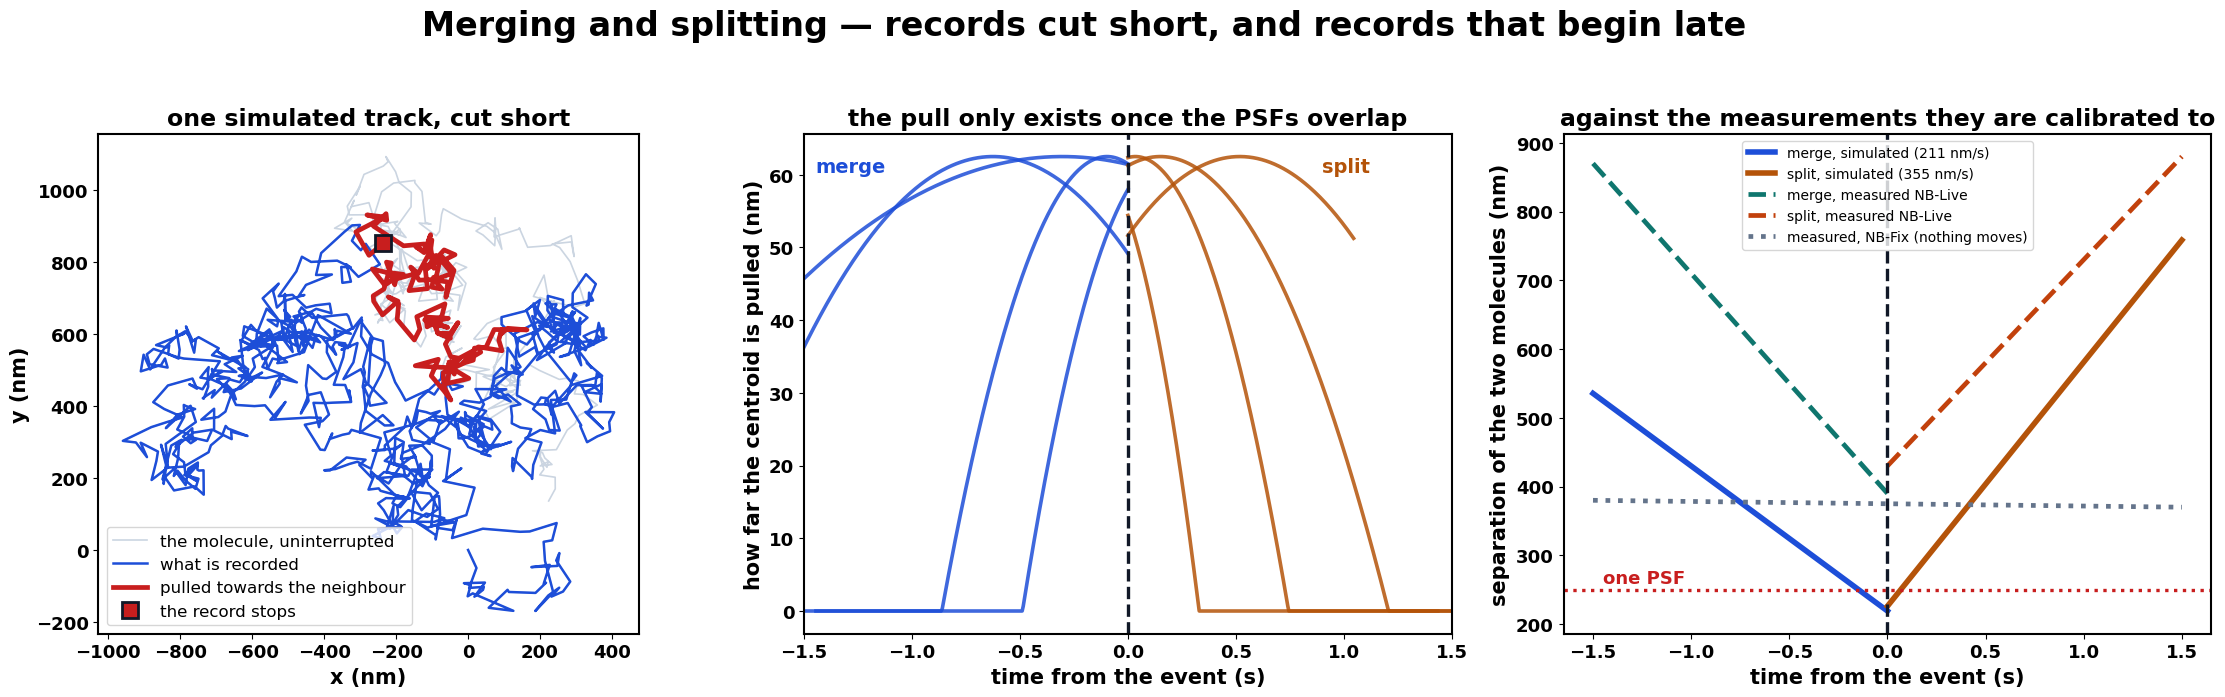

In [31]:
# --- what the merge artefact does to a track -------------------------------
_mrng = np.random.default_rng(SEED + 7171)
_n = 1200
_shown = []
for _ in range(4):
    fr_ = np.arange(_n)
    xy_ = np.cumsum(_mrng.normal(0, np.sqrt(2 * 0.118 * DT_S), (_n, 2)), 0)
    fr2, xy2, sep_end = add_merge(fr_, xy_.copy(), DT_S, _mrng)
    _shown.append((fr_, xy_, fr2, xy2, sep_end))

_split = []
for _ in range(4):
    fr_ = np.arange(_n)
    xy_ = np.cumsum(_mrng.normal(0, np.sqrt(2 * 0.118 * DT_S), (_n, 2)), 0)
    fs, xs, sep0 = add_split(fr_, xy_.copy(), DT_S, _mrng)
    _split.append((fr_, xy_, fs, xs, sep0))

fig, axes = plt.subplots(1, 3, figsize=(23, 6.8))

ax = axes[0]
f_, x_, f2, x2, se = _shown[0]
ax.plot(1000 * (x_[:, 0] - x_[0, 0]), 1000 * (x_[:, 1] - x_[0, 1]),
        lw=1.2, color="#cbd5e1", label="the molecule, uninterrupted")
ax.plot(1000 * (x2[:, 0] - x_[0, 0]), 1000 * (x2[:, 1] - x_[0, 1]),
        lw=1.8, color="#1d4ed8", label="what is recorded")
tail = slice(max(0, f2.size - 120), f2.size)
ax.plot(1000 * (x2[tail, 0] - x_[0, 0]), 1000 * (x2[tail, 1] - x_[0, 1]),
        lw=3.4, color="#c81e1e", label="pulled towards the neighbour")
ax.plot(1000 * (x2[-1, 0] - x_[0, 0]), 1000 * (x2[-1, 1] - x_[0, 1]), "s",
        ms=12, mfc="#c81e1e", mec="#111827", mew=2, label="the record stops")
ax.set_aspect("equal")
ax.set_xlabel("x (nm)"); ax.set_ylabel("y (nm)")
ax.set_title("one simulated track, cut short", fontweight="bold")
ax.legend(fontsize=12)

ax = axes[1]
for f_, x_, f2, x2, se in _shown:
    t_back = (f2[-1] - f2) * DT_S
    ax.plot(-t_back, 1000 * np.linalg.norm(x2 - x_[:f2.size], axis=1),
            lw=2.6, alpha=.85, color="#1d4ed8")
for f_, x_, fs, xs, s0 in _split:
    t_fwd = fs * DT_S
    ax.plot(t_fwd, 1000 * np.linalg.norm(xs - x_[-fs.size:], axis=1),
            lw=2.6, alpha=.85, color="#b45309")
ax.axvline(0, ls="--", lw=2.4, color="#111827")
ax.text(-1.45, ax.get_ylim()[1] * .92, "merge", color="#1d4ed8", fontsize=14,
        fontweight="bold")
ax.text(0.9, ax.get_ylim()[1] * .92, "split", color="#b45309", fontsize=14,
        fontweight="bold")
ax.set_xlim(-1.5, 1.5)
ax.set_xlabel("time from the event (s)")
ax.set_ylabel("how far the centroid is pulled (nm)")
ax.set_title("the pull only exists once the PSFs overlap", fontweight="bold")

ax = axes[2]
t = np.linspace(-1.5, 0, 200)
ax.plot(t, 1000 * (MERGE_SEP_UM + APPROACH_UM_S * (-t)), lw=4,
        color="#1d4ed8", label=f"merge, simulated "
                               f"({1000*APPROACH_UM_S:.0f} nm/s)")
t2 = np.linspace(0, 1.5, 200)
ax.plot(t2, 1000 * (SPLIT_SEP_UM + DEPART_UM_S * t2), lw=4, color="#b45309",
        label=f"split, simulated ({1000*DEPART_UM_S:.0f} nm/s)")
ax.plot([-1.5, 0], [870, 390], lw=3.4, ls="--", color="#0f766e",
        label="merge, measured NB-Live")
ax.plot([0, 1.5], [430, 880], lw=3.4, ls="--", color="#c2410c",
        label="split, measured NB-Live")
ax.plot([-1.5, 1.5], [380, 370], lw=3.4, ls=":", color="#64748b",
        label="measured, NB-Fix (nothing moves)")
ax.axhline(1000 * PSF_R, ls=":", lw=2.4, color="#c81e1e")
ax.text(-1.45, 1000 * PSF_R * 1.04, "one PSF", color="#c81e1e", fontsize=13,
        fontweight="bold")
ax.axvline(0, ls="--", lw=2.4, color="#111827")
ax.set_xlabel("time from the event (s)")
ax.set_ylabel("separation of the two molecules (nm)")
ax.set_title("against the measurements they are calibrated to",
             fontweight="bold")
ax.legend(fontsize=10)

bold_ticks(*axes)
fig.suptitle("Merging and splitting — records cut short, and records that "
             "begin late", fontsize=24, fontweight="bold", y=1.03)
fig.tight_layout()
fig.savefig(FIG_DIR / "M7c_merge_split.png", bbox_inches="tight")

print(f"at my density: {100*merge_rate(my_density):.2f}% of tracks merge "
      f"(measured 3.47%), {100*split_rate(my_density):.2f}% split "
      f"(measured 3.14%)")
print(f"   the neighbour closes at {1000*APPROACH_UM_S:.0f} nm/s and the "
      f"record stops {1000*MERGE_SEP_UM:.0f} nm apart")
print(f"   it leaves at {1000*DEPART_UM_S:.0f} nm/s and the record begins "
      f"{1000*SPLIT_SEP_UM:.0f} nm apart")
print(f"   at the library's densities, merge "
      f"{100*merge_rate(DENSITY_RANGE[0]):.2f}%-"
      f"{100*merge_rate(DENSITY_RANGE[1]):.2f}%, split "
      f"{100*split_rate(DENSITY_RANGE[0]):.2f}%-"
      f"{100*split_rate(DENSITY_RANGE[1]):.2f}%")
print()
print("A merged track is shorter than it would have been and its last stretch")
print("drifts one way; a split one begins late and its first stretch drifts")
print("the other. All four are in the saved labels (is_merge, merge_sep_um,")
print("is_split, split_sep_um), so notebook 02 can train the corruption")
print("output the plan asks for.")

### Assembling one complete track

The order follows what happens in a real experiment. Steps 5 and 6 are in that
order on purpose: a molecule keeps moving while it is dark, so the position
after a gap has to be where it drifted to. Generating only the visible frames
would make every gap a freeze, and the classifier would learn that blinking
means stopping.

In [32]:
def make_track(kind, dt, n_target, duty_target, sigma, exposure_min,
               drift_scale, density, rng, vary=True, patterns=None,
               n_frames=None, field_id=None, path_fn=None, cell="live"):
    """One simulated track: motion, blinking, drift, noise and artefacts.

     1. borrow a real molecule's blinking pattern (from the cell simulated)
     2. re-record it at this track's frame time
     3. cut a window of the length wanted, re-thin it to the duty wanted
     4. generate the motion over every frame spanned, dark ones included
     5. unresolved cluster, if any - rides on the motion, so before drift
     6. the stage's drift, shared by the whole movie
     7. keep the visible frames; localisation error, drifting along the
        track, with a few badly fitted detections
     8. split / merge with a neighbour, if any
     9. mis-link to a neighbour, if any: the rest is the neighbour's motion
    10. the linker's gap rule: a dark stretch over 19 frames breaks the record

    `cell` is "live" or "fixed": which merge/split behaviour applies, and
    which neighbour a mis-link picks up (in a fixed cell, an immobile one).
    `path_fn(span, dt, rng)` replaces step 4 when given.

    Returns a LIST of records - (frames, observed xy, true xy, labels) - one
    per fragment. The true path is the molecule actually recorded, without
    cluster offset, drift or noise; after a mis-link it is the neighbour's.
    """
    n_frames = n_frames or int(round(MOVIE_S / dt))
    patterns = patterns if patterns is not None else PAT_LIVE
    best = None
    for _ in range(40):
        obs = patterns[int(rng.integers(len(patterns)))]
        obs = reframe(obs, dt, exposure_min)
        if obs.size < MIN_SIM_DET:
            continue
        if best is None or obs.size > best.size:
            best = obs
        if obs.size >= (n_target if n_target is not None else 0):
            break
    if best is None:
        return None
    obs = window_of(best, n_target, rng)
    obs = thin_to_duty(obs, duty_target, rng)
    if obs.size < MIN_SIM_DET:
        return None

    span = int(obs[-1] - obs[0] + 1)
    f0 = int(rng.integers(0, max(1, n_frames - span)))
    fr = (obs - obs[0]).astype(np.int64)        # frames within the span

    # 4. the molecule
    p = draw_params(kind, span, dt, rng, vary=vary)
    true = PATH[kind](span, dt, p, rng) if path_fn is None \
        else np.asarray(path_fn(span, dt, rng), float)

    # 5. an unresolved cluster moves as one, so its offset rides on the path
    is_cluster = bool(rng.random() < cluster_rate(vary, rng))
    cl_sep, cl_wide = np.nan, False
    shown = true
    if is_cluster:
        off, cl_sep, cl_wide = cluster_offset(span, dt, rng)
        shown = true + off

    # 6. the stage
    drift, drift_total = drift_of(span, f0, rng, n_frames, drift_scale,
                                  field_id)
    fabs = fr.copy()                            # frame within span, kept
    clean = (shown + drift)[fr]                 # what a perfect camera sees
    truth = true[fr]

    # 7. localisation error. sigma drifts along the track by a ratio measured
    # in my fixed cells (first third against last third, so the full-track
    # slope is 1.5x that). The pool sigma already contains the badly fitted
    # detections, so the core is scaled to put the total back on `sigma`.
    lr = float(rng.choice(SIG_LOGRATIO))
    sig_t = sigma * np.exp(1.5 * lr * (fr / max(span - 1, 1) - 0.5))
    bad = FIT["bad_frac"]
    noise = rng.normal(0, 1, clean.shape) * sig_t[:, None]
    noise[rng.random(fr.size) < bad] *= OUTLIER_SCALE
    noise /= np.sqrt(1 - bad + bad * OUTLIER_SCALE ** 2)

    # 8. a neighbour separates and this record begins; later one arrives and
    # it stops. Both before mis-linking: a record not yet begun cannot swap.
    if cell == "fixed":
        p_split, p_merge = SPLIT_FIX, MERGE_FIX
        split_kw = dict(sep_start=SPLIT_SEP_FIX, v=0.0)
        merge_kw = dict(sep_end=MERGE_SEP_FIX, v=0.0)
    else:
        p_split, p_merge = split_rate(density), merge_rate(density)
        split_kw, merge_kw = {}, {}

    split_sep = np.nan
    if rng.random() < p_split:
        n0 = fr.size
        fr, clean, split_sep = add_split(fr, clean, dt, rng, **split_kw)
        k = n0 - fr.size
        fabs, truth, noise, sig_t = fabs[k:], truth[k:], noise[k:], sig_t[k:]
        if fr.size < MIN_SIM_DET:
            return None
    merge_sep = np.nan
    if rng.random() < p_merge:
        fr, clean, merge_sep = add_merge(fr, clean, dt, rng, **merge_kw)
        k = fr.size
        fabs, truth, noise, sig_t = fabs[:k], truth[:k], noise[:k], sig_t[:k]
        if fr.size < MIN_SIM_DET:
            return None

    # 9. mis-link: from `cut` on, the record follows a neighbour - its own
    # motion, starting within the jump limit of where this molecule was
    cut, mis_kind = np.nan, "-"
    if rng.random() < mislink_rate(density):
        c = mislink_cut(fr, rng)
        if c is not None:
            mis_kind = ("immobile" if cell == "fixed"
                        else str(rng.choice(CLASSES)))
            span_n = int(fabs[-1] - fabs[c] + 1)
            pn = draw_params(mis_kind, span_n, dt, rng, vary=vary)
            nb = PATH[mis_kind](span_n, dt, pn, rng)[fabs[c:] - fabs[c]]
            th = rng.uniform(0, 2 * np.pi)
            jump = R_LINK * np.sqrt(rng.random()) * np.array([np.cos(th),
                                                              np.sin(th)])
            start = truth[c - 1] + jump                # neighbour's position
            truth = truth.copy()
            truth[c:] = nb - nb[0] + start
            clean = clean.copy()
            clean[c:] = truth[c:] + drift[fabs[c:]]
            cut = c
    xy = clean + noise
    is_split = bool(np.isfinite(split_sep))     # what was DONE, not drawn
    is_merge = bool(np.isfinite(merge_sep))
    is_mislink = bool(np.isfinite(cut))

    # 10. the tracker's gap rule
    breaks = np.flatnonzero(np.diff(fr) - 1 > GAP_MAX) + 1
    pieces = np.split(np.arange(fr.size), breaks) if breaks.size else \
        [np.arange(fr.size)]
    pieces = [q for q in pieces if q.size >= MIN_SIM_DET]
    if not pieces:
        return None

    meta = {"kind": kind, "dt": dt, "f0": f0, "duty_wanted": duty_target,
            "n_det_wanted": n_target, "sigma_um": sigma,
            "sigma_end_over_start": float(np.exp(1.5 * lr)),
            "exposure_min": exposure_min, "drift_um": drift_total,
            "density": density, "field_id": field_id, "cell": cell,
            "is_cluster": is_cluster, "cluster_sep_um": cl_sep,
            "cluster_wide": bool(cl_wide),
            "is_mislink_molecule": is_mislink, "mislink_kind": mis_kind,
            "is_merge_molecule": is_merge, "merge_sep_um": merge_sep,
            "is_split_molecule": is_split, "split_sep_um": split_sep,
            "n_fragments": len(pieces), "is_fragment": len(pieces) > 1,
            "D": p["D"], "slow": bool(p.get("slow", False)),
            "alpha": p.get("alpha", np.nan), "R_um": p.get("R", np.nan),
            "p_escape": p.get("p_escape", np.nan),
            "n_escapes": p.get("n_escapes", np.nan),
            "directedness": p.get("directedness", np.nan),
            "population": p.get("population", "-")}
    out, last = [], len(pieces) - 1
    for j, q in enumerate(pieces):
        m = dict(meta)
        f_ = fr[q]
        m["fragment_index"] = j
        m["n_det"] = int(f_.size)
        m["span"] = int(f_[-1] - f_[0] + 1)
        m["duration_s"] = m["span"] * dt
        m["duty"] = f_.size / m["span"]
        g_ = np.diff(f_) - 1
        m["n_gaps"] = int((g_ > 0).sum())
        m["longest_gap"] = int(g_.max()) if g_.size else 0
        # each record carries only what happened inside it
        m["is_split"] = is_split and j == 0
        m["is_merge"] = is_merge and j == last
        inside = is_mislink and (q[0] < cut <= q[-1])
        m["is_mislink"] = bool(inside)
        m["mislink_at"] = int(cut - q[0]) if inside else np.nan
        m["is_corrupted"] = bool(is_cluster or inside or m["is_split"]
                                 or m["is_merge"])
        out.append((f_ - f_[0], xy[q], truth[q], m))
    return out

## 4. Building the library and the reference

**Every track belongs to a movie.** A movie fixes the frame time, the density,
the exposure threshold and the stage drift; its tracks differ in motion,
length, blinking and localisation error. That is what a recording is, and it
is why `movie_id` is saved with every track: two tracks from one movie are not
independent, so the classifier's train/test split has to be by movie, not by
track. Splitting randomly would put a near-twin of almost every test track
into training.

**The library spans conditions on purpose; the reference is my own experiment
exactly.** Judging the library against my data would be judging it for doing
its job. Only the reference is compared against my real tracks.

**Detections are not frames.** The bands are in detections, and with a duty
cycle of 0.2 a 50-detection track spans 250 frames. Both are recorded, along
with the band each track was asked for and the band it ended up in — thinning
and blinking move tracks between them.

**The library** spans every condition a different experiment might have, and is
stratified over the nine frame-rate × length cells so no combination is empty.
A model trained on it should survive data that is not mine.

**The reference** is my own conditions exactly, and is what I compare against
my real data. Judging the library against my data instead would be judging it
for doing its job.

In [33]:
def band_of(value, bands):
    """Return a zero-based band index using [lo, hi) intervals."""
    for i, (lo, hi) in enumerate(bands):
        last = (i == len(bands) - 1)
        if lo <= value < hi or (last and value == hi):
            return i
    return -1

# Each field_id identifies one simulated movie. Frame time, drift, density
# and exposure threshold are fixed within it; motion, blinking and
# localisation error differ track to track.
N_MOVIES_PER_CELL = 10
_NEXT_FIELD_ID = 0
_NEXT_TRACK_ID = 0      # global, so ids never collide between the sets

def build(n_each, vary, rng, len_pool=None, desc="", classes=None,
          whole=False, dt_fixed=None, donor="live", path_fn=None):
    """Build tracks grouped into movies that share their recording conditions.

    n_each  tracks per class (per band cell in the library): an int, or a
            dict {class: n}
    donor   "live" or "fixed": the cell being simulated. Every class borrows
            that cell's blinking, duty and localisation error, and the
            artefacts behave as in that cell.
    """
    global _NEXT_FIELD_ID, _NEXT_TRACK_ID
    classes = CLASSES if classes is None else list(classes)
    n_of = (dict(n_each) if isinstance(n_each, dict)
            else {k: int(n_each) for k in classes})
    pats = PAT_FIX if donor == "fixed" else PAT_LIVE
    duty_pool = (FIX if donor == "fixed" else LIVE).duty.to_numpy()
    sigma_pool = SIGMA if donor == "fixed" else SIGMA_LIVE
    col_gid, col_fr, col_x, col_y, col_tx, col_ty, labels = ([] for _ in
                                                              range(7))
    cells = ([(db, lb) for db in range(len(DT_BANDS))
              for lb in range(len(LEN_BANDS))] if vary else [(0, 2)])
    n_total_cell = sum(n_of[k] for k in classes)
    if vary:
        n_movies = N_MOVIES_PER_CELL
    else:   # as many tracks per field as my real data has
        n_movies = max(1, int(round(n_total_cell / TRACKS_PER_FIELD[donor])))
    total = n_total_cell * len(cells)

    with tqdm(total=total, desc=desc, leave=False) as bar:
        for db, lb in cells:
            for movie_i in range(n_movies):
                fid = _NEXT_FIELD_ID
                _NEXT_FIELD_ID += 1
                count = {k: n_of[k] // n_movies + (movie_i < n_of[k] % n_movies)
                         for k in classes}
                if vary:
                    dt = float(np.exp(rng.uniform(*np.log(DT_BANDS[db]))))
                    lo, hi = LEN_BANDS[lb]
                    hi = min(hi, int(round(MOVIE_S / dt)))
                    if hi < lo:
                        bar.update(sum(count.values()))
                        continue
                    expo_movie = float(rng.uniform(*EXPOSURE_RANGE))
                    density_movie = float(np.exp(rng.uniform(
                        *np.log(DENSITY_RANGE))))
                    drift_scale = float(rng.uniform(*DRIFT_SCALE))
                else:
                    dt = DT_S if dt_fixed is None else float(dt_fixed)
                    expo_movie = 0.5
                    density_movie = (FIX_DENSITY if donor == "fixed"
                                     else my_density)
                    drift_scale = 1.0
                n_frames = max(2, int(round(MOVIE_S / dt)))
                for kind in classes:
                    for _ in range(count[kind]):
                        bar.update(1)
                        if vary:
                            n_target = int(np.exp(rng.uniform(np.log(lo),
                                                              np.log(hi))))
                            if lb < len(LEN_BANDS) - 1:
                                n_target = min(n_target, hi - 1)
                            duty = float(rng.uniform(*DUTY_RANGE))
                            sigma_track = float(np.exp(rng.uniform(
                                *np.log(SIGMA_RANGE))))
                        elif whole:
                            # the donor is used as it is: its length, duty
                            # and gaps belong to one real molecule together
                            n_target, duty = None, 1.0
                            sigma_track = float(rng.choice(sigma_pool))
                        else:
                            n_target = int(rng.choice(len_pool))
                            duty = float(rng.choice(duty_pool))
                            sigma_track = float(rng.choice(sigma_pool))
                        out = make_track(
                            kind, dt, n_target, duty, sigma_track, expo_movie,
                            drift_scale, density_movie, rng, vary=vary,
                            patterns=pats, n_frames=n_frames, field_id=fid,
                            path_fn=path_fn, cell=donor)
                        if out is None:
                            continue
                        parent = _NEXT_TRACK_ID
                        _NEXT_TRACK_ID += 1
                        for fr, xy, tr, meta in out:
                            tid = _NEXT_TRACK_ID
                            _NEXT_TRACK_ID += 1
                            meta = dict(meta)
                            meta["track_gid"] = tid
                            meta["parent_gid"] = parent
                            meta["movie_id"] = fid
                            meta["dt_band"] = band_of(dt, DT_BANDS)
                            meta["len_band_asked"] = lb if vary else -1
                            meta["len_band"] = band_of(meta["n_det"],
                                                       LEN_BANDS)
                            meta["passes_200"] = meta["n_det"] >= MIN_TRACK_LEN
                            col_gid.append(np.full(fr.size, tid, np.int32))
                            col_fr.append(fr.astype(np.int32))
                            col_x.append(xy[:, 0].astype(np.float32))
                            col_y.append(xy[:, 1].astype(np.float32))
                            col_tx.append(tr[:, 0].astype(np.float32))
                            col_ty.append(tr[:, 1].astype(np.float32))
                            labels.append(meta)

    if not col_gid:
        raise RuntimeError(f"No tracks were generated for {desc!r}")
    out = pd.DataFrame({"track_gid": np.concatenate(col_gid),
                        "frame": np.concatenate(col_fr),
                        "x_um": np.concatenate(col_x),
                        "y_um": np.concatenate(col_y),
                        "x_true_um": np.concatenate(col_tx),
                        "y_true_um": np.concatenate(col_ty)})
    del col_gid, col_fr, col_x, col_y, col_tx, col_ty
    gc.collect()
    return out, pd.DataFrame(labels)


def srg_of_sim(T, L, report=True):
    """sRg, Rg, step and aspect for every simulated track, by the same
    formulas as srg_table on my real tracks."""
    tid = T.track_gid.to_numpy(); fr = T.frame.to_numpy()
    P = T[["x_um", "y_um"]].to_numpy(np.float64)
    cuts = np.flatnonzero(np.diff(tid)) + 1
    st = np.concatenate([[0], cuts]); en = np.concatenate([cuts, [len(tid)]])
    rows, dropped = [], 0
    for s_, e_ in zip(st, en):
        f, p_ = fr[s_:e_], P[s_:e_]
        step = np.linalg.norm(np.diff(p_, axis=0)[np.diff(f) == 1], axis=1)
        if step.size < 2:
            dropped += 1
            continue
        c = p_ - p_.mean(0)
        Rg = np.sqrt((c ** 2).sum(1).mean())
        lam = np.clip(np.linalg.eigvalsh(np.cov(c.T)), 1e-12, None)
        rows.append({"track_gid": tid[s_], "sRg": SQ * Rg / step.mean(),
                     "Rg_um": Rg, "step_um": step.mean(),
                     "aspect": float(np.sqrt(lam[1] / lam[0])),
                     "n_det_": e_ - s_, "n_steps": int(step.size)})
    if report and dropped:
        print(f"   dropped {dropped:,} of {L.track_gid.nunique():,} records "
              f"- fewer than two gap-free steps")
    return pd.DataFrame(rows).merge(L, on="track_gid")


def gate_stats(S):
    """The gate's numbers, on the records my real filter would keep."""
    S = S[S.n_det_ >= MIN_TRACK_LEN]
    return {"median sRg": float(S.sRg.median()),
            "75th": float(S.sRg.quantile(.75)),
            "95th sRg": float(S.sRg.quantile(.95)),
            "99th": float(S.sRg.quantile(.99)),
            "stretched %": 100 * float((S.aspect > ASPECT_CUT).mean()),
            "n": int(len(S))}

print("build() ready; the sets are built in section 5b, after the fit")

build() ready; the sets are built in section 5b, after the fit


## 5. Fitting what I cannot measure, then the gate

Seven things cannot be read off my data (plan, section 3): the share
fixation holds completely still, how much the rest still wiggles, how often a
localisation is badly fitted, and four properties of the unresolved
clusters: how many there are, how far apart the two emitters sit (as a scale
on my measured separations), how many are unusually wide, and how long the
centroid stays on one emitter. Instead of guessing them, I fit them
**together** so that simulated fixed cells reproduce my real fixed sRg
distribution: its median, its 95th percentile (my cutoff) and the share of
stretched tracks.

**"How much a fixed molecule still wiggles" needed two parameters, not one.**
Version 1 modelled it as slow free diffusion, and could not lift the median
without carrying the 95th percentile past its target. The reason is visible
in my data: even my lowest 10% of fixed tracks sit above sRg 1.0 (1.011) —
the whole distribution is lifted, not only its tail. Free diffusion grows with
track length, so it only stretches the tail. Badly fitted detections lift
the body, but my measured step tails (section 1) allow only ~1–2% of them.
What lifts the body is a **bounded wobble**: an anchored molecule jiggling on
its tether (label and linker flexibility), which inflates Rg without growing
over time. So the wiggle is fitted as both a bounded wobble (size and
correlation time) and slow drift (the plan's two residual-mobility
populations): nine parameters in all.

**How the fit is run.**
- Every candidate is built through the full pipeline, `build(donor="fixed")`,
  so the tracks fitted are exactly the tracks the gate measures.
- Every candidate uses the same random numbers: the same seed and the same
  simulated fields. Candidates then differ only in the nine parameters, not
  in their luck. Version 1 gave each row of its scan different draws, at 400
  tracks, where the 95th percentile alone moves by ~7%.
- Two rounds at 3,000 tracks each: a Latin hypercube over the whole space
  (300 candidates), then a simplex (Nelder–Mead) search from the best three.
- The loss counts each miss in units of a tolerance: 0.005 on the median,
  0.08 on the 95th percentile, 0.6 points on the stretched share. These are
  roughly each number's own seed-to-seed spread, so no target dominates
  because of its units.
- Only every comparison with real data uses records of 200+ detections,
  because that is what my upstream filter kept.

**What is not fitted, and so is the honest test:** the 75th and 99th
percentiles, the IQR, the whole-distribution shape (KS and
quantile-quantile), step size, Rg, duty and length.

In [34]:
TARGETS = {"median sRg": float(R_FIX.sRg.median()),
           "95th sRg": CUTOFF, "stretched %": STRETCHED}
TOL = {"median sRg": 0.005, "95th sRg": 0.08, "stretched %": 0.6}
FIT_SPACE = {                       # (low, high, log?)
    "still_share":  (0.0, 0.7, False),
    "resid_hi":     (1e-5, D_IMMOBILE[1], True),
    "bad_frac":     (0.0, 0.02, False),     # capped by my measured step tails
    "wig_hi":       (0.0, 0.06, False),
    "wig_tau":      (1.0, 1000.0, True),
    "cl_rate":      (0.0, 0.35, False),
    "cl_sep_scale": (0.4, 1.6, True),
    "cl_wide":      (0.0, 0.4, False),
    "cl_dwell":     (1.0, 400.0, True),
}
FIT_FIELD_ID0 = 50_000_000          # the same simulated fields for every try

def fixed_stats(params, n, seed=SEED + 55):
    """Gate statistics of simulated fixed cells built with these parameters."""
    global _NEXT_FIELD_ID
    keep_fit, keep_fid = dict(FIT), _NEXT_FIELD_ID
    FIT.update(params)
    _NEXT_FIELD_ID = FIT_FIELD_ID0
    try:
        T_, L_ = build(n, False, np.random.default_rng(seed),
                       classes=["immobile"], whole=True, donor="fixed",
                       desc="fit")
        out = gate_stats(srg_of_sim(T_, L_, report=False))
    finally:
        FIT.clear(); FIT.update(keep_fit)
        _NEXT_FIELD_ID = keep_fid
    return out

def loss_of(st):
    return float(sum(((st[k] - TARGETS[k]) / TOL[k]) ** 2 for k in TARGETS))

def lhs(n, rng):
    """Latin hypercube over FIT_SPACE."""
    cols = {}
    for k, (lo, hi, lg) in FIT_SPACE.items():
        u = (rng.permutation(n) + rng.random(n)) / n
        cols[k] = (np.exp(np.log(lo) + u * (np.log(hi) - np.log(lo))) if lg
                   else lo + u * (hi - lo))
    return [{k: float(cols[k][i]) for k in cols} for i in range(n)]

def nudge(par, rng, scale=0.15):
    """A small step around a candidate, within the space."""
    out = {}
    for k, (lo, hi, lg) in FIT_SPACE.items():
        if lg:
            v = np.exp(np.log(par[k]) + scale * (np.log(hi) - np.log(lo))
                       * rng.normal())
        else:
            v = par[k] + scale * (hi - lo) * rng.normal()
        out[k] = float(np.clip(v, lo, hi))
    return out

from scipy.optimize import minimize

def to_unit(par):
    """The fit space as a unit cube (log axes where the range spans decades)."""
    return np.array([(np.log(par[k]) - np.log(lo)) / (np.log(hi) - np.log(lo))
                     if lg else (par[k] - lo) / (hi - lo)
                     for k, (lo, hi, lg) in FIT_SPACE.items()])

def from_unit(u):
    u = np.clip(u, 0, 1)
    return {k: float(np.exp(np.log(lo) + ui * (np.log(hi) - np.log(lo))) if lg
                     else lo + ui * (hi - lo))
            for ui, (k, (lo, hi, lg)) in zip(u, FIT_SPACE.items())}

_frng = np.random.default_rng(SEED + 777)
N1, N_NM, NM_FEV = (16, 1, 20) if FAST else (300, 3, 150)
rows = []
for par in tqdm(lhs(N1, _frng), desc="fit round 1: Latin hypercube"):
    st = fixed_stats(par, N_FIT)
    rows.append({**par, **st, "loss": loss_of(st), "round": 1, "n_tracks": N_FIT})
R1 = pd.DataFrame(rows).sort_values("loss")

# round 2: a simplex search from each of the best few. The random numbers are
# the same for every evaluation, so the loss surface is deterministic and a
# local search can follow it.
rows = []
for start in range(N_NM):
    x0 = to_unit({k: float(R1.iloc[start][k]) for k in FIT_SPACE})
    def f(u):
        par = from_unit(u)
        st = fixed_stats(par, N_FIT)
        L_ = loss_of(st)
        rows.append({**par, **st, "loss": L_, "round": 2, "n_tracks": N_FIT,
                     "start": start})
        return L_ + 100 * float(np.sum(np.clip(-u, 0, None) + np.clip(u - 1, 0, None)))
    minimize(f, x0, method="Nelder-Mead",
             options={"maxfev": NM_FEV, "xatol": 2e-3, "fatol": 0.02,
                      "initial_simplex": np.vstack([x0] + [np.clip(x0 + 0.15 * np.eye(len(x0))[i]
                                                     * (1 if x0[i] < .85 else -1), 0, 1)
                                                     for i in range(len(x0))])})
    print(f"   simplex {start + 1}/{N_NM}: best loss "
          f"{min(r['loss'] for r in rows if r.get('start') == start):.2f}")
FIT_RUNS = pd.concat([R1, pd.DataFrame(rows)], ignore_index=True)
FIT_RUNS.to_csv(TAB_DIR / "fit_all_candidates.csv", index=False)
top = FIT_RUNS.sort_values("loss").iloc[0]
FIT.update({k: float(top[k]) for k in FIT_SPACE})

FIT_TABLE = pd.DataFrame([
    ("still_share", "share held completely still", f"{FIT['still_share']:.3f}"),
    ("resid_hi", "residual mobility: D from 1e-6 up to", f"{FIT['resid_hi']:.2e} um2/s"),
    ("bad_frac", "badly fitted detections (~3 sigma)", f"{100*FIT['bad_frac']:.2f}%"),
    ("wig_hi", "tether wobble: rms per axis, 0 up to",
     f"{1000*FIT['wig_hi']:.1f} nm"),
    ("wig_tau", "tether wobble: correlation time",
     f"{FIT['wig_tau']:.1f} frames = {1000*DT_S*FIT['wig_tau']:.0f} ms"),
    ("cl_rate", "unresolved clusters", f"{100*FIT['cl_rate']:.1f}% of tracks"),
    ("cl_sep_scale", "x my measured emitter separations",
     f"{FIT['cl_sep_scale']:.2f} (median {1000*FIT['cl_sep_scale']*np.median(CLUSTER_SEP):.0f} nm)"),
    ("cl_wide", "clusters 1.5-4x wider", f"{100*FIT['cl_wide']:.1f}%"),
    ("cl_dwell", "centroid's stay on one emitter",
     f"{FIT['cl_dwell']:.1f} frames = {1000*DT_S*FIT['cl_dwell']:.0f} ms"),
], columns=["parameter", "what it is", "fitted"])
FIT_TABLE.to_csv(TAB_DIR / "fitted_parameters.csv", index=False)
print(f"candidates tried: {len(FIT_RUNS)} ({N1} Latin hypercube + "
      f"{len(FIT_RUNS) - N1} simplex steps), {len(FIT_SPACE)} parameters, "
      f"{N_FIT:,} tracks each, the same random numbers every time")
print()
print(FIT_TABLE.to_string(index=False))
print()
print("the winner, against the three targets:")
for k in TARGETS:
    print(f"   {k:12s} real {TARGETS[k]:.4f}  simulated {top[k]:.4f}  "
          f"({(top[k]-TARGETS[k])/TOL[k]:+.1f} tolerances)")
print(f"   not fitted: 75th {top['75th']:.3f} (real "
      f"{R_FIX.sRg.quantile(.75):.3f}), 99th {top['99th']:.3f} (real "
      f"{R_FIX.sRg.quantile(.99):.3f})")
print(f"   brightness-based pair proxy, for comparison with the fitted cluster "
      f"rate: {100*PAIR_AT_MINE:.2f}% (it only sees clusters both of whose "
      f"emitters are on at once)")

fit round 1: Latin hypercube:   0%|          | 0/300 [00:00<?, ?it/s]

fit:   0%|          | 0/3000 [00:00<?, ?it/s]

fit:   0%|          | 0/3000 [00:00<?, ?it/s]

fit:   0%|          | 0/3000 [00:00<?, ?it/s]

fit:   0%|          | 0/3000 [00:00<?, ?it/s]

...

fit:   0%|          | 0/3000 [00:00<?, ?it/s]

fit:   0%|          | 0/3000 [00:00<?, ?it/s]

fit:   0%|          | 0/3000 [00:00<?, ?it/s]

fit:   0%|          | 0/3000 [00:00<?, ?it/s]

   simplex 3/3: best loss 0.02
candidates tried: 732 (300 Latin hypercube + 432 simplex steps), 9 parameters, 3,000 tracks each, the same random numbers every time

   parameter                           what it is                fitted
 still_share          share held completely still                 0.028
    resid_hi residual mobility: D from 1e-6 up to        7.29e-05 um2/s
    bad_frac   badly fitted detections (~3 sigma)                 1.62%
      wig_hi tether wobble: rms per axis, 0 up to               22.2 nm
     wig_tau      tether wobble: correlation time 118.1 frames = 591 ms
     cl_rate                  unresolved clusters       15.3% of tracks
cl_sep_scale    x my measured emitter separations  0.66 (median 210 nm)
     cl_wide                clusters 1.5-4x wider                 10.6%
    cl_dwell       centroid's stay on one emitter  85.2 frames = 426 ms

the winner, against the three targets:
   median sRg   real 1.1032  simulated 1.1032  (-0.0 tolerances)
   95th sR

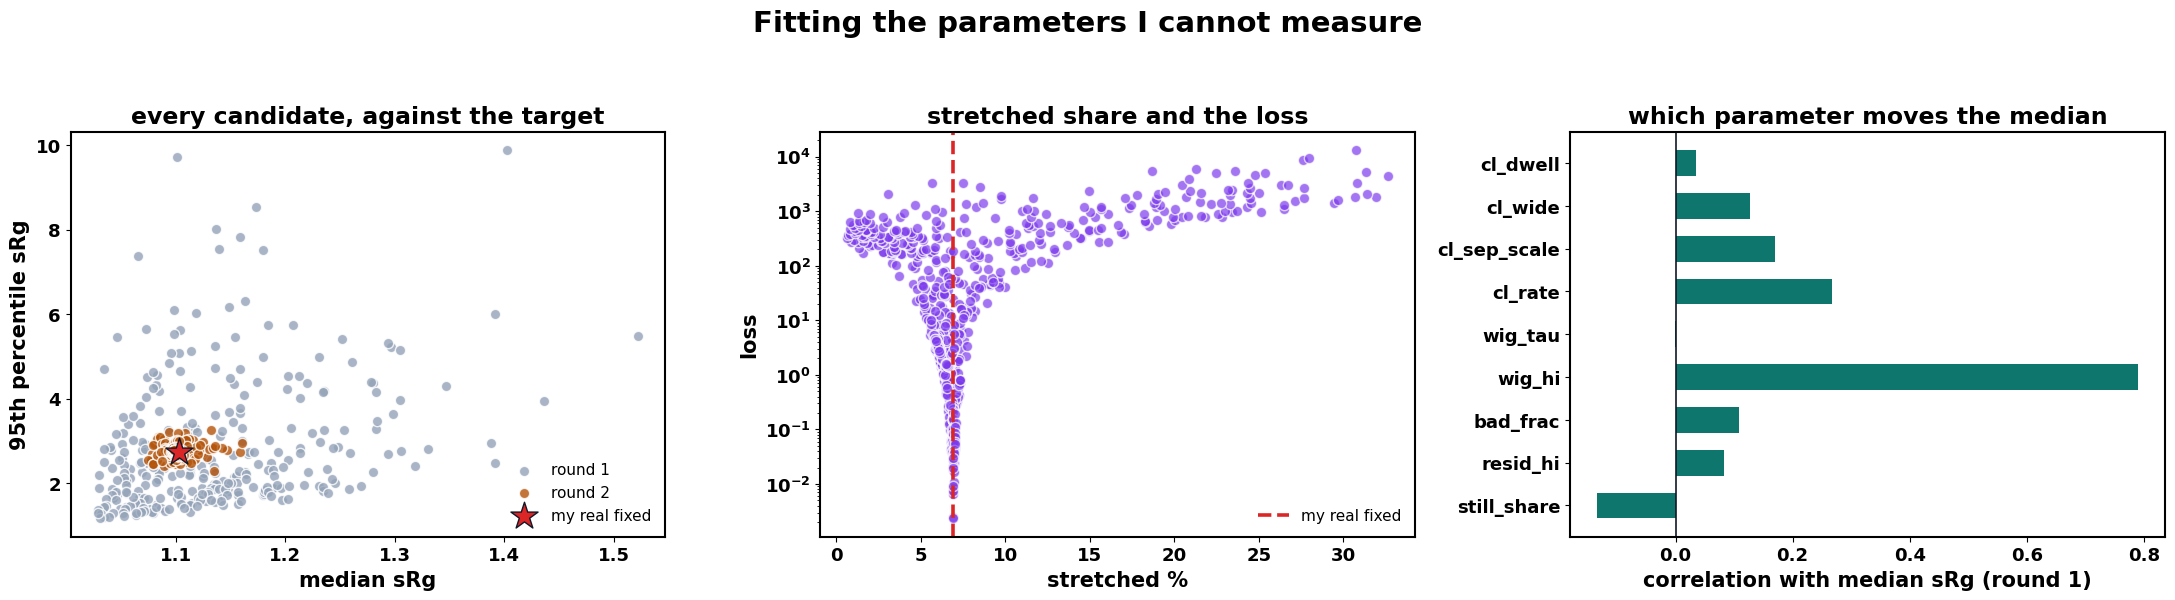

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(22, 5.8))
ax = axes[0]
for rd, c in [(1, "#94a3b8"), (2, "#b45309")]:
    d_ = FIT_RUNS[FIT_RUNS["round"] == rd]
    ax.scatter(d_["median sRg"], d_["95th sRg"], s=55, color=c, alpha=.8,
               edgecolors="white", label=f"round {rd}")
ax.scatter([TARGETS["median sRg"]], [TARGETS["95th sRg"]], marker="*", s=420,
           color="#dc2626", edgecolors="#111827", zorder=5, label="my real fixed")
ax.set_xlabel("median sRg"); ax.set_ylabel("95th percentile sRg")
ax.set_title("every candidate, against the target")
ax.legend(frameon=False, fontsize=11)
ax = axes[1]
ax.scatter(FIT_RUNS["stretched %"], FIT_RUNS["loss"], s=55, color="#7c3aed",
           alpha=.7, edgecolors="white")
ax.axvline(STRETCHED, color="#dc2626", ls="--", lw=2.6, label="my real fixed")
ax.set_yscale("log"); ax.set_xlabel("stretched %"); ax.set_ylabel("loss")
ax.set_title("stretched share and the loss")
ax.legend(frameon=False, fontsize=11)
ax = axes[2]
r1 = FIT_RUNS[FIT_RUNS["round"] == 1]
corr = {k: float(np.corrcoef(np.log(r1[k] + 1e-12) if FIT_SPACE[k][2] else r1[k],
                             r1["median sRg"])[0, 1]) for k in FIT_SPACE}
ax.barh(range(len(corr)), list(corr.values()), color="#0f766e", height=.6)
ax.set_yticks(range(len(corr))); ax.set_yticklabels(list(corr.keys()))
ax.axvline(0, color="#111827", lw=1.2)
ax.set_xlabel("correlation with median sRg (round 1)")
ax.set_title("which parameter moves the median")
bold_ticks(*axes)
fig.suptitle("Fitting the parameters I cannot measure", y=1.04)
fig.tight_layout()
fig.savefig(FIG_DIR / "S2_fit.png", bbox_inches="tight")

### 5b. Building the sets, with the fitted parameters

**Every track belongs to a movie.** A movie fixes the frame time, the
density, the exposure threshold and the stage drift; its tracks differ in
motion, length, blinking and localisation error. `movie_id` is saved with
every track, and the classifier's train/test split has to be by movie, not by
track: two tracks from one movie are not independent.

**The library** spans conditions on purpose, stratified over the nine
frame-rate × length cells, so a model trained on it survives other
experiments. **The references** are my own conditions exactly, and only they
are compared with my real data. Judging the library against my data would be
judging it for doing its job.

| set | what | size (plan) | donors |
|---|---|---|---|
| library | 5 classes, 5–100 ms, 10–5,000 detections | 5,000 immobile + 1,000 per mobile class | live |
| live reference | 5 classes at my NB-Live conditions | 1,000 per class | live |
| fixed reference | immobile, at my NB-Fix conditions — the gate | 5,000 | fixed |
| held-out obstacles | obstructed diffusion, never trained on | 500 | live |

**Detections are not frames.** With a duty cycle of 0.4 a 50-detection
track spans 125 frames. Both are recorded, with the band each track was
asked for and the band it ended up in.

**Fragmentation.** A record breaks where a dark stretch exceeds the
linker's 19 frames. My donors are already linked tracks (longest gap 18), so
whole donors at 5 ms never break: the references contain **no**
fragmentation, and that is a limit of the borrowed-blinking design, as the
plan says (section 10). The library fragments only where thinning makes a
long gap.

In [36]:
_rng = np.random.default_rng(SEED)
_per_cell = {k: int(np.ceil((N_LIB_IMM if k == "immobile" else N_LIB_MOB)
                            / (len(DT_BANDS) * len(LEN_BANDS)))) for k in CLASSES}
LIB, LIB_LAB = build(_per_cell, True, _rng, desc="library", donor="live")
REF_TR, REF_LAB = build({k: (N_REF_IMM_LIVE if k == "immobile" else N_REF_MOB)
                         for k in CLASSES}, False, _rng, whole=True,
                        desc="live reference", donor="live")
FIXSIM, FIXSIM_LAB = build(N_REF_FIX, False, _rng, classes=["immobile"],
                           whole=True, desc="fixed reference", donor="fixed")

def _obstacle_path(span, dt, rng):
    D = float(rng.choice(D_POOL))
    a = 1e-3 * float(rng.uniform(*LATTICE_NM))
    conc = float(rng.uniform(*OBSTACLE_CONC))
    return obstructed(span, D, dt, a, conc, rng)

HELD, HELD_LAB = build(N_HELDOUT, False, _rng, classes=["restricted"],
                       whole=True, desc="held-out obstacles", donor="live",
                       path_fn=_obstacle_path)
HELD_LAB["mechanism"] = "obstacles"
HELD_LAB["alpha"] = np.nan          # the label's alpha belongs to fGn, unused

for name, T, L in [("library", LIB, LIB_LAB), ("live reference", REF_TR, REF_LAB),
                   ("fixed reference", FIXSIM, FIXSIM_LAB),
                   ("held-out", HELD, HELD_LAB)]:
    print(f"{name:16s} {len(L):6,} records | {len(T):10,} detections | "
          f"dt {1000*L.dt.min():.0f}-{1000*L.dt.max():.0f} ms | "
          f"n_det {L.n_det.min()}-{L.n_det.max()} | "
          f"{L.movie_id.nunique()} movies")
print()
print("did the references come out like my real tracks?")
print(f"   live reference: median {REF_LAB.n_det.median():.0f} detections, duty "
      f"{REF_LAB.duty.median():.3f}  |  real NB-Live {LIVE.n_det.median():.0f}, "
      f"{LIVE.duty.median():.3f}")
print(f"   fixed reference: median {FIXSIM_LAB.n_det.median():.0f}, duty "
      f"{FIXSIM_LAB.duty.median():.3f}  |  real NB-Fix {FIX.n_det.median():.0f}, "
      f"{FIX.duty.median():.3f}")
_by = REF_LAB.groupby("kind").n_det.median()
print("   live reference, median detections by class (should be alike - the")
print("   class must not be readable from length): "
      + ", ".join(f"{k} {v:.0f}" for k, v in _by.items()))
print()
print("library: asked-for length band (rows) against the band it ended in:")
print(pd.crosstab(LIB_LAB.len_band_asked, LIB_LAB.len_band).to_string())
print()
print("library, records per frame-time x length cell:")
print(pd.crosstab(LIB_LAB.dt_band, LIB_LAB.len_band).to_string())
assert (LIB_LAB.f0 + LIB_LAB.span <= np.round(MOVIE_S / LIB_LAB.dt)).all(), \
    "a track runs past the end of its movie"
print("\nevery track fits inside its movie: OK")

def _mol(L):          # one row per molecule, for per-molecule rates
    return L.drop_duplicates("parent_gid")
ART = pd.DataFrame([{
    "set": name,
    "clusters %": 100 * _mol(L).is_cluster.mean(),
    "mis-linked %": 100 * _mol(L).is_mislink_molecule.mean(),
    "merged %": 100 * _mol(L).is_merge_molecule.mean(),
    "split %": 100 * _mol(L).is_split_molecule.mean(),
    "fragmented %": 100 * (L.groupby("parent_gid").size() > 1).mean(),
    "any corruption % (records)": 100 * L.is_corrupted.mean()}
    for name, L in [("library", LIB_LAB), ("live reference", REF_LAB),
                    ("fixed reference", FIXSIM_LAB)]]).round(2)
ART.to_csv(TAB_DIR / "artefact_rates.csv", index=False)
print()
print("artefacts, per molecule:")
print(ART.to_string(index=False))
print()
print("Tracks from one movie share the frame time, density and stage drift:")
print("split train/test by movie_id, never randomly by track.")

library:   0%|          | 0/9036 [00:00<?, ?it/s]

live reference:   0%|          | 0/5000 [00:00<?, ?it/s]

fixed reference:   0%|          | 0/5000 [00:00<?, ?it/s]

held-out obstacles:   0%|          | 0/500 [00:00<?, ?it/s]

library           9,111 records |  1,704,543 detections | dt 5-97 ms | n_det 10-3984 | 90 movies
live reference    5,000 records |  3,997,543 detections | dt 5-5 ms | n_det 21-5983 | 56 movies
fixed reference   5,000 records |  7,100,968 detections | dt 5-5 ms | n_det 20-6000 | 88 movies
held-out            500 records |    412,922 detections | dt 5-5 ms | n_det 27-5790 | 6 movies

did the references come out like my real tracks?
   live reference: median 438 detections, duty 0.757  |  real NB-Live 458, 0.759
   fixed reference: median 804, duty 0.710  |  real NB-Fix 807, 0.714
   live reference, median detections by class (should be alike - the
   class must not be readable from length): corralled 427, directed 435, immobile 457, normal 422, restricted 458

library: asked-for length band (rows) against the band it ended in:
len_band           0     1     2
len_band_asked                  
0               3014     0     0
1                884  2141     0
2                 87   948  203

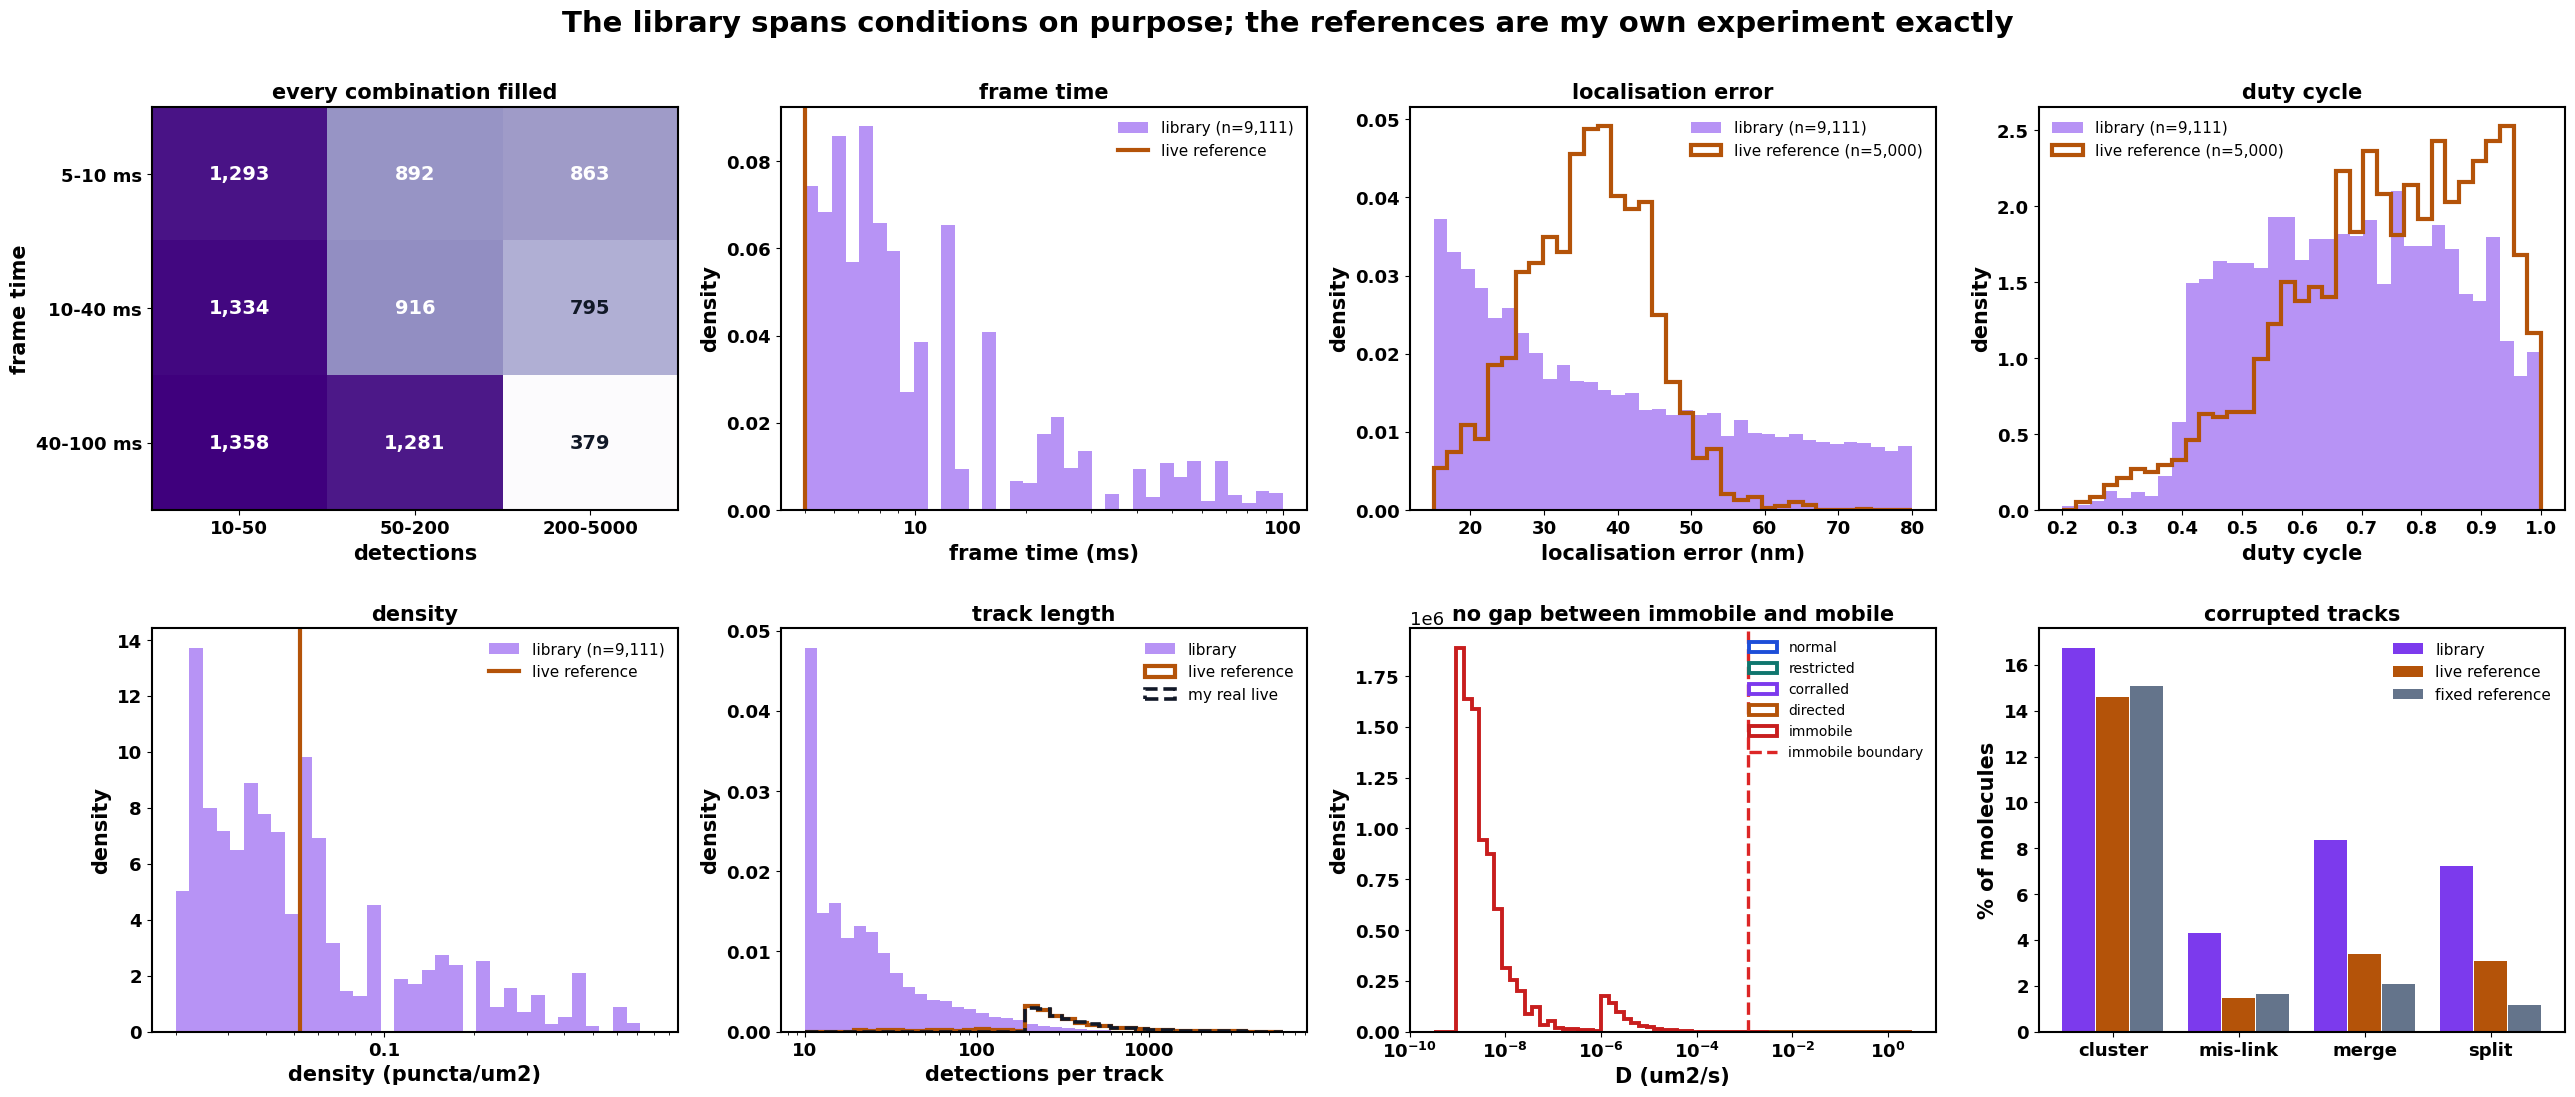

In [37]:
fig, axes = plt.subplots(2, 4, figsize=(26, 11))
C_LIB, C_REF = "#7c3aed", "#b45309"
ax = axes[0, 0]
ct = pd.crosstab(LIB_LAB.dt_band, LIB_LAB.len_band)
ax.imshow(ct.to_numpy(), cmap="Purples", aspect="auto")
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]):
        v = ct.iloc[i, j]
        ax.text(j, i, f"{v:,}", ha="center", va="center", fontsize=14,
                fontweight="bold",
                color="white" if v > ct.to_numpy().max() * .6 else "#111827")
ax.set_xticks(range(ct.shape[1]))
ax.set_xticklabels([f"{LEN_BANDS[j][0]}-{LEN_BANDS[j][1]}" for j in ct.columns])
ax.set_yticks(range(ct.shape[0]))
ax.set_yticklabels([f"{1000*DT_BANDS[i][0]:.0f}-{1000*DT_BANDS[i][1]:.0f} ms"
                    for i in ct.index])
ax.set_xlabel("detections"); ax.set_ylabel("frame time")
ax.set_title("every combination filled", fontsize=15)
for ax, col, lab, rr, logx in [
        (axes[0, 1], "dt", "frame time (ms)", DT_RANGE, True),
        (axes[0, 2], "sigma_um", "localisation error (nm)", SIGMA_RANGE, False),
        (axes[0, 3], "duty", "duty cycle", (0.2, 1.0), False),
        (axes[1, 0], "density", "density (puncta/um2)", DENSITY_RANGE, True)]:
    mult = 1000 if col in ("dt", "sigma_um") else 1
    lo, hi = rr[0] * mult, rr[1] * mult
    bins = (np.logspace(np.log10(lo), np.log10(hi), 36) if logx
            else np.linspace(lo, hi, 36))
    ax.hist(LIB_LAB[col] * mult, bins=bins, density=True, color=C_LIB,
            alpha=.55, label=f"library (n={len(LIB_LAB):,})")
    if REF_LAB[col].nunique() > 1:
        ax.hist(REF_LAB[col] * mult, bins=bins, density=True, histtype="step",
                lw=3, color=C_REF, label=f"live reference (n={len(REF_LAB):,})")
    else:
        ax.axvline(REF_LAB[col].iloc[0] * mult, color=C_REF, lw=3,
                   label="live reference")
    if logx:
        ax.set_xscale("log"); ax.xaxis.set_major_formatter(fmt)
        ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
    ax.set_xlabel(lab); ax.set_ylabel("density")
    ax.set_title(lab.split(" (")[0], fontsize=15)
    ax.legend(fontsize=11, frameon=False)
ax = axes[1, 1]
bins = np.logspace(np.log10(MIN_SIM_DET), np.log10(6000), 40)
ax.hist(LIB_LAB.n_det, bins=bins, density=True, color=C_LIB, alpha=.55,
        label="library")
ax.hist(REF_LAB.n_det, bins=bins, density=True, histtype="step", lw=3,
        color=C_REF, label="live reference")
ax.hist(LIVE.n_det, bins=bins, density=True, histtype="step", lw=2.6,
        color="#111827", ls="--", label="my real live")
ax.set_xscale("log"); ax.xaxis.set_major_formatter(fmt)
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.set_xlabel("detections per track"); ax.set_ylabel("density")
ax.set_title("track length", fontsize=15)
ax.legend(fontsize=11, frameon=False)
ax = axes[1, 2]
for k in CLASSES[:-1]:
    v = LIB_LAB.loc[LIB_LAB.kind == k, "D"]
    ax.hist(v, bins=np.logspace(-4, 0.5, 45), density=True, histtype="step",
            lw=2.8, color=COL[k], label=k)
v = LIB_LAB.loc[LIB_LAB.kind == "immobile", "D"]
ax.hist(v, bins=np.logspace(-9.5, -2.5, 45), density=True, histtype="step",
        lw=2.8, color=COL["immobile"], label="immobile")
ax.axvline(D_IMMOBILE[1], color="#dc2626", ls="--", lw=2.4,
           label="immobile boundary")
ax.set_xscale("log"); ax.set_xlabel("D (um2/s)"); ax.set_ylabel("density")
ax.set_title("no gap between immobile and mobile", fontsize=15)
ax.legend(fontsize=10, frameon=False)
ax = axes[1, 3]
x = np.arange(4)
cols_ = ["clusters %", "mis-linked %", "merged %", "split %"]
for off, (nm, c) in zip((-.27, 0, .27), [("library", C_LIB),
                                         ("live reference", C_REF),
                                         ("fixed reference", C_FIX)]):
    v = ART.set_index("set").loc[nm, cols_].to_numpy(float)
    ax.bar(x + off, v, .26, color=c, label=nm)
ax.set_xticks(x); ax.set_xticklabels(["cluster", "mis-link", "merge", "split"])
ax.set_ylabel("% of molecules"); ax.set_title("corrupted tracks", fontsize=15)
ax.legend(fontsize=11, frameon=False)
bold_ticks(*axes.ravel())
fig.suptitle("The library spans conditions on purpose; the references are my "
             "own experiment exactly", y=1.0)
fig.tight_layout()
fig.savefig(FIG_DIR / "S3_library_contents.png", bbox_inches="tight")

In [38]:
# Every saved dataset carries the settings it was made with.
SIM_SETTINGS = {
    "version": "v2 2026-10-24", "seed": SEED, "fast_mode": FAST,
    "pixel_um": PX_UM, "frame_time_s": DT_S, "movie_s": MOVIE_S,
    "min_sim_detections": MIN_SIM_DET, "real_filter_detections": MIN_TRACK_LEN,
    "sigma_um_fixed_median": float(np.median(SIGMA)),
    "sigma_um_live_median": float(np.median(SIGMA_LIVE)),
    "sigma_range_library": SIGMA_RANGE, "duty_range_library": DUTY_RANGE,
    "drift_um_measured_median": float(np.median(DRIFT)),
    "drift_scale_library": DRIFT_SCALE,
    "D_um2s_measured_median": float(np.median(D_POOL)), "D_scale_library": D_SCALE,
    "slow_share": SLOW_SHARE, "corral_um_measured_median": float(np.median(CORRAL)),
    "corral_scale_library": CORRAL_SCALE, "corral_escape": ESCAPE_P,
    "corral_impermeable": IMPERMEABLE,
    "density_live": my_density, "density_fixed": FIX_DENSITY,
    "density_range_library": DENSITY_RANGE, "alpha_range": ALPHA_RANGE,
    "directedness_range": DIRECTEDNESS, "immobile_boundary": D_IMMOBILE[1],
    "fitted": dict(FIT), "cluster_sep_um_median": float(np.median(CLUSTER_SEP)),
    "cluster_scale_library": CLUSTER_SCALE,
    "mislink": "notebook 04 density curve", "mislink_gap_weight": MISLINK_GAP_WEIGHT,
    "merge_split_live": (MERGE_AT_MINE, SPLIT_AT_MINE),
    "merge_split_fixed": (MERGE_FIX, SPLIT_FIX),
    "linker_jump_um": R_LINK, "linker_gap_frames": GAP_MAX,
    "exposure": EXPOSURE_RANGE, "dt_bands": DT_BANDS, "len_bands": LEN_BANDS,
    "donor_fixed": DONOR_FIX, "donor_live": DONOR_LIVE,
}
import json
(OUT / "sim_settings.json").write_text(json.dumps(SIM_SETTINGS, indent=2,
                                                  default=str))
for name, T, L in [("library", LIB, LIB_LAB), ("reference_live", REF_TR, REF_LAB),
                   ("reference_fixed", FIXSIM, FIXSIM_LAB),
                   ("heldout_obstacles", HELD, HELD_LAB)]:
    T.to_parquet(OUT / f"sim_{name}_tracks.parquet", index=False)
    L.assign(sim_seed=SEED).to_csv(OUT / f"sim_{name}_labels.csv", index=False)
    print(f"wrote sim_{name}_tracks.parquet + labels ({len(L):,} records)")
print("wrote sim_settings.json - every parameter, the fitted ones and the seed")

wrote sim_library_tracks.parquet + labels (9,111 records)
wrote sim_reference_live_tracks.parquet + labels (5,000 records)
wrote sim_reference_fixed_tracks.parquet + labels (5,000 records)
wrote sim_heldout_obstacles_tracks.parquet + labels (500 records)
wrote sim_settings.json - every parameter, the fitted ones and the seed


### 5c. The gate — do simulated fixed cells reproduce my real ones?

The plan's first check, and the only place I have real data where I know the
answer. Three numbers were fitted (median, 95th percentile, stretched
share); everything else in the table below was not, and the
quantile-quantile curve and the IQR are the honest part of the test.

**What it is and is not.** It checks that the instrument and tracker model
turns immobile molecules into tracks like mine. It says nothing about
whether the four moving classes are realistic — there is no ground truth for
those, which is why this project exists.

In [39]:
S_FIX = srg_of_sim(FIXSIM, FIXSIM_LAB)
S_REF = srg_of_sim(REF_TR, REF_LAB)
S_LIB = srg_of_sim(LIB, LIB_LAB)
S_HELD = srg_of_sim(HELD, HELD_LAB, report=False)
S_FIX_G = S_FIX[S_FIX.n_det_ >= MIN_TRACK_LEN]      # what my filter keeps
S_REF_G = S_REF[S_REF.n_det_ >= MIN_TRACK_LEN]

EXCL = pd.DataFrame([
    ("real fixed", N_REAL_FIX, len(R_FIX), f"{MIN_TRACK_LEN}+ detections"),
    ("real live", N_REAL_LIVE, len(R_LIVE), f"{MIN_TRACK_LEN}+ detections"),
    ("  ...mobile, for the D pool", len(R_LIVE), len(D_POOL), "above my cutoff, D > 0"),
    ("  ...with a corral", len(CORRAL_TAB), len(CORRAL), "MSD flattens above noise"),
    ("simulated fixed reference", len(FIXSIM_LAB), len(S_FIX_G),
     f"{MIN_TRACK_LEN}+ detections, as my real filter"),
    ("simulated live reference", len(REF_LAB), len(S_REF_G),
     f"{MIN_TRACK_LEN}+ detections, as my real filter"),
    ("simulated library", len(LIB_LAB), len(S_LIB), "2+ gap-free steps only"),
], columns=["set", "entered", "kept", "filter"])
EXCL["kept %"] = (100 * EXCL.kept / EXCL.entered).round(1)
EXCL.to_csv(TAB_DIR / "exclusions.csv", index=False)
print(EXCL.to_string(index=False))
print()

_rdut = FIX.set_index("track_gid").duty.reindex(R_FIX.track_gid).to_numpy()
gate = pd.DataFrame([
    ("median sRg", "fitted", R_FIX.sRg.median(), S_FIX_G.sRg.median()),
    ("95th percentile", "fitted", CUTOFF, S_FIX_G.sRg.quantile(.95)),
    ("stretched %", "fitted", STRETCHED, 100 * (S_FIX_G.aspect > ASPECT_CUT).mean()),
    ("25th percentile", "not fitted", R_FIX.sRg.quantile(.25), S_FIX_G.sRg.quantile(.25)),
    ("75th percentile", "not fitted", R_FIX.sRg.quantile(.75), S_FIX_G.sRg.quantile(.75)),
    ("99th percentile", "not fitted", R_FIX.sRg.quantile(.99), S_FIX_G.sRg.quantile(.99)),
    ("IQR", "not fitted", np.subtract(*R_FIX.sRg.quantile([.75, .25])),
     np.subtract(*S_FIX_G.sRg.quantile([.75, .25]))),
    ("median of mean step (nm)", "not fitted", 1000 * R_FIX.step_um.median(),
     1000 * S_FIX_G.step_um.median()),
    ("median Rg (nm)", "not fitted", 1000 * R_FIX.Rg_um.median(),
     1000 * S_FIX_G.Rg_um.median()),
    ("median detections", "not fitted", R_FIX.n_det.median(), S_FIX_G.n_det_.median()),
    ("median duty cycle", "not fitted", float(np.nanmedian(_rdut)), S_FIX_G.duty.median()),
], columns=["what", "", "my real fixed", "simulated"])
gate["diff %"] = 100 * (gate.simulated - gate["my real fixed"]) / gate["my real fixed"]
gate = gate.round(3)
gate.to_csv(TAB_DIR / "gate.csv", index=False)
print(gate.to_string(index=False))

_ff = FIXSIM[FIXSIM.track_gid.isin(S_FIX_G.track_gid)]
TAILS_SIM = step_tails(_ff.track_gid.to_numpy(), _ff.frame.to_numpy(),
                       _ff[["x_um", "y_um"]].to_numpy(np.float64))
TAILS = pd.DataFrame({"my real fixed": TAILS_FIX, "simulated": TAILS_SIM}).round(4)
TAILS.to_csv(TAB_DIR / "gate_step_tails.csv")
print("\nstep tails, x steps over the track's robust sigma (not fitted):")
print(TAILS.to_string())

ks = stats.ks_2samp(R_FIX.sRg.dropna(), S_FIX_G.sRg.dropna())
_q = np.linspace(0.02, 0.98, 49)
QQ = pd.DataFrame({"quantile": _q, "real": np.quantile(R_FIX.sRg, _q),
                   "simulated": np.quantile(S_FIX_G.sRg, _q)})
QQ["diff %"] = 100 * (QQ.simulated - QQ.real) / QQ.real
QQ.to_csv(TAB_DIR / "gate_qq.csv", index=False)
print(f"\nwhole distribution: KS D = {ks.statistic:.3f} (version 1: 0.157 on "
      f"this data)")
print(f"quantile-quantile: largest gap {QQ['diff %'].abs().max():.1f}% at "
      f"quantile {QQ.loc[QQ['diff %'].abs().idxmax(), 'quantile']:.2f}; "
      f"median gap {QQ['diff %'].abs().median():.1f}%")

   dropped 8 of 9,111 records - fewer than two gap-free steps
                        set  entered  kept                             filter  kept %
                 real fixed     3025  3025                    200+ detections   100.0
                  real live     2392  2392                    200+ detections   100.0
  ...mobile, for the D pool     2392  1833             above my cutoff, D > 0    76.6
           ...with a corral     2392    96           MSD flattens above noise     4.0
  simulated fixed reference     5000  4951 200+ detections, as my real filter    99.0
   simulated live reference     5000  4850 200+ detections, as my real filter    97.0
          simulated library     9111  9103             2+ gap-free steps only    99.9

                    what             my real fixed  simulated  diff %
              median sRg     fitted          1.103      1.101  -0.199
         95th percentile     fitted          2.731      2.713  -0.649
             stretched %     fitted    

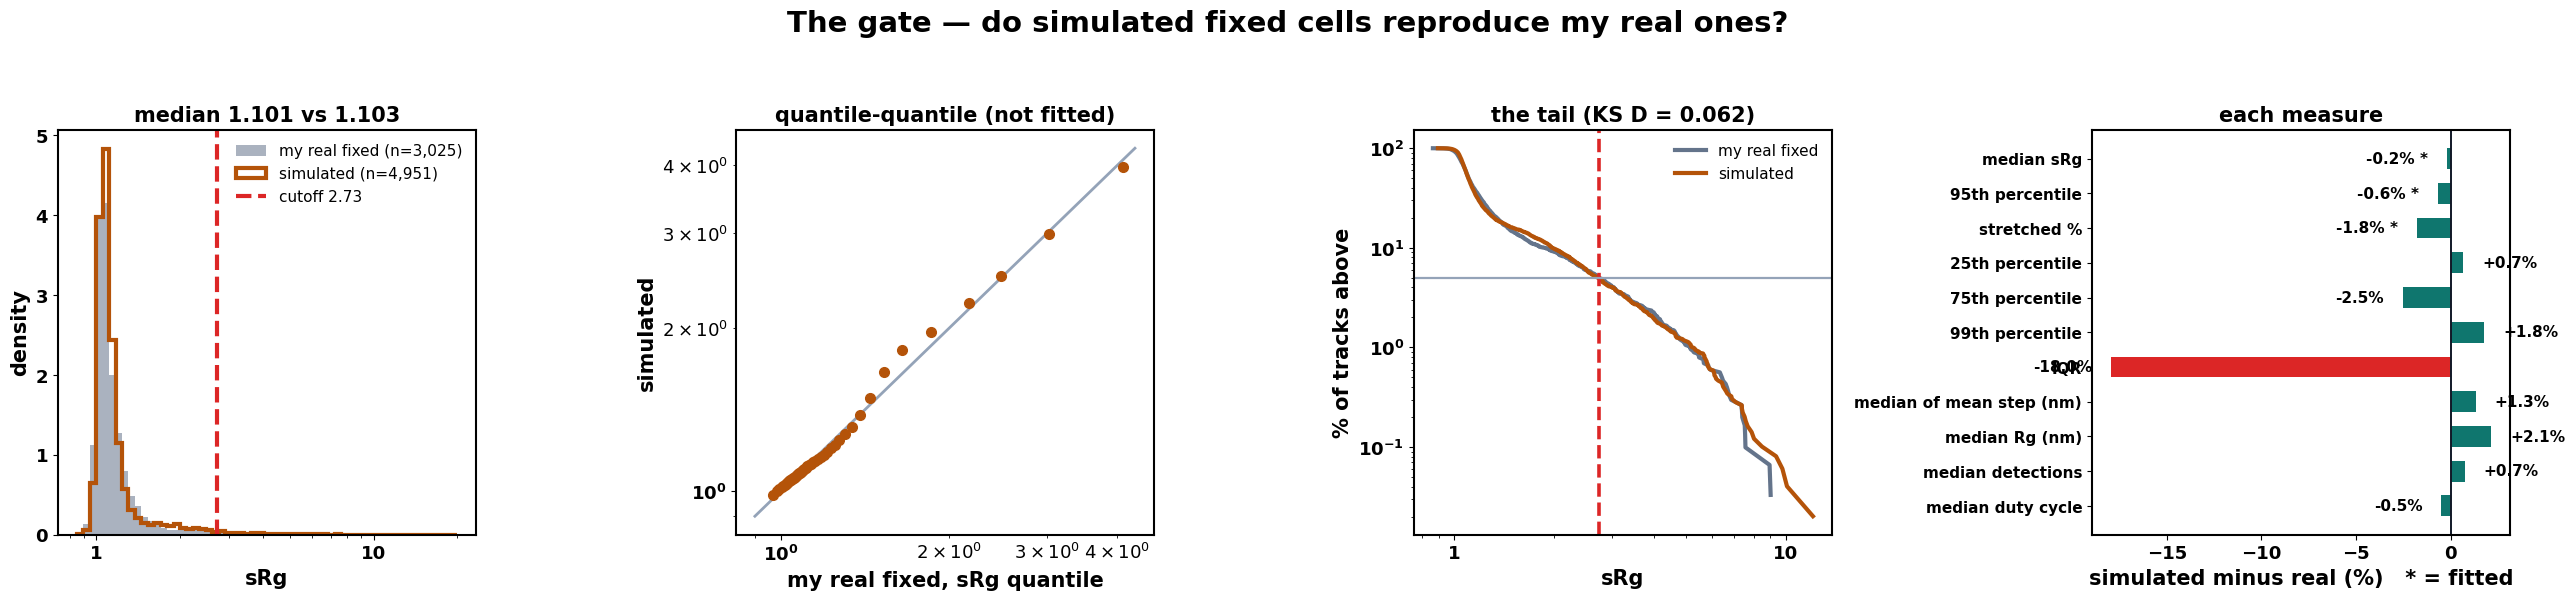

In [40]:
fig, axes = plt.subplots(1, 4, figsize=(26, 5.8))
ax = axes[0]
bins = np.logspace(np.log10(0.85), np.log10(20), 60)
ax.hist(R_FIX.sRg, bins=bins, density=True, color=C_FIX, alpha=.55,
        label=f"my real fixed (n={len(R_FIX):,})")
ax.hist(S_FIX_G.sRg, bins=bins, density=True, histtype="step", lw=3,
        color=C_SIM, label=f"simulated (n={len(S_FIX_G):,})")
ax.axvline(CUTOFF, color="#dc2626", ls="--", lw=3, label=f"cutoff {CUTOFF:.2f}")
ax.set_xscale("log"); ax.xaxis.set_major_formatter(fmt)
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.set_xlabel("sRg"); ax.set_ylabel("density")
ax.set_title(f"median {S_FIX_G.sRg.median():.3f} vs {R_FIX.sRg.median():.3f}",
             fontsize=15)
ax.legend(fontsize=11, frameon=False)
ax = axes[1]
lim_ = (0.9, max(QQ.real.max(), QQ.simulated.max()) * 1.05)
ax.plot(lim_, lim_, color="#94a3b8", lw=2)
ax.plot(QQ.real, QQ.simulated, "o", ms=7, color=C_SIM)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("my real fixed, sRg quantile"); ax.set_ylabel("simulated")
ax.set_title("quantile-quantile (not fitted)", fontsize=15)
ax = axes[2]
for lab, v, c in [("my real fixed", R_FIX.sRg, C_FIX),
                  ("simulated", S_FIX_G.sRg, C_SIM)]:
    s_ = np.sort(v.dropna())
    ax.plot(s_, 100 * (1 - np.arange(s_.size) / s_.size), lw=3, color=c, label=lab)
ax.axvline(CUTOFF, color="#dc2626", ls="--", lw=2.6)
ax.axhline(5, color="#94a3b8", lw=1.6)
ax.set_xscale("log"); ax.set_yscale("log")
ax.xaxis.set_major_formatter(fmt)
ax.xaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.set_xlabel("sRg"); ax.set_ylabel("% of tracks above")
ax.set_title(f"the tail (KS D = {ks.statistic:.3f})", fontsize=15)
ax.legend(fontsize=11, frameon=False)
ax = axes[3]
g = gate.iloc[::-1]
cols = ["#dc2626" if abs(d) > 10 else "#b45309" if abs(d) > 5 else "#0f766e"
        for d in g["diff %"]]
ax.barh(np.arange(len(g)), g["diff %"], color=cols, height=.6)
ax.axvline(0, color="#111827", lw=1.4)
for i, (d, w) in enumerate(zip(g["diff %"], g[""])):
    ax.text(d + (1 if d >= 0 else -1), i, f"{d:+.1f}%" + (" *" if w == "fitted" else ""),
            va="center", ha="left" if d >= 0 else "right", fontsize=11,
            fontweight="bold")
ax.set_yticks(np.arange(len(g))); ax.set_yticklabels(g["what"], fontsize=11)
ax.set_xlabel("simulated minus real (%)   * = fitted")
ax.set_title("each measure", fontsize=15)
bold_ticks(*axes)
fig.suptitle("The gate — do simulated fixed cells reproduce my real ones?", y=1.04)
fig.tight_layout()
fig.savefig(FIG_DIR / "S4_gate.png", bbox_inches="tight")

### 5d. Six seeds — how much of this is the random seed?

The plan's second check. The same model, built six times with six seeds, at
the gate's own size (version 1 measured the spread at 600 tracks for a
3,000-track gate, which overstated it). If my real value sits inside the
spread, the difference is sampling and I quote the spread; if it sits
outside, the model is wrong and the answer is to refit, not to nudge.

Two limits (plan): this tests reproducibility, not correctness; and it
ignores the sampling error of my own 3,025 fixed tracks.

In [41]:
N_SEEDS = 6

def one_seed(seed):
    rng = np.random.default_rng(seed)
    fT, fL = build(N_REF_FIX, False, rng, classes=["immobile"], whole=True,
                   donor="fixed", desc=f"seed {seed} fixed")
    rT, rL = build({k: (N_REF_IMM_LIVE if k == "immobile" else N_REF_MOB)
                    for k in CLASSES}, False, rng, whole=True, donor="live",
                   desc=f"seed {seed} live")
    st = gate_stats(srg_of_sim(fT, fL, report=False))
    R_ = srg_of_sim(rT, rL, report=False)
    R_ = R_[R_.n_det_ >= MIN_TRACK_LEN]
    mo = R_[R_.kind != "immobile"]
    out = {"seed": seed, "median sRg": st["median sRg"], "95th sRg": st["95th sRg"],
           "stretched %": st["stretched %"],
           "all mobile called immobile %": 100 * float((mo.sRg <= CUTOFF).mean())}
    for k in CLASSES[:-1]:
        out[k] = 100 * float((R_[R_.kind == k].sRg <= CUTOFF).mean())
    del fT, fL, rT, rL
    gc.collect()
    return out

SEEDS = pd.DataFrame([one_seed(SEED + 100 * (i + 1)) for i in
                      tqdm(range(N_SEEDS), desc="six seeds")])
SEEDS.to_csv(TAB_DIR / "seed_spread.csv", index=False)
cols_ = [c for c in SEEDS.columns if c != "seed"]
summ = pd.DataFrame({"mean": SEEDS[cols_].mean(), "sd": SEEDS[cols_].std(),
                     "min": SEEDS[cols_].min(), "max": SEEDS[cols_].max()}).round(3)
print(SEEDS.round(3).to_string(index=False))
print("\nacross six seeds:")
print(summ.to_string())
print("\nTHE GATE, in units of the simulation's own spread:")
GATE_SD = []
for lab, real in [("median sRg", TARGETS["median sRg"]), ("95th sRg", CUTOFF),
                  ("stretched %", STRETCHED)]:
    m_, s_ = summ.loc[lab, "mean"], summ.loc[lab, "sd"]
    z = abs(m_ - real) / s_ if s_ > 0 else np.nan
    GATE_SD.append({"measure": lab, "real": real, "simulated": m_, "sd": s_,
                    "sd out": round(z, 2),
                    "verdict": "sampling" if z <= 2 else ("look" if z <= 4 else "refit")})
    print(f"   {lab:12s} real {real:7.3f}  simulated {m_:7.3f}  sd {s_:6.3f}"
          f"  -> {z:.1f} sd out")
GATE_SD = pd.DataFrame(GATE_SD)
GATE_SD.to_csv(TAB_DIR / "gate_in_seed_sd.csv", index=False)
print("(version 1 on the same data: median 7.5 sd out)")
GATE_PASSED = bool((GATE_SD["sd out"] <= 2).all())
print(f"\nGATE {'PASSED' if GATE_PASSED else 'NOT PASSED'}: "
      + ("every fitted number is within 2 sd of my real value."
         if GATE_PASSED else "see the verdicts above; the plan says refit "
         "before training on this library."))

six seeds:   0%|          | 0/6 [00:00<?, ?it/s]

seed 100 fixed:   0%|          | 0/5000 [00:00<?, ?it/s]

seed 100 live:   0%|          | 0/5000 [00:00<?, ?it/s]

seed 200 fixed:   0%|          | 0/5000 [00:00<?, ?it/s]

seed 200 live:   0%|          | 0/5000 [00:00<?, ?it/s]

...

seed 500 fixed:   0%|          | 0/5000 [00:00<?, ?it/s]

seed 500 live:   0%|          | 0/5000 [00:00<?, ?it/s]

seed 600 fixed:   0%|          | 0/5000 [00:00<?, ?it/s]

seed 600 live:   0%|          | 0/5000 [00:00<?, ?it/s]

 seed  median sRg  95th sRg  stretched %  all mobile called immobile %  normal  restricted  corralled  directed
  100       1.106     2.750        6.996                        31.770  10.309      55.602     55.453     5.949
  200       1.109     2.672        6.695                        30.170   9.035      55.897     51.863     3.738
  300       1.100     2.716        6.448                        30.985  10.031      55.266     54.713     4.401
  400       1.106     2.824        7.052                        31.218  10.359      54.959     53.553     5.925
  500       1.102     2.617        6.319                        30.442   9.578      55.694     51.550     5.062
  600       1.103     2.776        7.326                        31.944  11.831      55.967     54.948     5.133

across six seeds:
                                mean     sd     min     max
median sRg                     1.104  0.003   1.100   1.109
95th sRg                       2.726  0.074   2.617   2.824
stretched %      

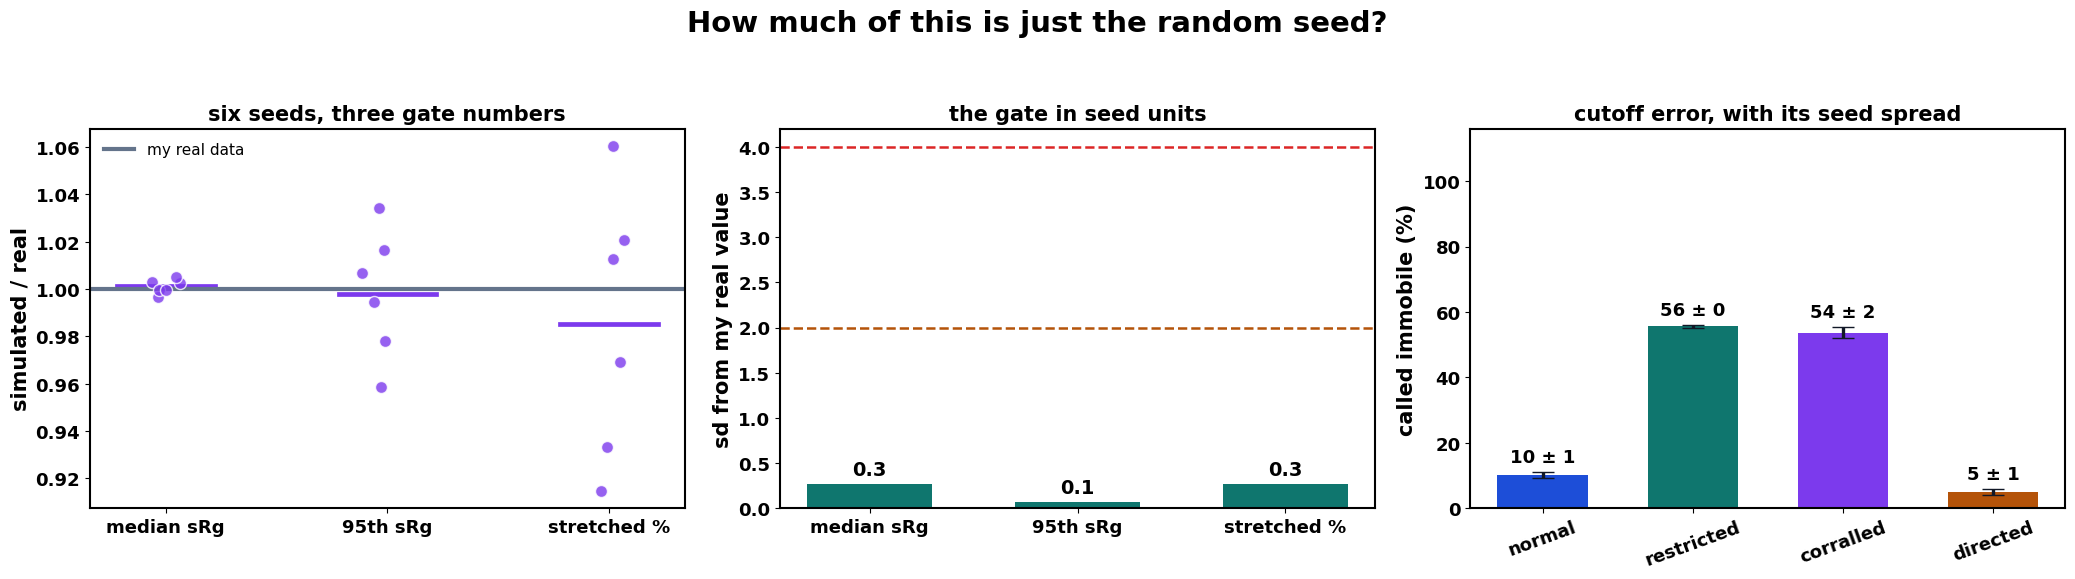

In [42]:
fig, axes = plt.subplots(1, 3, figsize=(21, 5.6))
items = [("median sRg", TARGETS["median sRg"]), ("95th sRg", CUTOFF),
         ("stretched %", STRETCHED)]
ax = axes[0]
for i, (lab, real) in enumerate(items):
    v = SEEDS[lab].to_numpy()
    ax.scatter(np.full(len(v), i) + rng_global.normal(0, .05, len(v)), v / real,
               s=75, color="#7c3aed", alpha=.8, edgecolors="white", zorder=3)
    ax.plot([i - .22, i + .22], [v.mean() / real] * 2, lw=3.4, color="#7c3aed")
ax.axhline(1.0, color=C_FIX, lw=3, label="my real data")
ax.set_xticks(range(3)); ax.set_xticklabels([l for l, _ in items])
ax.set_ylabel("simulated / real"); ax.set_title("six seeds, three gate numbers",
                                                fontsize=15)
ax.legend(fontsize=11, frameon=False)
ax = axes[1]
sds = GATE_SD["sd out"].to_numpy()
ax.bar(np.arange(3), sds, width=.6,
       color=["#0f766e" if d <= 2 else "#b45309" if d <= 4 else "#dc2626" for d in sds])
for i, d in enumerate(sds):
    ax.text(i, d + .1, f"{d:.1f}", ha="center", fontsize=14, fontweight="bold")
for y_, c_ in [(2, "#b45309"), (4, "#dc2626")]:
    ax.axhline(y_, color=c_, ls="--", lw=1.8)
ax.set_xticks(range(3)); ax.set_xticklabels([l for l, _ in items])
ax.set_ylabel("sd from my real value"); ax.set_title("the gate in seed units",
                                                     fontsize=15)
ax = axes[2]
ks_ = CLASSES[:-1]
m_ = [SEEDS[k].mean() for k in ks_]; s_ = [SEEDS[k].std() for k in ks_]
ax.bar(np.arange(len(ks_)), m_, yerr=s_, capsize=8, width=.6,
       color=[COL[k] for k in ks_], error_kw=dict(lw=2.4, ecolor="#111827"))
for i, (mm, ss) in enumerate(zip(m_, s_)):
    ax.text(i, mm + ss + 3, f"{mm:.0f} ± {ss:.0f}", ha="center", fontsize=13,
            fontweight="bold")
ax.set_xticks(np.arange(len(ks_))); ax.set_xticklabels(ks_, rotation=20)
ax.set_ylabel("called immobile (%)"); ax.set_ylim(0, 116)
ax.set_title("cutoff error, with its seed spread", fontsize=15)
bold_ticks(*axes)
fig.suptitle("How much of this is just the random seed?", y=1.04)
fig.tight_layout()
fig.savefig(FIG_DIR / "S6_seed_spread.png", bbox_inches="tight")

## 6. What my cutoff gets wrong

The question the simulation exists to answer (plan, section 9): **every
mobile track is genuinely moving, so how many does my sRg cutoff call
immobile, and which classes does it lose?**

Two versions. At my own conditions, from the live reference — the error in
the experiment I have run, on the tracks my 200-detection filter keeps. And
per frame-time × length cell, from the library — a lookup table, because
2.73 is not the right cutoff at 100 ms with 50 detections.

In [43]:
mine = S_REF_G.assign(called_immobile=S_REF_G.sRg <= CUTOFF)
mob = mine[mine.kind != "immobile"]

def rate_ci(flags, n_boot=400, seed=SEED):
    v = np.asarray(flags, bool)
    if v.size < 20:
        return np.nan, np.nan
    r = np.random.default_rng(seed)
    bs = [100 * r.choice(v, v.size, replace=True).mean() for _ in range(n_boot)]
    return float(np.percentile(bs, 2.5)), float(np.percentile(bs, 97.5))

rows_mine = []
for k in CLASSES:
    sel = mine[mine.kind == k]
    lo_, hi_ = rate_ci(sel.called_immobile.to_numpy())
    rows_mine.append({"class": k, "called immobile %":
                      round(100 * sel.called_immobile.mean(), 1),
                      "95% CI": f"{lo_:.1f}-{hi_:.1f}", "ci_lo": lo_, "ci_hi": hi_,
                      "n": len(sel)})
for lab, sel in [("all mobile", mob), ("mobile, slow-boundary draws", mob[mob.slow]),
                 ("mobile, from my D pool", mob[~mob.slow])]:
    lo_, hi_ = rate_ci(sel.called_immobile.to_numpy())
    rows_mine.append({"class": lab, "called immobile %":
                      round(100 * sel.called_immobile.mean(), 1),
                      "95% CI": f"{lo_:.1f}-{hi_:.1f}", "ci_lo": lo_, "ci_hi": hi_,
                      "n": len(sel)})
ERR_MINE = pd.DataFrame(rows_mine).set_index("class")
ERR_MINE.to_csv(TAB_DIR / "cutoff_error_my_conditions.csv")
print(f"AT MY OWN CONDITIONS, cutoff = {CUTOFF:.3f}, records of "
      f"{MIN_TRACK_LEN}+ detections")
print(ERR_MINE.drop(columns=["ci_lo", "ci_hi"]).to_string())
print("\nThe four mobile classes move by construction, so their rows are errors.")
print("The immobile row is the share my cutoff keeps (it should be ~95%).")
print("(version 1 on this data: all mobile 37.8%)")

def cut_ci(v, n_boot=200, seed=SEED):
    v = np.asarray(v)[np.isfinite(v)]
    if v.size < 40:
        return np.nan, np.nan, np.nan
    r = np.random.default_rng(seed)
    bs = [np.quantile(r.choice(v, v.size, replace=True), .95) for _ in range(n_boot)]
    return (float(np.quantile(v, .95)), float(np.percentile(bs, 2.5)),
            float(np.percentile(bs, 97.5)))

rows = []
for db, (dlo, dhi) in enumerate(DT_BANDS):
    for lb, (nlo, nhi) in enumerate(LEN_BANDS):
        cell = S_LIB[(S_LIB.dt_band == db) & (S_LIB.len_band == lb)]
        imm, mo = cell[cell.kind == "immobile"], cell[cell.kind != "immobile"]
        if len(imm) < 40 or len(mo) < 40:
            continue
        cut, lo_, hi_ = cut_ci(imm.sRg.to_numpy())
        r = {"frame time": f"{1000*dlo:.0f}-{1000*dhi:.0f} ms",
             "detections": f"{nlo}-{nhi}" if lb < len(LEN_BANDS) - 1 else f"{nlo}+",
             "immobile": len(imm), "mobile": len(mo), "cutoff": round(cut, 3),
             "95% CI": f"{lo_:.2f}-{hi_:.2f}",
             "all mobile": round(100 * float((mo.sRg <= cut).mean()), 1)}
        for k in CLASSES[:-1]:
            sel = mo[mo.kind == k]
            r[k] = (round(100 * float((sel.sRg <= cut).mean()), 1)
                    if len(sel) >= 20 else np.nan)
        rows.append(r)
CELLS = pd.DataFrame(rows)
CELLS.to_csv(TAB_DIR / "cutoff_error_per_condition.csv", index=False)
print()
print("THE LOOKUP TABLE - each cell's own cutoff (95th pct of its immobile")
print("tracks), and the share of mobile tracks it calls immobile")
print(CELLS.to_string(index=False))

AT MY OWN CONDITIONS, cutoff = 2.731, records of 200+ detections
                             called immobile %     95% CI     n
class                                                          
normal                                     9.3   7.3-11.2   972
restricted                                57.1  54.1-60.1   970
corralled                                 55.2  51.9-57.9   969
directed                                   4.8    3.5-6.4   972
immobile                                  96.3  95.1-97.4   967
all mobile                                31.6  30.0-32.9  3883
mobile, slow-boundary draws               54.8  51.3-58.1   757
mobile, from my D pool                    25.9  24.5-27.6  3126

The four mobile classes move by construction, so their rows are errors.
The immobile row is the share my cutoff keeps (it should be ~95%).
(version 1 on this data: all mobile 37.8%)

THE LOOKUP TABLE - each cell's own cutoff (95th pct of its immobile
tracks), and the share of mobile tracks it 

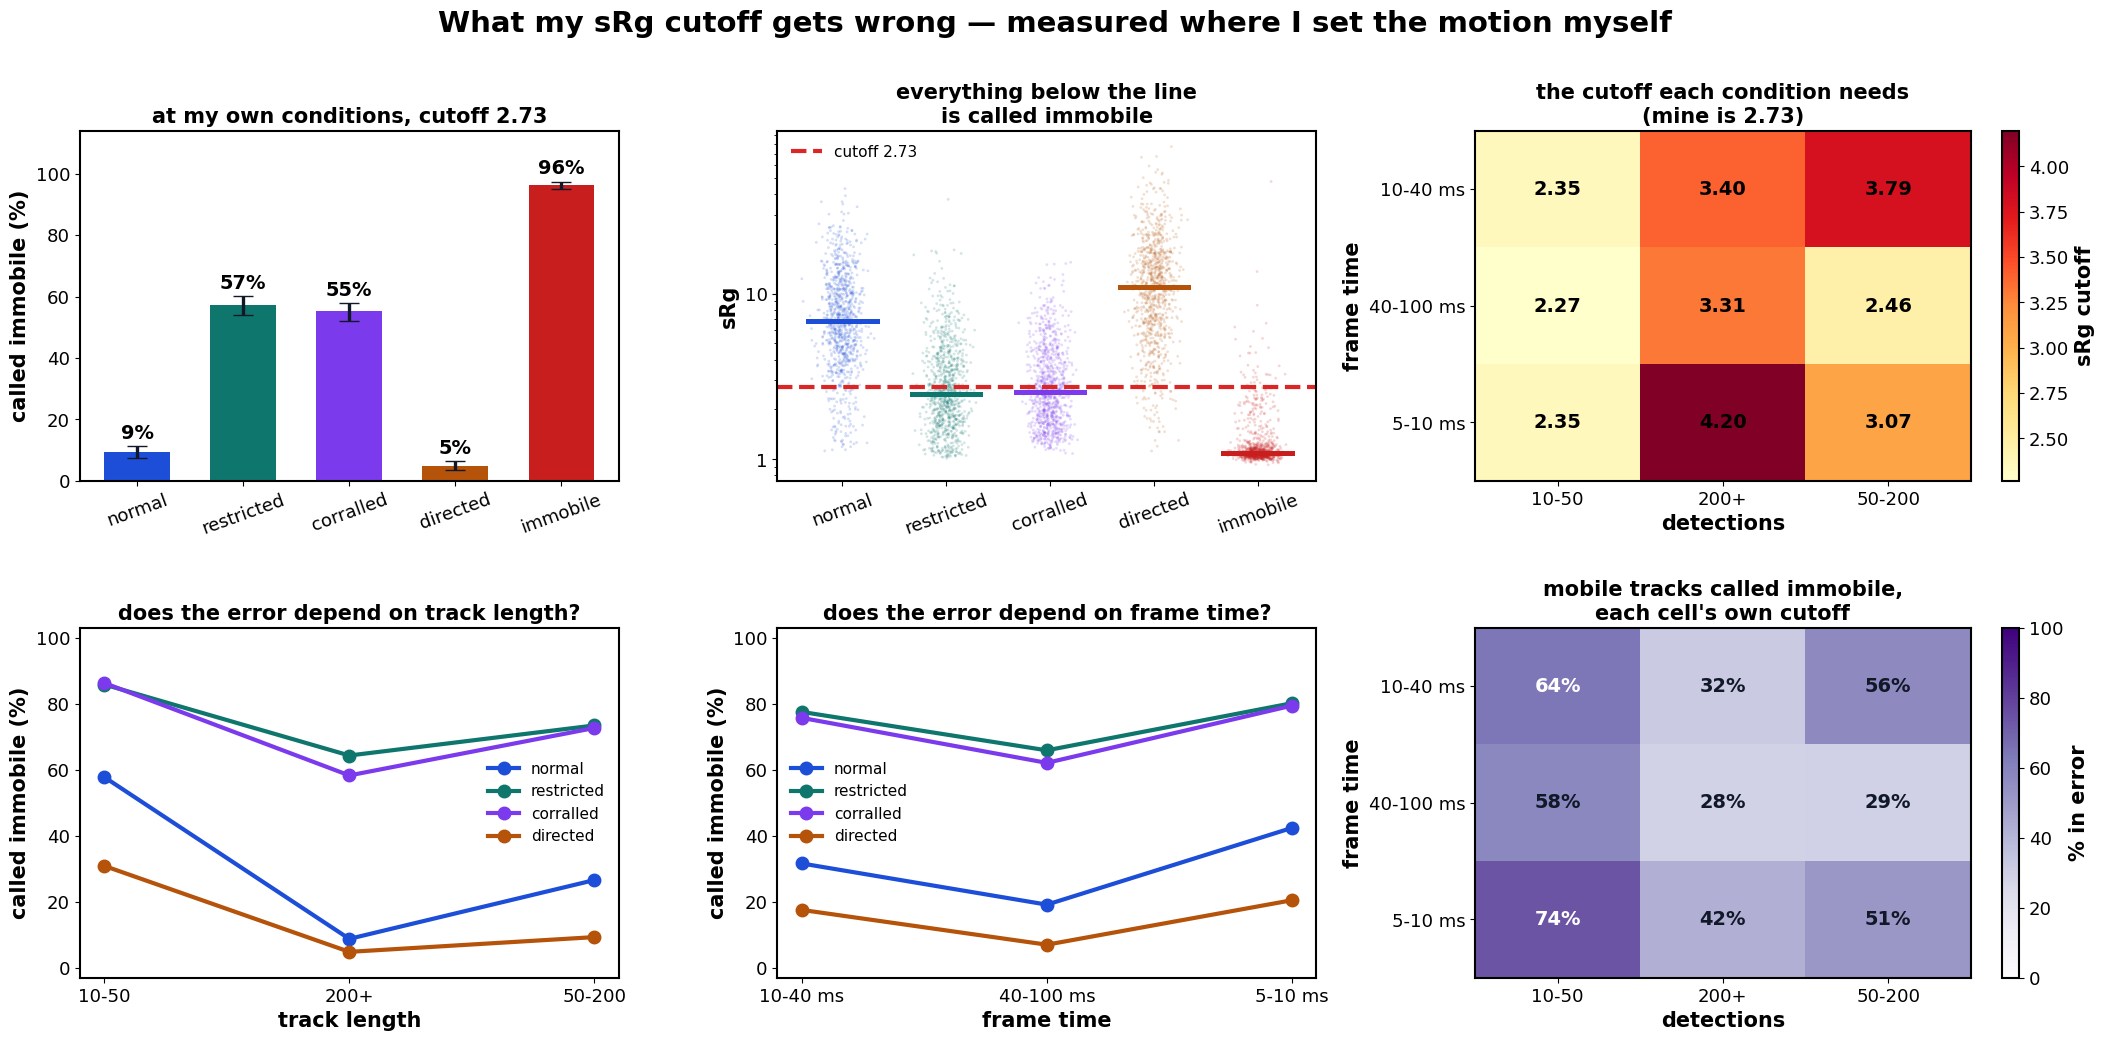

In [44]:
fig = plt.figure(figsize=(26, 11))
gs = fig.add_gridspec(2, 3, hspace=.42, wspace=.28, width_ratios=[1, 1, 1.15])
ax = fig.add_subplot(gs[0, 0])
E = ERR_MINE.reindex(CLASSES)
v = E["called immobile %"].to_numpy(float)
yerr = np.vstack([v - E.ci_lo.to_numpy(), E.ci_hi.to_numpy() - v])
bars = ax.bar(np.arange(5), v, yerr=yerr, capsize=7,
              color=[COL[k] for k in CLASSES], width=.62,
              error_kw=dict(lw=2.4, ecolor="#111827"))
for b, x_, hi__ in zip(bars, v, E.ci_hi.to_numpy()):
    ax.text(b.get_x() + b.get_width() / 2, hi__ + 2.5, f"{x_:.0f}%",
            ha="center", fontsize=14, fontweight="bold")
ax.set_xticks(np.arange(5)); ax.set_xticklabels(CLASSES, rotation=20)
ax.set_ylabel("called immobile (%)"); ax.set_ylim(0, 114)
ax.set_title(f"at my own conditions, cutoff {CUTOFF:.2f}", fontsize=15)
ax = fig.add_subplot(gs[0, 1])
for i, k in enumerate(CLASSES):
    s_ = S_REF_G.loc[S_REF_G.kind == k, "sRg"].dropna()
    ax.scatter(np.full(len(s_), i) + rng_global.normal(0, .10, len(s_)), s_, s=4,
               alpha=.18, color=COL[k], edgecolors="none")
    ax.plot([i - .33, i + .33], [s_.median()] * 2, lw=3.6, color=COL[k])
ax.axhline(CUTOFF, color="#dc2626", ls="--", lw=3, label=f"cutoff {CUTOFF:.2f}")
ax.set_yscale("log"); ax.yaxis.set_major_formatter(fmt)
ax.yaxis.set_minor_formatter(mpl.ticker.NullFormatter())
ax.set_xticks(np.arange(5)); ax.set_xticklabels(CLASSES, rotation=20)
ax.set_ylabel("sRg"); ax.set_title("everything below the line\nis called immobile",
                                   fontsize=15)
ax.legend(fontsize=11, frameon=False)
if len(CELLS):
    piv = CELLS.pivot(index="frame time", columns="detections", values="cutoff")
    ax = fig.add_subplot(gs[0, 2])
    im = ax.imshow(piv.to_numpy(), cmap="YlOrRd", aspect="auto")
    for i in range(piv.shape[0]):
        for j in range(piv.shape[1]):
            val = piv.iloc[i, j]
            if np.isfinite(val):
                ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=14,
                        fontweight="bold")
    ax.set_xticks(range(piv.shape[1])); ax.set_xticklabels(piv.columns)
    ax.set_yticks(range(piv.shape[0])); ax.set_yticklabels(piv.index)
    ax.set_xlabel("detections"); ax.set_ylabel("frame time")
    ax.set_title(f"the cutoff each condition needs\n(mine is {CUTOFF:.2f})",
                 fontsize=15)
    plt.colorbar(im, ax=ax, label="sRg cutoff")
    for ax_i, (col, lab) in enumerate([("detections", "track length"),
                                       ("frame time", "frame time")]):
        ax = fig.add_subplot(gs[1, ax_i])
        order = list(piv.columns if col == "detections" else piv.index)
        xs = np.arange(len(order))
        for k in CLASSES[:-1]:
            m = CELLS.groupby(col)[k].mean().reindex(order)
            ax.plot(xs, m.to_numpy(), "o-", lw=3, ms=9, color=COL[k], label=k)
        ax.set_xticks(xs); ax.set_xticklabels(order)
        ax.set_xlabel(lab); ax.set_ylabel("called immobile (%)")
        ax.set_ylim(-3, 103)
        ax.set_title(f"does the error depend on {lab}?", fontsize=15)
        ax.legend(fontsize=11, frameon=False)
    ax = fig.add_subplot(gs[1, 2])
    piv2 = CELLS.pivot(index="frame time", columns="detections",
                       values="all mobile").reindex(piv.index)[piv.columns]
    im = ax.imshow(piv2.to_numpy(), cmap="Purples", aspect="auto", vmin=0, vmax=100)
    for i in range(piv2.shape[0]):
        for j in range(piv2.shape[1]):
            val = piv2.iloc[i, j]
            if np.isfinite(val):
                ax.text(j, i, f"{val:.0f}%", ha="center", va="center", fontsize=14,
                        fontweight="bold", color="white" if val > 60 else "#111827")
    ax.set_xticks(range(piv2.shape[1])); ax.set_xticklabels(piv2.columns)
    ax.set_yticks(range(piv2.shape[0])); ax.set_yticklabels(piv2.index)
    ax.set_xlabel("detections"); ax.set_ylabel("frame time")
    ax.set_title("mobile tracks called immobile,\neach cell's own cutoff",
                 fontsize=15)
    plt.colorbar(im, ax=ax, label="% in error")
fig.suptitle("What my sRg cutoff gets wrong — measured where I set the motion "
             "myself", y=0.99)
fig.savefig(FIG_DIR / "S5_cutoff_error.png", bbox_inches="tight")

### How much does the mis-link rate matter?

The review asked for this: version 1's cutoff analysis rested on an inferred
14%. Version 2 uses the field simulation's 1.5%. Below, the same live
reference is rebuilt with the mis-link rate at 0, 1×, and the 7% and 14% that
version 1's reasoning pointed to, everything else fixed — and the simulated
fixed cells too, to show what each rate does to the gate.

In [45]:
SENS = []
for mult, lab in tqdm([(0.0, "none"), (1.0, "field simulation"),
                       (0.07 / max(mislink_rate(my_density), 1e-9), "7%"),
                       (0.14 / max(mislink_rate(my_density), 1e-9), "14% (v1)")],
                      desc="mis-link sensitivity"):
    MISLINK_MULT = mult
    try:
        keep_fid = _NEXT_FIELD_ID
        _NEXT_FIELD_ID = 60_000_000
        rT, rL = build({k: N_REF_MOB // 2 for k in CLASSES[:-1]}, False,
                       np.random.default_rng(SEED + 999), whole=True,
                       classes=CLASSES[:-1], donor="live", desc=lab)
        _NEXT_FIELD_ID = 61_000_000
        fT, fL = build(N_FIT, False, np.random.default_rng(SEED + 998),
                       classes=["immobile"], whole=True, donor="fixed", desc=lab)
        _NEXT_FIELD_ID = keep_fid
    finally:
        MISLINK_MULT = 1.0
    R_ = srg_of_sim(rT, rL, report=False); R_ = R_[R_.n_det_ >= MIN_TRACK_LEN]
    st = gate_stats(srg_of_sim(fT, fL, report=False))
    row = {"mis-link at my live density": lab,
           "rate %": round(100 * mult * mislink_rate(my_density), 2),
           "all mobile called immobile %": round(100 * (R_.sRg <= CUTOFF).mean(), 1)}
    for k in CLASSES[:-1]:
        row[k] = round(100 * (R_[R_.kind == k].sRg <= CUTOFF).mean(), 1)
    row.update({"gate median": round(st["median sRg"], 3),
                "gate 95th": round(st["95th sRg"], 3),
                "gate stretched %": round(st["stretched %"], 2)})
    SENS.append(row)
    del rT, rL, fT, fL
SENS = pd.DataFrame(SENS)
SENS.to_csv(TAB_DIR / "mislink_sensitivity.csv", index=False)
print(SENS.to_string(index=False))
print("\nThe fixed-cell columns use the fitted cluster parameters, which were")
print("fitted at the field-simulation rate; at other rates they would refit.")

mis-link sensitivity:   0%|          | 0/4 [00:00<?, ?it/s]

none:   0%|          | 0/2000 [00:00<?, ?it/s]

none:   0%|          | 0/3000 [00:00<?, ?it/s]

field simulation:   0%|          | 0/2000 [00:00<?, ?it/s]

field simulation:   0%|          | 0/3000 [00:00<?, ?it/s]

7%:   0%|          | 0/2000 [00:00<?, ?it/s]

7%:   0%|          | 0/3000 [00:00<?, ?it/s]

14% (v1):   0%|          | 0/2000 [00:00<?, ?it/s]

14% (v1):   0%|          | 0/3000 [00:00<?, ?it/s]

mis-link at my live density  rate %  all mobile called immobile %  normal  restricted  corralled  directed  gate median  gate 95th  gate stretched %
                       none    0.00                          31.8     9.6        59.5       53.3       4.7        1.104      2.720              6.78
           field simulation    1.53                          33.2    10.6        57.9       58.1       6.2        1.103      2.754              6.51
                         7%    7.00                          30.0    10.2        50.5       53.1       5.4        1.110      2.991              9.02
                   14% (v1)   14.00                          27.2     8.0        46.1       50.1       5.0        1.127      3.369             11.83

The fixed-cell columns use the fitted cluster parameters, which were
fitted at the field-simulation rate; at other rates they would refit.


## 6b. The plan's third check — my live reference against my real NB-Live

Run the same measures on the simulated live reference and on my real live
tracks, side by side: duty cycle, dark fraction, gaps per track, longest dark
state, Rg, step length, α, sRg. Every measure comes from one function
(`track_measures`, section 1) applied to both, on records of 200+
detections.

The reference is balanced by class and my cells are not, so the comparison
uses the reference **mixed at the composition my live data implies**: the
class shares whose sRg distributions add up to my real live sRg distribution
(non-negative least squares on the histogram). That composition is a
by-product of the motion models, not a measurement; the plan re-measures it
once a classifier exists.

The measures that were never tuned — duty, gaps, step, α — are the ones
that count.

In [46]:
from scipy.optimize import nnls
MEAS_REF, MSD_REF = measures_of(REF_TR, desc="simulated live measures")
MEAS_REF = MEAS_REF.merge(REF_LAB[["track_gid", "kind"]], on="track_gid")
MEAS_SFIX, MSD_SFIX = measures_of(FIXSIM, desc="simulated fixed measures")

_bins = np.logspace(np.log10(0.8), np.log10(60), 40)
h_real = np.histogram(MEAS_LIVE.sRg.dropna(), _bins)[0].astype(float)
h_real /= h_real.sum()
Hk = []
for k in CLASSES:
    h = np.histogram(MEAS_REF.loc[MEAS_REF.kind == k, "sRg"].dropna(), _bins)[0]
    Hk.append(h / max(h.sum(), 1))
w, resid = nnls(np.column_stack(Hk), h_real)
COMPOSITION = pd.Series(w / w.sum(), index=CLASSES).round(3)
COMPOSITION.rename("share").to_csv(TAB_DIR / "live_composition_implied.csv")
print("composition my live sRg distribution implies (provisional):")
print((100 * COMPOSITION).round(1).to_string())

_mrng = np.random.default_rng(SEED + 5)
_n = len(MEAS_LIVE)
idx = []
for k in CLASSES:
    pool = np.flatnonzero(MEAS_REF.kind.to_numpy() == k)
    m_ = int(round(COMPOSITION[k] * _n))
    if m_ and pool.size:
        idx.append(_mrng.choice(pool, m_, replace=True))
MIXED = MEAS_REF.iloc[np.concatenate(idx)].reset_index(drop=True)
MSD_MIXED = MSD_REF[np.concatenate(idx)]
mixed_ids = REF_LAB.set_index("track_gid").reindex(MIXED.track_gid)
MIXED_LAB = mixed_ids.reset_index()
MIXED_LAB.to_csv(OUT / "sim_reference_live_mixed_labels.csv", index=False)
print(f"\nmixed reference: {len(MIXED):,} records drawn from the live reference "
      f"(track ids saved, so it can be rebuilt from the parquet)")

MEASURES = [("duty", "duty cycle"), ("dark_frac", "dark fraction"),
            ("n_gaps", "gaps per track"), ("longest_gap", "longest dark (frames)"),
            ("n_det", "detections"), ("Rg_um", "Rg (um)"),
            ("step_um", "mean step (um)"), ("sRg", "sRg"),
            ("alpha_1_8", "alpha, lags 1-8")]
rows = []
for col, lab in MEASURES:
    a_, b_ = MEAS_LIVE[col].dropna(), MIXED[col].dropna()
    rows.append({"measure": lab, "real median": a_.median(), "sim median": b_.median(),
                 "diff %": 100 * (b_.median() - a_.median()) / a_.median()
                 if a_.median() else np.nan,
                 "real 10-90th": f"{a_.quantile(.1):.3g}-{a_.quantile(.9):.3g}",
                 "sim 10-90th": f"{b_.quantile(.1):.3g}-{b_.quantile(.9):.3g}",
                 "KS D": stats.ks_2samp(a_, b_).statistic})
SIDE = pd.DataFrame(rows).round(3)
SIDE.to_csv(TAB_DIR / "check3_live_side_by_side.csv", index=False)
print()
print(SIDE.to_string(index=False))
print("\nsRg was used to set the mixture, so its row agrees by construction;")
print("the others were not tuned.")

simulated live measures:   0%|          | 0/5000 [00:00<?, ?it/s]

simulated fixed measures:   0%|          | 0/5000 [00:00<?, ?it/s]

composition my live sRg distribution implies (provisional):
normal        70.7
restricted    28.3
corralled      0.0
directed       0.0
immobile       1.0

mixed reference: 2,392 records drawn from the live reference (track ids saved, so it can be rebuilt from the parquet)

              measure  real median  sim median  diff %  real 10-90th  sim 10-90th  KS D
           duty cycle        0.759       0.747  -1.607    0.513-0.94  0.498-0.935 0.033
        dark fraction        0.241       0.253   5.069  0.0595-0.487 0.0649-0.502 0.033
       gaps per track       73.000      74.000   1.370        24-244       26-255 0.033
longest dark (frames)       12.000      12.000   0.000          4-17         4-17 0.019
           detections      457.500     441.000  -3.607   225-1.9e+03 223-1.83e+03 0.028
              Rg (um)        0.294       0.315   7.054  0.0872-0.654 0.0933-0.884 0.098
       mean step (um)        0.071       0.076   5.967 0.0518-0.0866  0.054-0.096 0.163
                  sRg

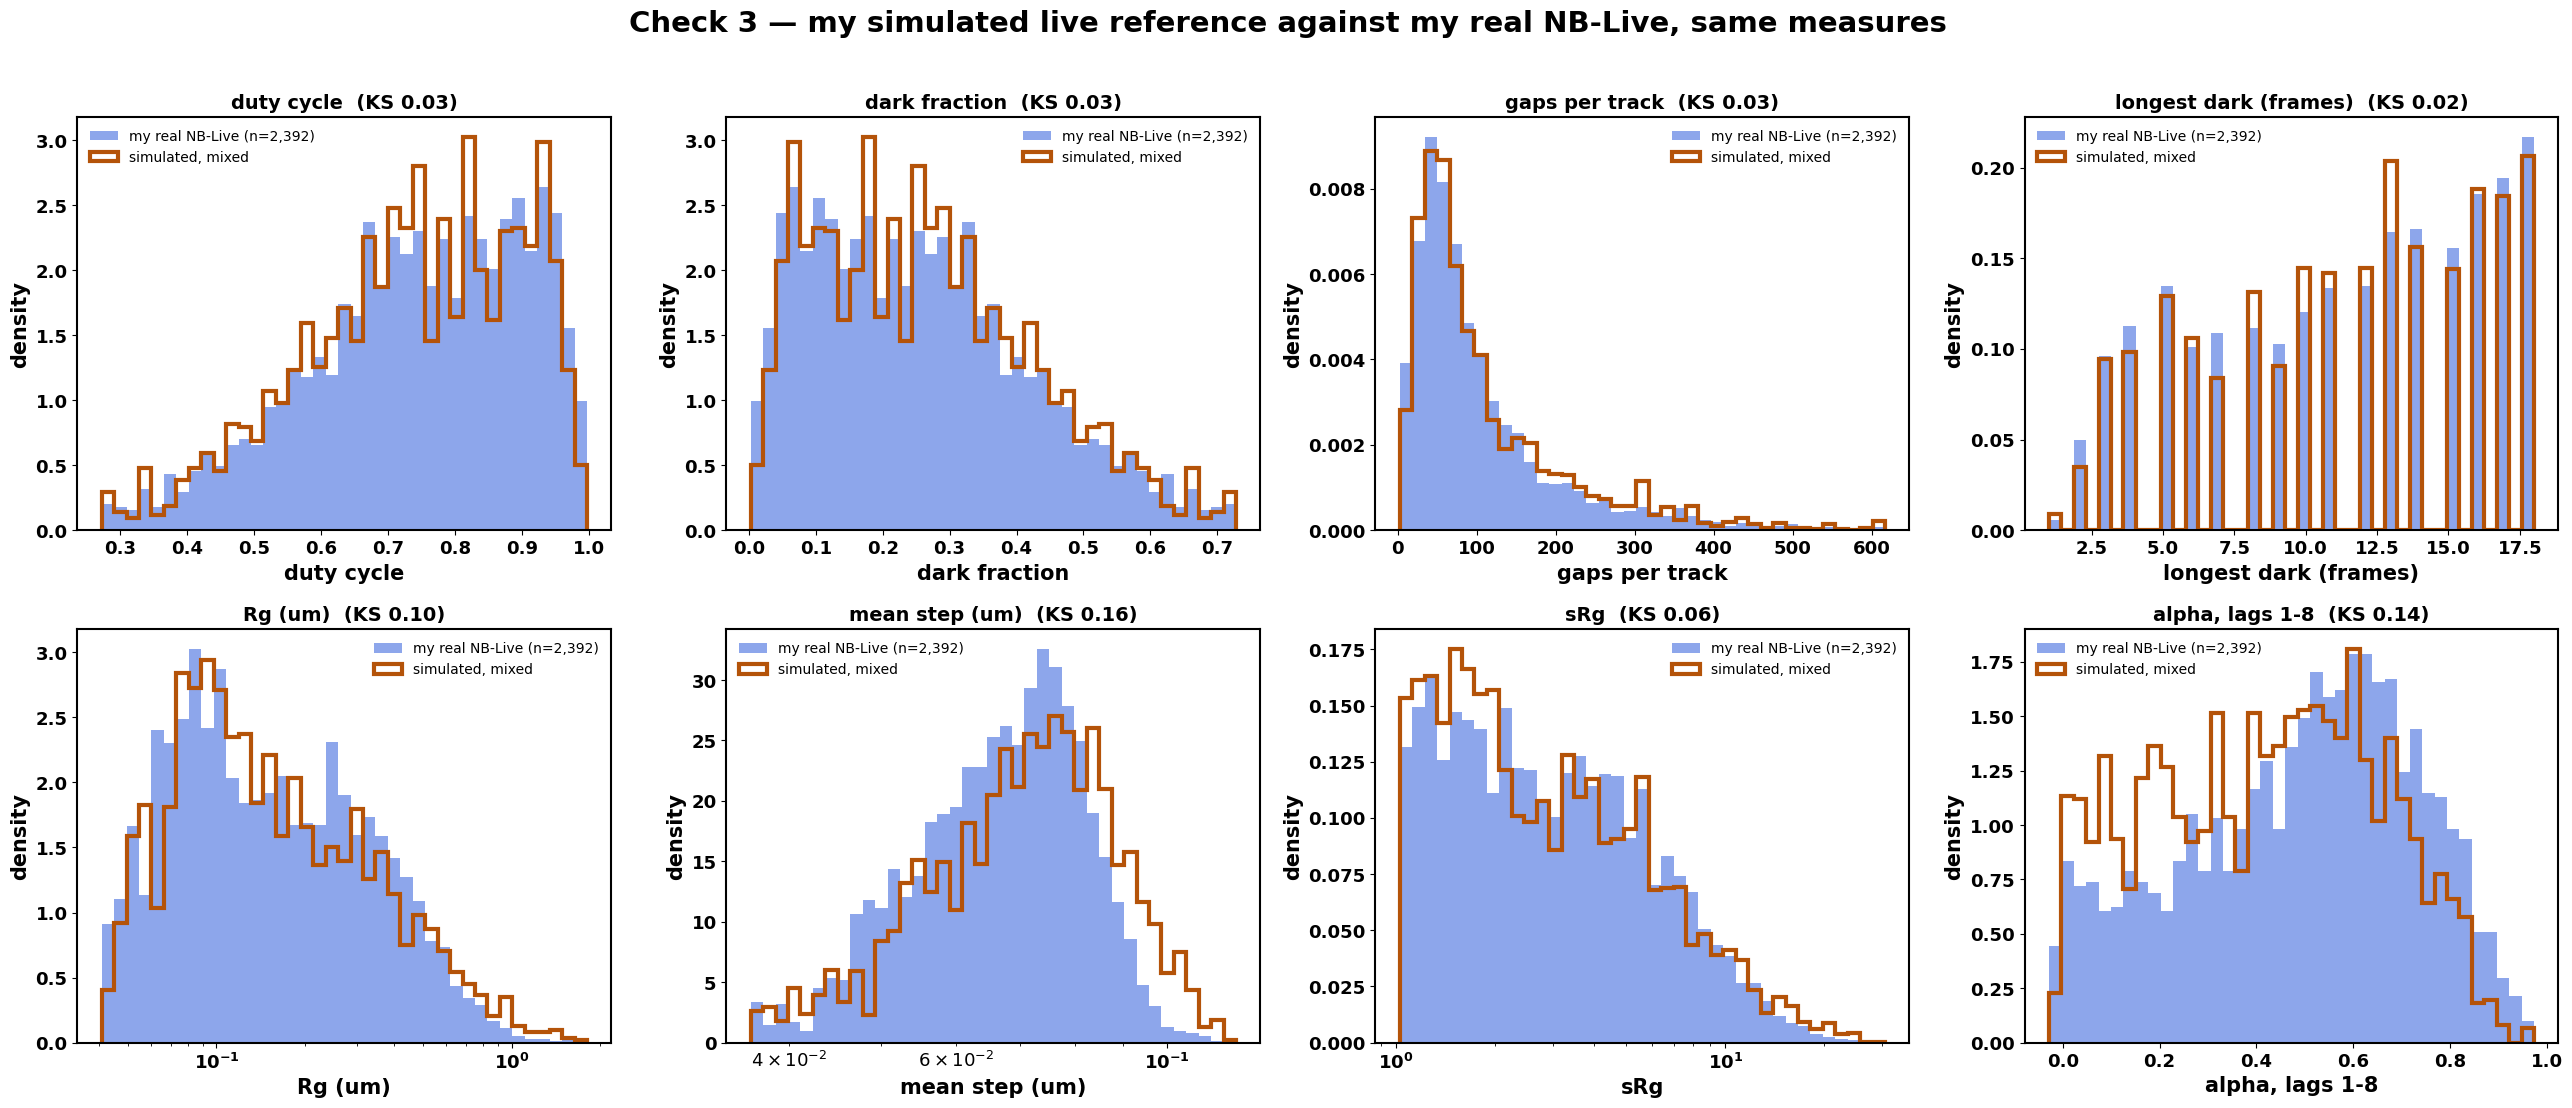

In [47]:
fig, axes = plt.subplots(2, 4, figsize=(26, 11))
for ax, (col, lab) in zip(axes.ravel(), [m for m in MEASURES if m[0] != "n_det"]):
    a_, b_ = MEAS_LIVE[col].dropna(), MIXED[col].dropna()
    lo, hi = np.nanquantile(np.r_[a_, b_], [.005, .995])
    logx = col in ("Rg_um", "step_um", "sRg")
    bins = (np.logspace(np.log10(max(lo, 1e-4)), np.log10(hi), 40) if logx
            else np.linspace(lo, hi, 40))
    ax.hist(a_, bins=bins, density=True, color=C_LIVE, alpha=.5,
            label=f"my real NB-Live (n={len(a_):,})")
    ax.hist(b_, bins=bins, density=True, histtype="step", lw=3, color=C_SIM,
            label="simulated, mixed")
    if logx:
        ax.set_xscale("log")
    ax.set_xlabel(lab); ax.set_ylabel("density")
    ax.set_title(f"{lab}  (KS {stats.ks_2samp(a_, b_).statistic:.2f})", fontsize=14)
    ax.legend(fontsize=10, frameon=False)
bold_ticks(*axes.ravel())
fig.suptitle("Check 3 — my simulated live reference against my real NB-Live, "
             "same measures", y=1.01)
fig.tight_layout()
fig.savefig(FIG_DIR / "S7_check3_live_side_by_side.png", bbox_inches="tight")

### MSD of each motion type alone, and with my own data over it

Ensemble MSD over records of 200+ detections, at my own conditions, so
localisation error, drift and blinking are all in it — this is what each
class *looks like* to my pipeline, not its textbook curve.

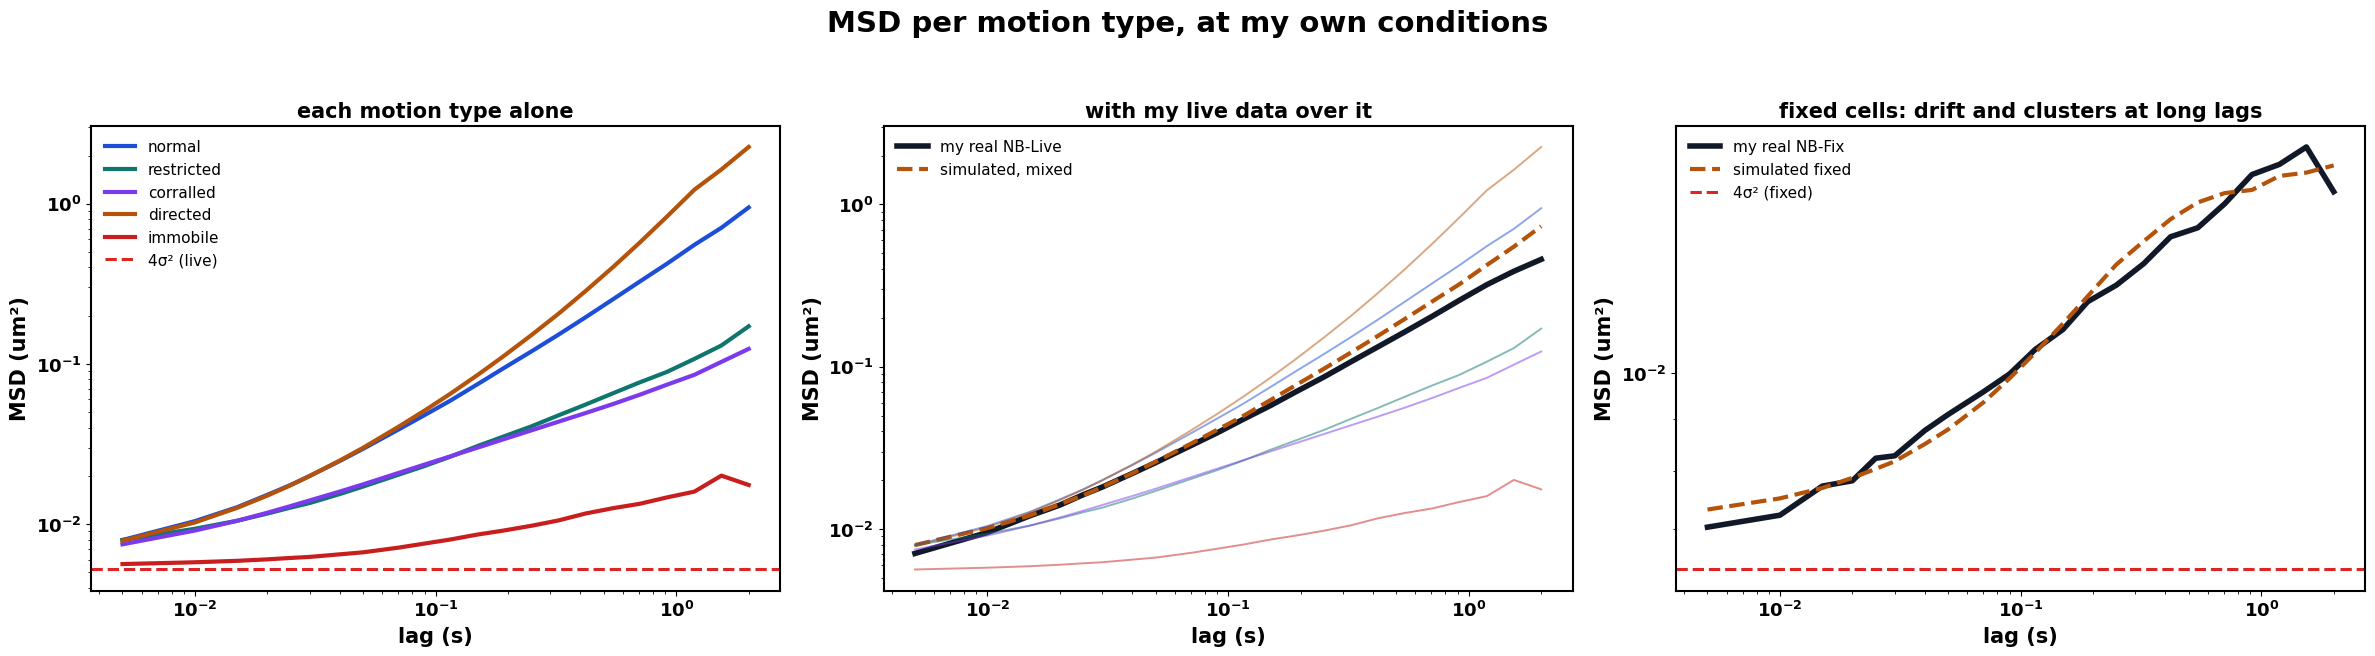

In [48]:
lag_s = MSD_LAGS * DT_S
rows = []
fig, axes = plt.subplots(1, 3, figsize=(24, 6.4))
ax = axes[0]
for k in CLASSES:
    sel = (MEAS_REF.kind == k).to_numpy()
    m = np.nanmean(MSD_REF[sel], axis=0)
    ax.plot(lag_s, m, lw=3, color=COL[k], label=k)
    rows += [{"set": f"simulated {k}", "lag_s": l, "msd_um2": v}
             for l, v in zip(lag_s, m)]
ax.axhline(4 * np.median(SIGMA_LIVE) ** 2, color="#dc2626", ls="--", lw=2.2,
           label="4σ² (live)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("lag (s)"); ax.set_ylabel("MSD (um²)")
ax.set_title("each motion type alone", fontsize=15)
ax.legend(fontsize=11, frameon=False)
ax = axes[1]
m_real = np.nanmean(MSD_LIVE, axis=0); m_mix = np.nanmean(MSD_MIXED, axis=0)
ax.plot(lag_s, m_real, lw=4, color="#111827", label="my real NB-Live")
ax.plot(lag_s, m_mix, lw=3, ls="--", color=C_SIM, label="simulated, mixed")
for k in CLASSES:
    sel = (MEAS_REF.kind == k).to_numpy()
    ax.plot(lag_s, np.nanmean(MSD_REF[sel], axis=0), lw=1.4, color=COL[k], alpha=.5)
rows += [{"set": "real NB-Live", "lag_s": l, "msd_um2": v} for l, v in zip(lag_s, m_real)]
rows += [{"set": "simulated live, mixed", "lag_s": l, "msd_um2": v}
         for l, v in zip(lag_s, m_mix)]
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("lag (s)"); ax.set_ylabel("MSD (um²)")
ax.set_title("with my live data over it", fontsize=15)
ax.legend(fontsize=11, frameon=False)
ax = axes[2]
m_rf = np.nanmean(MSD_FIX, axis=0); m_sf = np.nanmean(MSD_SFIX, axis=0)
ax.plot(lag_s, m_rf, lw=4, color="#111827", label="my real NB-Fix")
ax.plot(lag_s, m_sf, lw=3, ls="--", color=C_SIM, label="simulated fixed")
ax.axhline(4 * np.median(SIGMA) ** 2, color="#dc2626", ls="--", lw=2.2,
           label="4σ² (fixed)")
rows += [{"set": "real NB-Fix", "lag_s": l, "msd_um2": v} for l, v in zip(lag_s, m_rf)]
rows += [{"set": "simulated fixed", "lag_s": l, "msd_um2": v} for l, v in zip(lag_s, m_sf)]
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("lag (s)"); ax.set_ylabel("MSD (um²)")
ax.set_title("fixed cells: drift and clusters at long lags", fontsize=15)
ax.legend(fontsize=11, frameon=False)
bold_ticks(*axes)
fig.suptitle("MSD per motion type, at my own conditions", y=1.03)
fig.tight_layout()
fig.savefig(FIG_DIR / "S8_msd_per_class.png", bbox_inches="tight")
pd.DataFrame(rows).to_csv(TAB_DIR / "msd_per_class.csv", index=False)

In [49]:
# --- counts, the library summary, and the held-out set ------------------------
COUNTS = pd.concat([
    LIB_LAB.groupby("kind").agg(records=("track_gid", "size"),
                                molecules=("parent_gid", "nunique"))
        .assign(set="library"),
    REF_LAB.groupby("kind").agg(records=("track_gid", "size"),
                                molecules=("parent_gid", "nunique"))
        .assign(set="live reference"),
    S_REF_G.groupby("kind").agg(records=("track_gid", "size"),
                                molecules=("parent_gid", "nunique"))
        .assign(set="live reference, 200+"),
    FIXSIM_LAB.groupby("kind").agg(records=("track_gid", "size"),
                                   molecules=("parent_gid", "nunique"))
        .assign(set="fixed reference"),
]).reset_index()
COUNTS.to_csv(TAB_DIR / "counts.csv", index=False)
LIB_SUMMARY = LIB_LAB.groupby("kind").agg(
    records=("track_gid", "size"), dt_ms_median=("dt", lambda v: 1000 * v.median()),
    n_det_median=("n_det", "median"), duty_median=("duty", "median"),
    sigma_nm_median=("sigma_um", lambda v: 1000 * v.median()),
    D_median=("D", "median"), slow_share=("slow", "mean"),
    cluster_share=("is_cluster", "mean"), mislink_share=("is_mislink", "mean"),
    corrupted_share=("is_corrupted", "mean")).round(4)
LIB_SUMMARY.to_csv(TAB_DIR / "library_summary.csv")
print(COUNTS.to_string(index=False))
print()
print(LIB_SUMMARY.to_string())
_h = S_HELD[S_HELD.n_det_ >= MIN_TRACK_LEN]
print(f"\nheld-out obstacle tracks: {len(HELD_LAB):,} records; at my cutoff "
      f"{100*(_h.sRg <= CUTOFF).mean():.1f}% would be called immobile "
      f"(fGn restricted: {ERR_MINE.loc['restricted', 'called immobile %']}%)")

      kind  records  molecules                  set
 corralled     1019       1008              library
  directed     1017       1008              library
  immobile     5040       5002              library
    normal     1019       1008              library
restricted     1016       1008              library
 corralled     1000       1000       live reference
  directed     1000       1000       live reference
  immobile     1000       1000       live reference
    normal     1000       1000       live reference
restricted     1000       1000       live reference
 corralled      969        969 live reference, 200+
  directed      972        972 live reference, 200+
  immobile      967        967 live reference, 200+
    normal      972        972 live reference, 200+
restricted      970        970 live reference, 200+
  immobile     5000       5000      fixed reference

            records  dt_ms_median  n_det_median  duty_median  sigma_nm_median  D_median  slow_share  cluster_share 

## 7. What this produced, and what is not modelled

**Files**, in `ML/ML_Analysis/simulations_v2/`:

- `sim_library_*` — the training set: 5 classes × 9 frame-time × length
  cells, 5–100 ms, 10–5,000 detections, live donors
- `sim_reference_live_*` — my NB-Live conditions, 1,000 per class;
  `sim_reference_live_mixed_labels.csv` — the same tracks mixed at the
  composition my live data implies
- `sim_reference_fixed_*` — my NB-Fix conditions, 5,000 immobile: the gate
- `sim_heldout_obstacles_*` — obstructed diffusion, never to be trained on
- every parquet holds the observed `x_um, y_um` and the true path
  `x_true_um, y_true_um`; every label file holds the motion parameters, the
  recording conditions, `movie_id`, and per-record artefact flags
  (`is_cluster`, `is_mislink`, `is_merge`, `is_split`, `is_corrupted`) for the
  corruption output the plan asks the model for
- `sim_settings.json` — every parameter, the fitted ones and the seed
- tables: measured parameters, fitted parameters and every fit candidate,
  the gate (+ QQ, + seed units), the six-seed spread, artefact rates,
  exclusions, cutoff error (my conditions, per cell), mis-link sensitivity,
  check 3 side by side, implied live composition, MSD per class, counts,
  library summary, generator tests

**Declared as assumptions, not measurements:** the obstacle spacing
(20–60 nm); the detection threshold (on for half a frame); holding σ
constant across frame rates (no motion blur, no photon model); that a
mis-link is likelier across a dark gap (weight 1 per frame of gap); that a
mis-link's neighbour is any of the five classes with equal chance; that
clusters move rigidly with the molecule; and that merging and splitting
follow the field simulation's density curve.

**Not modelled, on purpose (plan, section 10).** Overlapping PSFs and
vanishing detections, which belong in a field simulation. Fragmentation in
the references: the borrowed blinking comes from already-linked tracks, so
it can never contain a dark stretch the linker gave up on — and until that is
simulated I cannot tell whether BAPTA's higher immobile fraction is biology
or tracking. Trapping. Realistic class proportions in the library.

**The immobile boundary** stays at the plan's 1.2 × 10⁻³ µm²/s. Over a 3 s
track it spreads about 120 nm rms, about 3σ — so the reason for it is "below
what one 3 s track separates from immobile", not "less than my localisation
error"; that wording would put it near 1.3 × 10⁻⁴.

**No windowing here.** Every simulated track has one motion class for its
whole life. Choosing a window length, rolling windows on tracks that switch,
and the mixed-motion tracks belong to notebook 02, because the right window
depends on the features and the model; that code is kept in
`_removed_windowing_for_notebook_02.py`.

**Next:** features (notebook 02) on the library, tested on the fixed
reference where I know the answer, then applied to live.

**Interpretation guardrail:** every number here is conditional on the motion
models, the parameter ranges, the borrowed blinking and the artefact
assumptions. They say how my cutoff behaves on these simulations; they are
not ground truth for live PIEZO1.